# Trend inflation from four US price measures with stochastic volatility

Inflation has a persistent part and a transitory part. The persistent part, **trend inflation**, is the rate that inflation returns to once the transitory shocks (an energy price spike, a pandemic quarter) have passed, and it is the number that a central bank and a bond investor care about. No price index measures it directly: each index measures the same underlying inflation with its own basket, formula and noise. In this notebook we estimate US trend inflation from four quarterly price measures, CPI, core CPI, PCE and core PCE, with one common random-walk trend, one transitory gap per measure, and **stochastic volatility**: the size of the trend shocks and of each gap is itself a random walk, so the model can be quiet in the 1990s and loud in the 1970s and in 2021 to 2023.

The model is a multi-measure version of the unobserved components stochastic volatility (UCSV) model of [Stock and Watson (2007)](https://doi.org/10.1111/j.1538-4616.2007.00014.x), close in spirit to [Stock and Watson (2016)](https://doi.org/10.1162/REST_a_00608) and [Mertens (2016)](https://doi.org/10.1162/REST_a_00549). It fits in the building blocks of `numpyro_forecast` without new code: [`innovations`](../../reference/models.innovations.html) samples the standardized steps of every random walk, [`predict`](../../reference/models.predict.html) takes an observation noise whose scale changes over time, and [`backtest`](../../reference/evaluate.backtest.html) runs the rolling-origin evaluation. The data ship with the package as [`load_us_inflation`](../../reference/datasets.load_us_inflation.html).

The notebook has three parts:

- **Estimation.** The model, its priors, a prior predictive check, the fit with NUTS, and the posterior of the trend, the volatilities and the measure offsets.
- **Forecast.** Core PCE inflation eight quarters ahead, with the stochastic volatility carried into the forecast bands.
- **Evaluation.** A rolling-origin backtest of a ladder of four models (constant variances, stochastic volatility, four measures, Student-t gaps) against the random-walk benchmark of [Atkeson and Ohanian (2001)](https://www.minneapolisfed.org/research/quarterly-review/are-phillips-curves-useful-for-forecasting-inflation), scored with the CRPS, the coverage and the MAE on core PCE.

The [VAR example](var.html) fits the same kind of quarterly US data with a vector autoregression; here the series share a latent component instead of lagged cross effects.

## Prepare notebook

In [1]:
import warnings

# preliz warns at import time when PyMC is not installed; this example does not use PyMC.
warnings.filterwarnings("ignore", message="PyMC not installed", category=UserWarning)

from functools import partial
from time import perf_counter

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import preliz as pz
import xarray as xr
from arviz_plots import PlotCollection
from jax import random
from jax.scipy.stats import norm
from matplotlib.collections import PolyCollection
from matplotlib.ticker import PercentFormatter
from numpyro.infer import MCMC, NUTS, Predictive

from numpyro_forecast import (
    BacktestResult,
    Horizon,
    backtest,
    eval_crps,
    eval_mae,
    forecast,
    innovations,
    predict,
    predictions_to_datatree,
    time_reparam,
    to_datatree,
)
from numpyro_forecast.datasets import load_us_inflation
from numpyro_forecast.metrics import crps_empirical
from numpyro_forecast.typing import Array, ForecastFn, ForecastModel, Metric, ModelFactory

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [12, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"
# arviz-plots warns whenever `aes` maps `alpha`, even to `["prob"]` as the plots below do.
warnings.filterwarnings(
    "ignore", message="When multiple credible intervals are plotted", category=UserWarning
)

numpyro.set_host_device_count(n=4)
rng_key = random.PRNGKey(seed=42)

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## Read data

The four series are the monthly, seasonally adjusted price indexes `CPIAUCSL`, `CPILFESL`, `PCEPI` and `PCEPILFE` from [FRED](https://fred.stlouisfed.org/), averaged over each quarter and turned into **annualized quarterly log inflation** in percent,

$$
\pi_{t, m} = 400 \, (\log P_{t, m} - \log P_{t-1, m}),
$$

where $P_{t, m}$ is the quarterly average level of measure $m$ in quarter $t$. The sample runs from 1959Q2 to 2026Q3, and the values are the revised data as published on 2026-11-08, not the real-time vintages a forecaster had at each date. The BLS published no CPI for October 2025 (the federal government shutdown of 2025), so that month of the two CPI series is filled with the geometric mean of September and November 2025 before the quarterly average, which splits the two-month price change evenly, as the BLS did in its November release.

Two conventions of the loader matter below:

- **Core PCE is the last column.** It is the measure the Federal Reserve targets, it is the reference measure of the model (its offset is zero, so the trend is on the core PCE scale) and it is the series we score in the evaluation.
- Time is at axis $-2$ and the measures at axis $-1$, the package layout, so the `(quarters, measures)` array is the `data` of every model call.

In [2]:
inflation = load_us_inflation()
rates = inflation.rates  # (quarters, measures), core PCE last
dates = inflation.dates  # first day of each quarter
num_quarters, num_measures = rates.shape
measure_labels = ("CPI", "core CPI", "PCE", "core PCE")
date_num = mdates.date2num(dates)  # matplotlib date numbers for plot_lm

assert inflation.names == ("cpi", "core_cpi", "pce", "core_pce")
assert rates.shape == (270, 4)

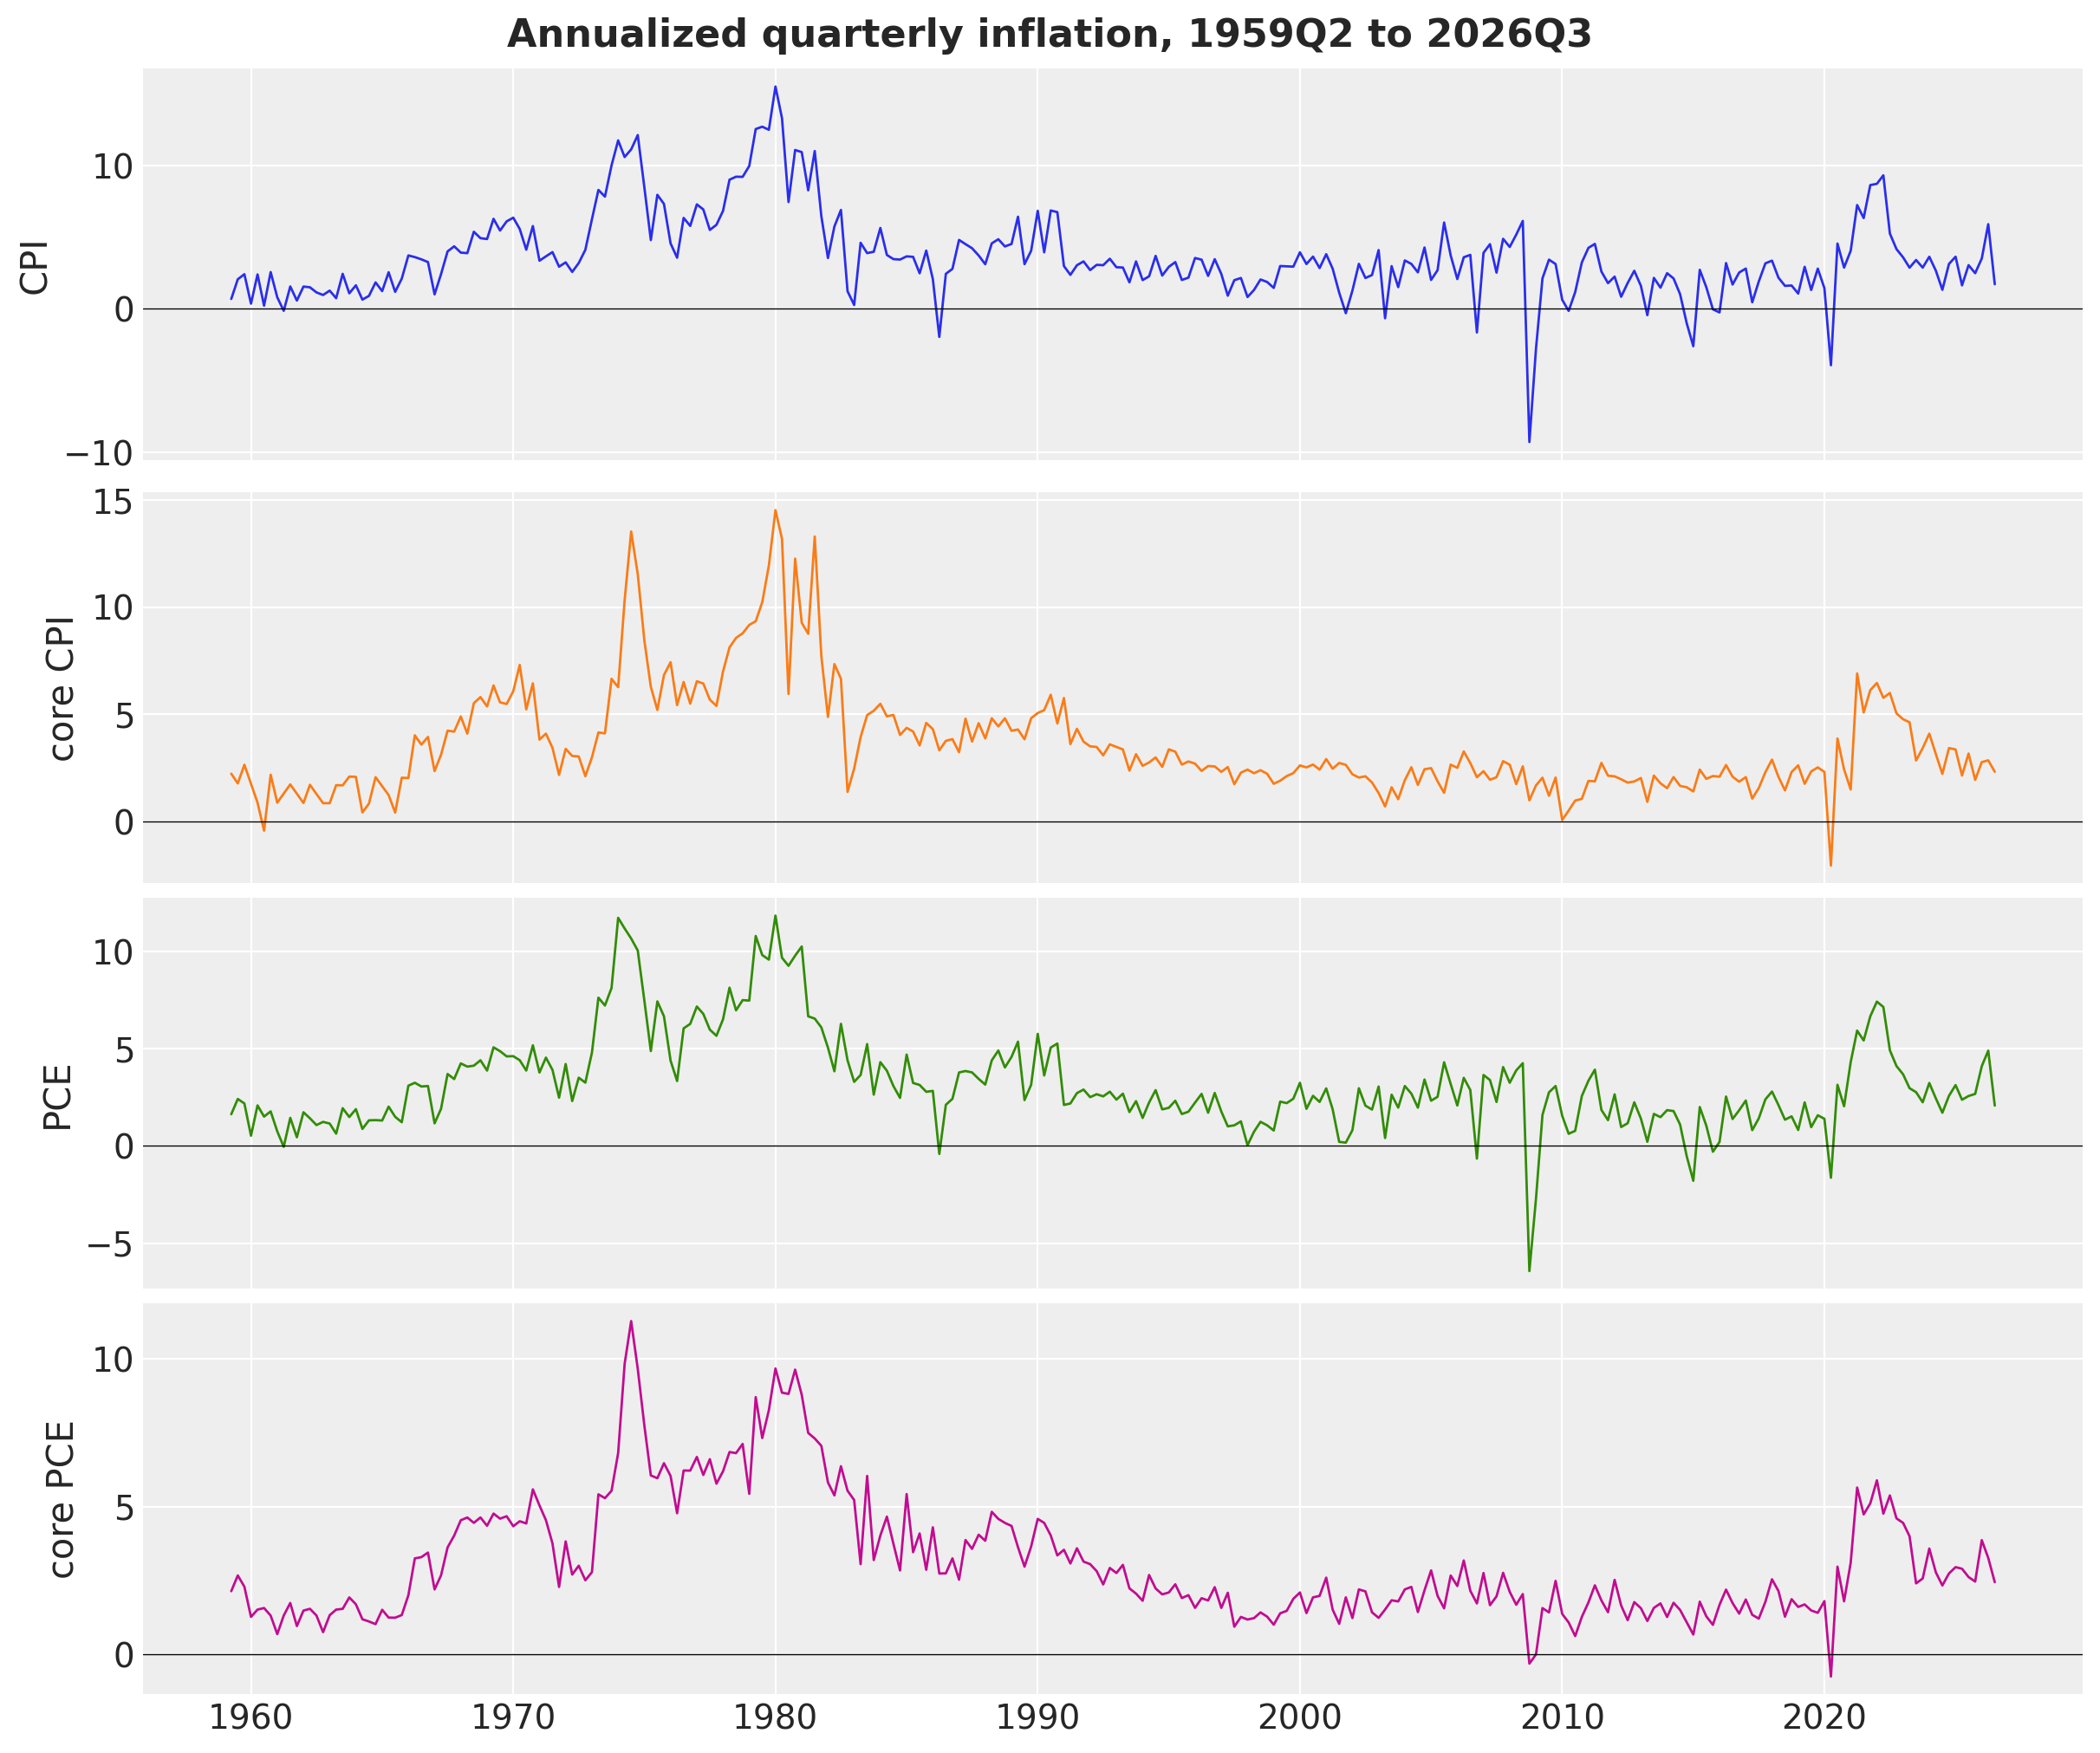

In [3]:
fig, axes = plt.subplots(nrows=num_measures, sharex=True, figsize=(12, 10), layout="constrained")

for ax, label, color, series in zip(
    axes, measure_labels, ("C0", "C1", "C2", "C3"), rates.T, strict=True
):
    ax.plot(dates, series, color=color, lw=1)
    ax.axhline(0.0, color="black", lw=0.5)
    ax.set(ylabel=label)

locator = mdates.AutoDateLocator()
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
fig.suptitle("Annualized quarterly inflation, 1959Q2 to 2026Q3", fontsize=16, fontweight="bold");

The four series move together, with different amplitudes:

- The 1970s have two peaks, around 1974 and 1980, where every measure reaches $10\%$ at least once: CPI peaks at $15.5\%$ in 1980Q1 and core PCE at $11.3\%$ in 1974Q3.
- The Great Moderation, from 1985 to 2007, keeps the four measures at an average of $2.5\%$ to $3.0\%$, and the core measures are visibly smoother than the headline ones.
- 2008Q4 is the quarter where the headline measures fall far below zero as oil prices collapse, CPI to $-9.3\%$ and PCE to $-6.4\%$, while the core measures stay near zero.
- 2021 to 2023 is the surge after the pandemic, with CPI at $9.3\%$ in 2022Q2 and core PCE at $5.9\%$ in 2022Q1, and 2020Q2 is the single-quarter dip before it, to $-3.9\%$ for CPI and $-0.8\%$ for core PCE.

From the mid 1980s on, the headline measures (CPI, PCE) swing more from quarter to quarter than their core counterparts, because food and energy prices are in their baskets, and CPI runs above PCE on average, because of the formula and weight differences between the two indexes. The model below has one parameter for the average wedge (the measure offset) and one time-varying scale per measure for the difference in noise.

## Evaluation metrics and the benchmark

The evaluation scores forecasts of core PCE inflation at horizons of one to eight quarters, in two forms: the eight quarterly rates themselves and the **4-quarter average**, the mean of the first four quarterly rates of the horizon, which is the quantity policy discussions use. The mean of four annualized quarterly log rates is exactly the annual log change, $100 \, (\log P_{t+4} - \log P_t)$, so the second form is the one-year inflation rate from the forecast origin.

We use three metrics:

- The **continuous ranked probability score** (CRPS) of [Gneiting and Raftery (2007)](https://doi.org/10.1198/016214506000001437) scores the whole forecast distribution. For a forecast with draws $X, X'$ and a realized value $y$ it is $\text{E}|X - y| - \tfrac{1}{2} \text{E}|X - X'|$, in percentage points: the first term rewards accuracy and the second rewards sharpness, and a point forecast with no spread scores its absolute error. Lower is better.
- The **coverage** of the central $50\%$ and $94\%$ intervals is the share of realized quarters inside the interval; a calibrated forecast lands at the nominal level.
- The **mean absolute error** (MAE) of the forecast median is the point-forecast score we can compare with a benchmark that has no distribution.

The benchmark is the random-walk forecast of [Atkeson and Ohanian (2001)](https://www.minneapolisfed.org/research/quarterly-review/are-phillips-curves-useful-for-forecasting-inflation): the average inflation of the last four quarters before the origin, held flat over the horizon. It is a point forecast with no model, and it is the standard hard benchmark in the inflation forecasting literature because the models that beat it on the 4-quarter average are few. We score it with the MAE on both forms of the target.

## Model specification

For quarter $t = 1, \dots, T$ and measure $m = 1, \dots, M$ with $M = 4$, the model is

$$
\begin{align*}
\pi_{t, m} &= \alpha_m + \tau_t + \varepsilon_{t, m}, & \varepsilon_{t, m} &\sim \text{Normal}\left(0, \exp(g_{t, m} / 2)\right), \\
\tau_t &= \tau_{t-1} + \exp(h_t / 2) \, z_t, & z_t &\sim \text{Normal}(0, 1), \\
h_t &= h_{t-1} + \gamma \, u_t, & u_t &\sim \text{Normal}(0, 1), \\
g_{t, m} &= g_{t-1, m} + \gamma \, v_{t, m}, & v_{t, m} &\sim \text{Normal}(0, 1),
\end{align*}
$$

where

- $\pi_{t, m}$ is the annualized quarterly inflation of measure $m$,
- $\tau_t$ is **trend inflation**, common to all measures,
- $\alpha_m$ is the **offset** of measure $m$ relative to core PCE, with $\alpha_M = 0$ for core PCE, which identifies the level of the trend (without it, a constant could move between the trend and the offsets),
- $\varepsilon_{t, m}$ is the transitory **gap** of measure $m$, independent across measures and over time given its scale,
- $h_t$ and $g_{t, m}$ are the **log-variances** of the trend shock and of each gap, random walks with the common **vol-of-vol** $\gamma$, the standard deviation of their steps.

The random walks are written in non-centered form: the model samples the standardized steps $z_t$, $u_t$ and $v_{t, m}$ and builds the paths with a cumulative sum, so the latent paths are deterministic functions of unit normals and no reparameterization is needed. The trend and the four gaps are the two components of every measure, and the trend is the part that all four share.

The priors are

$$
\begin{align*}
\alpha_m &\sim \text{Normal}(0, 1), \quad m < M, \\
\tau_0 &\sim \text{Normal}(3, 2), \\
h_0 &\sim \text{Normal}(-1.5, 1), \\
g_{0, m} &\sim \text{Normal}(0, 1), \\
\gamma &= 0.1 \quad \text{(fixed)}.
\end{align*}
$$

On the scale of the data, where a typical quarter of core inflation sits between $1\%$ and $5\%$:

- $\tau_0 \sim \text{Normal}(3, 2)$ puts the trend at the start of the sample between $-1\%$ and $7\%$ with $95\%$ probability, which covers the late 1950s.
- $h_0 = -1.5$ is a trend shock with standard deviation $\exp(-0.75) \approx 0.47$ percentage points per quarter, and the prior standard deviation of $1$ on $h_0$ lets that scale range from about $0.3$ to $0.8$ within one standard deviation.
- $g_{0, m} = 0$ is a gap with a standard deviation of $1$ percentage point, the right order for the core measures; the headline measures move up from there through $g_{t, m}$.
- $\alpha_m \sim \text{Normal}(0, 1)$ allows offsets of about $\pm 2$ percentage points, which is wide for the CPI to PCE wedge of a few tenths.
- $\gamma$ is fixed, as in Stock and Watson (2007). After $t$ quarters the log-variance has prior standard deviation $\gamma \sqrt{t}$, about $1.6$ for $\gamma = 0.1$ and $t = 270$, so a volatility can drift by a factor of $\exp(0.82) \approx 2.3$ in either direction over the sample within one standard deviation. The fourth panel of the prior figure plots this band, the quantity that $\gamma$ controls. We fix $\gamma$ instead of learning it because the data say little about it: the *Sensitivity to the vol-of-vol* section fits the model with a prior on $\gamma$ and shows what the posterior does.

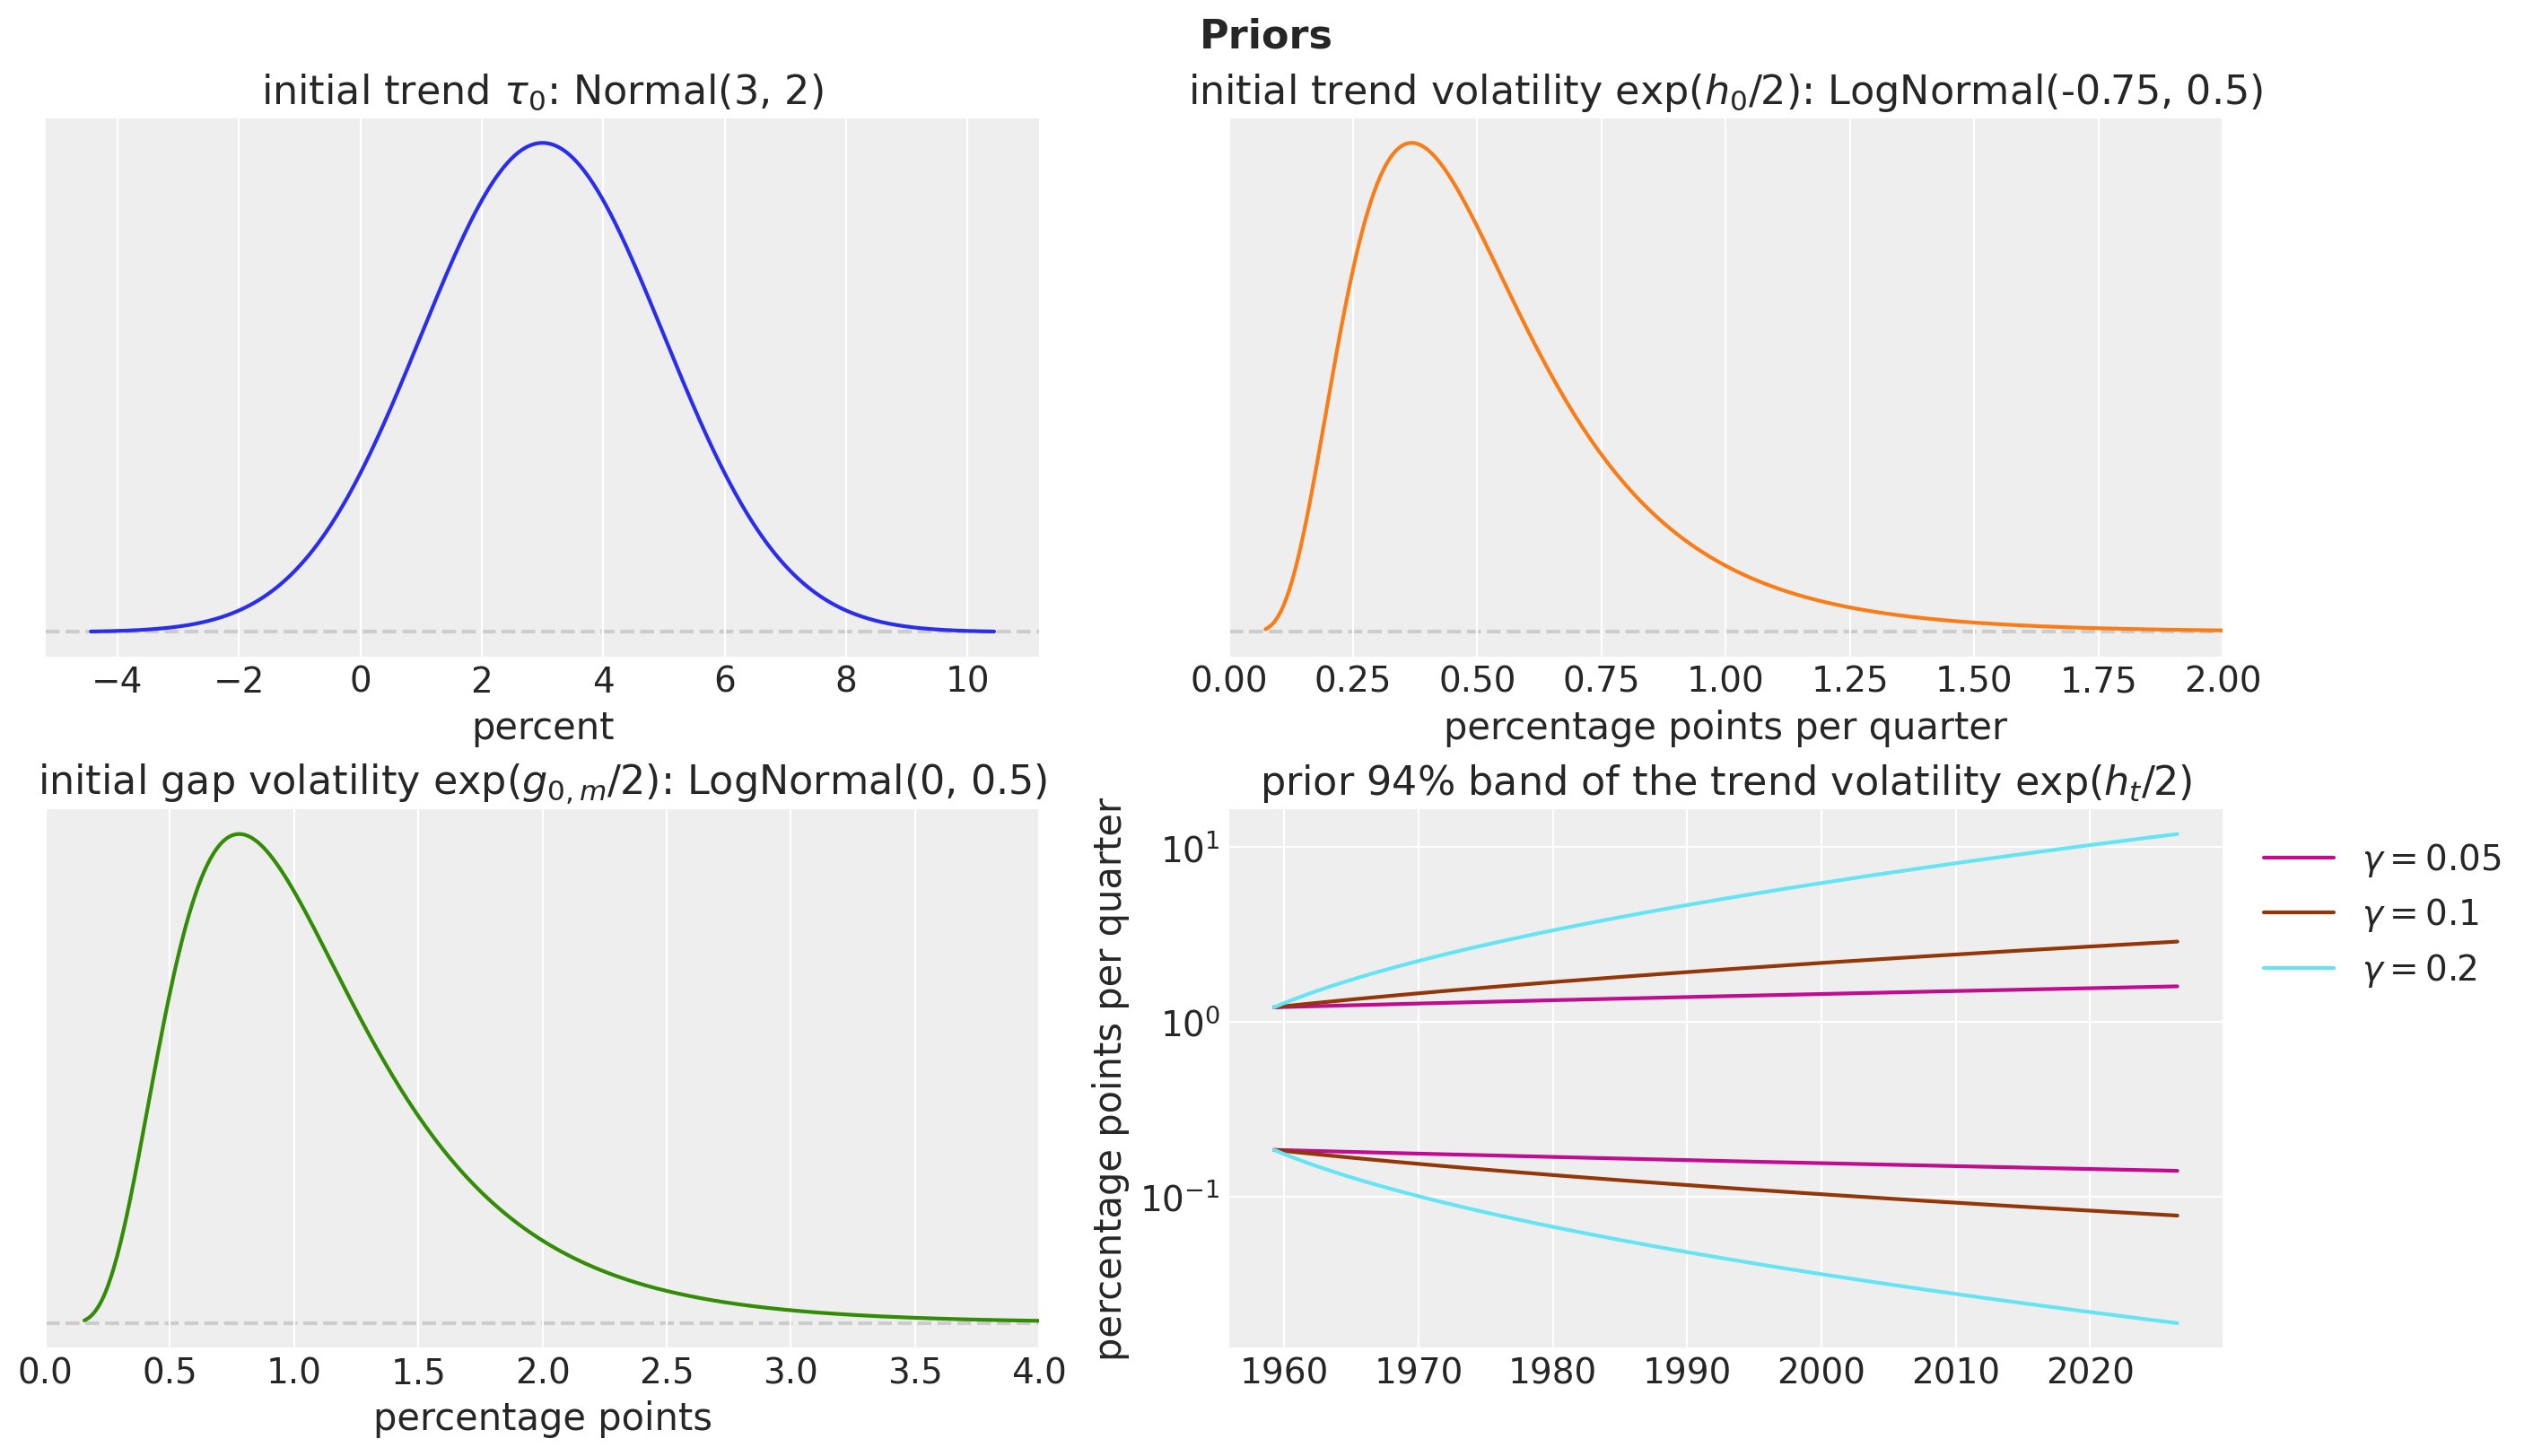

In [4]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 8), layout="constrained")
pz.Normal(3, 2).plot_pdf(ax=axes[0, 0], color="C0", legend=None)
axes[0, 0].set(title=r"initial trend $\tau_0$: Normal(3, 2)", xlabel="percent")
pz.LogNormal(-0.75, 0.5).plot_pdf(ax=axes[0, 1], color="C1", legend=None)
axes[0, 1].set(
    title=r"initial trend volatility $\exp(h_0 / 2)$: LogNormal(-0.75, 0.5)",
    xlabel="percentage points per quarter",
    xlim=(0, 2),
)
pz.LogNormal(0, 0.5).plot_pdf(ax=axes[1, 0], color="C2", legend=None)
axes[1, 0].set(
    title=r"initial gap volatility $\exp(g_{0, m} / 2)$: LogNormal(0, 0.5)",
    xlabel="percentage points",
    xlim=(0, 4),
)

# Prior 94% band of the trend volatility exp(h_t / 2) after t quarters, for three vol-of-vol
# values: h_t ~ Normal(-1.5, sqrt(1 + gamma^2 t)), so the band is
# exp((-1.5 +/- z sqrt(1 + gamma^2 t)) / 2).
steps = jnp.arange(num_quarters)  # (quarters,)
z_97 = norm.ppf(0.97)

for color, gamma in zip(("C3", "C4", "C5"), (0.05, 0.1, 0.2), strict=True):
    half_width = z_97 * jnp.sqrt(1.0 + gamma**2 * steps)  # (quarters,)
    axes[1, 1].plot(
        dates, jnp.exp((-1.5 + half_width) / 2.0), color=color, label=rf"$\gamma = {gamma}$"
    )
    axes[1, 1].plot(dates, jnp.exp((-1.5 - half_width) / 2.0), color=color)

axes[1, 1].set(
    title=r"prior $94\%$ band of the trend volatility $\exp(h_t / 2)$",
    ylabel="percentage points per quarter",
    yscale="log",
)
axes[1, 1].legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.suptitle("Priors", fontsize=16, fontweight="bold");

The three densities are the priors on the initial values, on the scale of the data: a trend between $-1\%$ and $7\%$, a trend shock of $0.2$ to $1.2$ percentage points per quarter, a gap of $0.4$ to $2.6$ points. The fourth panel shows the consequence of the fixed $\gamma$. With $\gamma = 0.1$ the $94\%$ prior band of the trend volatility widens from $0.18$ to $1.2$ points per quarter in 1959 to $0.08$ to $2.9$ in 2026: the prior lets the volatility fall or rise by a factor of about $2.4$ over the sample and says nothing about when. With $\gamma = 0.05$ the band ends at $0.14$ to $1.6$, close to where it started. With $\gamma = 0.2$ it ends at $0.02$ to $12$, where the prior stops constraining the path and the posterior has to find it on its own.

## The model function

The model is one function with three switches, so that the ladder of the evaluation changes no code:

- `num_measures` is $M$; with `num_measures=1` there is no offset and the model is the univariate UCSV of Stock and Watson (2007).
- `stochastic_volatility=False` freezes $h_t = h_0$ and $g_{t, m} = g_{0, m}$: constant variances.
- `student_t=True` replaces the Normal gaps with Student-t gaps $\varepsilon_{t, m} \sim \text{StudentT}(\nu, 0, \exp(g_{t, m} / 2))$ with $\nu \sim \text{Gamma}(10, 1)$, a prior centered at $10$ degrees of freedom with a standard deviation of about $3$.

The model reads no covariates. [`Horizon.from_data`](../../reference/models.Horizon.html) takes the duration from the `covariates` array, so the training call passes `jnp.zeros((num_quarters, 0))` and a forecast call passes an array with eight more rows. Every random walk is a cumulative sum of standardized steps from `innovations`, which samples the in-sample steps under the `time` plate and, when the covariates are longer than the data, the horizon steps at a separate `_future` site. The gap volatility `gap_vol` has a time axis, and `predict` accepts a noise distribution whose scale varies over the full horizon, so the stochastic volatility propagates into the forecast without any extra code.

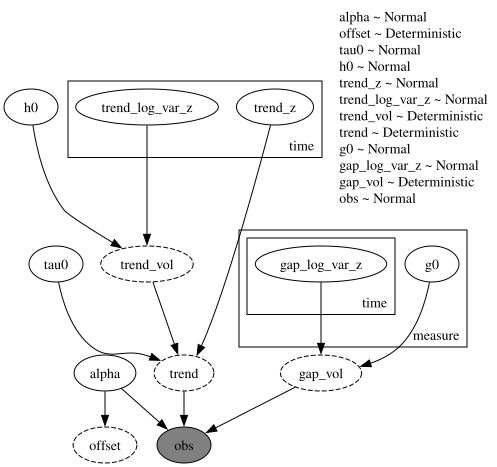

In [5]:
def make_trend_inflation_model(
    num_measures: int,
    *,
    vol_of_vol: float | Array = 0.1,
    stochastic_volatility: bool = True,
    student_t: bool = False,
) -> ForecastModel:
    """Build the trend inflation model: common trend, measure offsets, stochastic volatility."""

    def trend_inflation_model(covariates: Array, data: Array | None = None) -> None:
        """Trend inflation model for ``data`` shaped ``(duration, num_measures)``."""
        h = Horizon.from_data(covariates, data)
        measure_plate = numpyro.plate("measure", num_measures, dim=-1)

        # Offsets relative to the last measure (core PCE), whose offset is zero: (num_measures,)
        if num_measures > 1:
            alpha = numpyro.sample(
                "alpha", dist.Normal(0.0, 1.0).expand([num_measures - 1]).to_event(1)
            )
            offset = jnp.concatenate([alpha, jnp.zeros(1)])
        else:
            offset = jnp.zeros(1)
        numpyro.deterministic("offset", offset)

        # Trend: a random walk whose log-variance is a random walk. Shapes (duration, 1).
        tau0 = numpyro.sample("tau0", dist.Normal(3.0, 2.0))
        h0 = numpyro.sample("h0", dist.Normal(-1.5, 1.0))
        trend_z = innovations(h, "trend_z", dist.Normal(0.0, 1.0))
        if stochastic_volatility:
            trend_log_var_z = innovations(h, "trend_log_var_z", dist.Normal(0.0, 1.0))
            log_var_trend = h0 + vol_of_vol * jnp.cumsum(trend_log_var_z, axis=-2)
        else:
            log_var_trend = h0 * jnp.ones_like(trend_z)
        trend_vol = numpyro.deterministic("trend_vol", jnp.exp(log_var_trend / 2.0))
        trend = numpyro.deterministic("trend", tau0 + jnp.cumsum(trend_vol * trend_z, axis=-2))

        # Gaps: one log-variance random walk per measure. Shapes (duration, num_measures).
        with measure_plate:
            g0 = numpyro.sample("g0", dist.Normal(0.0, 1.0))
        if stochastic_volatility:
            with measure_plate:
                gap_log_var_z = innovations(h, "gap_log_var_z", dist.Normal(0.0, 1.0))
            log_var_gap = g0 + vol_of_vol * jnp.cumsum(gap_log_var_z, axis=-2)
        else:
            log_var_gap = jnp.broadcast_to(g0, (h.duration, num_measures))
        gap_vol = numpyro.deterministic("gap_vol", jnp.exp(log_var_gap / 2.0))

        # (duration, 1) trend + (num_measures,) offsets -> (duration, num_measures) predictor
        prediction = trend + offset
        if student_t:
            nu = numpyro.sample("nu", dist.Gamma(10.0, 1.0))
            predict(h, dist.StudentT(nu, 0.0, gap_vol), prediction)
        else:
            predict(h, dist.Normal(0.0, gap_vol), prediction)

    return trend_inflation_model


HORIZON = 8
covariates_train = jnp.zeros((num_quarters, 0))  # (quarters, 0): only the duration is read
covariates_full = jnp.zeros((num_quarters + HORIZON, 0))  # (quarters + 8, 0): adds the horizon

model = make_trend_inflation_model(num_measures)
numpyro.render_model(model, model_args=(covariates_train, rates), render_distributions=True)

## Prior predictive check

Before the data, we draw core PCE inflation from the priors over the whole sample and compare its band with the observed series. The band should contain the data with room to spare, and it should not contain values that no price index has ever produced.

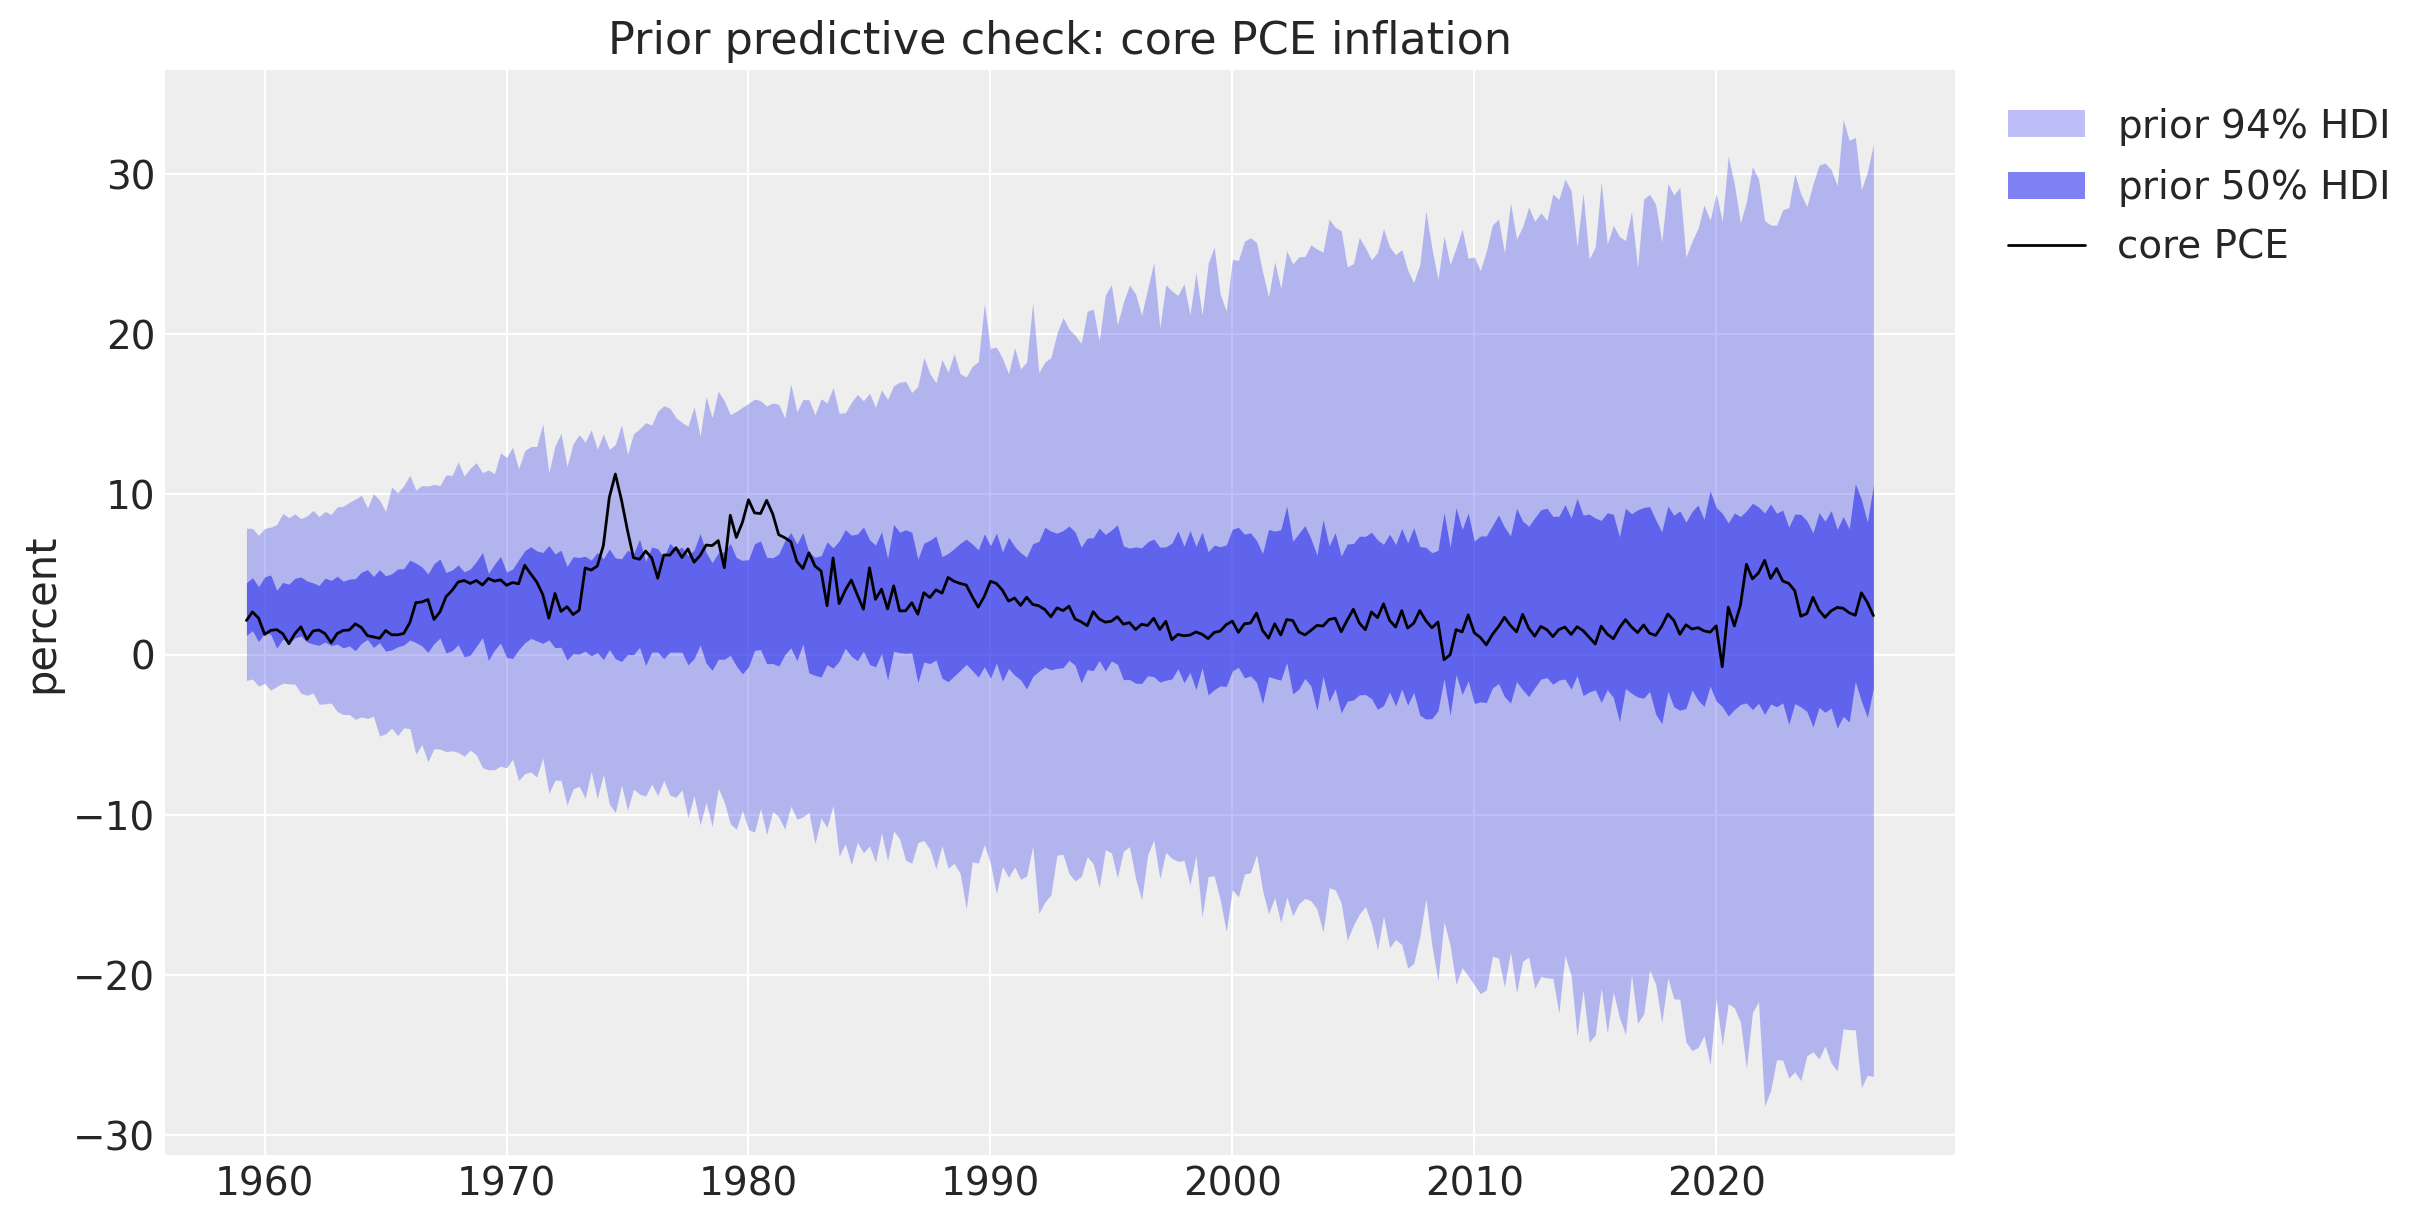

In [6]:
HDI_PROBS = (0.94, 0.5)
HDI_ALPHAS = (0.3, 0.6)


def hdi_label(prob: float) -> str:
    r"""Legend label of an HDI band, for example ``$94\%$ HDI``."""
    return rf"${prob:.0%}$ HDI".replace("%", r"\%")


rng_key, key_prior = random.split(rng_key)
prior_obs = Predictive(model, num_samples=1_000, return_sites=["obs"])(
    key_prior, covariates_train
)["obs"]  # (draws, quarters, measures)

prior_tree = predictions_to_datatree(
    prior_obs[:, :, -1:],
    date_num,
    ["core PCE"],
    group="prior_predictive",
    observed=rates[:, -1:],
)
pc = az.plot_lm(
    prior_tree,
    y="obs",
    x="t",
    plot_dim="time",
    group="prior_predictive",
    ci_kind="hdi",
    ci_prob=HDI_PROBS,
    smooth=False,
    visuals={
        "ci_band": {"color": "C0"},
        "observed_scatter": False,
        "pe_line": False,
        "xlabel": False,
        "ylabel": False,
    },
    aes={"alpha": ["prob"]},
    alpha=HDI_ALPHAS,
    figure_kwargs={"figsize": (12, 6)},
)
ax = pc.viz["figure"].item().axes[0]
(observed_line,) = ax.plot(date_num, rates[:, -1], color="black", lw=1, label="core PCE")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
band_handles = []

for prob in HDI_PROBS:
    band = pc.viz["ci_band"]["t"].sel(prob=prob).item()
    band.set_label(f"prior {hdi_label(prob)}")
    band_handles.append(band)

ax.legend(handles=[*band_handles, observed_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(title="Prior predictive check: core PCE inflation", ylabel="percent");

The prior band widens with time, because both random walks accumulate variance. In 1959Q2 the $94\%$ band of core PCE inflation runs from $-1.6\%$ to $7.9\%$; in 1980Q1 from $-11\%$ to $16\%$; in 2026Q3 from $-26\%$ to $32\%$, and even the $50\%$ band spans $-4\%$ to $9\%$ there. The first criterion holds: the data stay inside the band everywhere, the 1980 peak of $9.7\%$ included. The second fails in the last decades, because the band allows annualized rates of $-26\%$ that no US price index has produced in a quarter, and we accept that. The priors are weak on purpose: the posterior has to decide how volatile the trend and the gaps are at each date, and the only thing fixed is how fast that volatility can change.

## Inference with NUTS

We sample the posterior with four NUTS chains of $1{,}000$ warmup and $1{,}000$ draws each. The model has about $1{,}630$ latent dimensions (six standardized random walks of 270 steps: the trend steps, the trend log-variance and the four gap log-variances, plus the initial values and the offsets), all continuous, and the non-centered form keeps the geometry regular enough for the default settings except for one knob: `target_accept_prob` is $0.9$ instead of its default of $0.8$, which shortens the leapfrog steps around a funnel where a gap volatility approaches zero. A scratch run at the default had more divergent transitions and the same posterior. The figure after the trace plot shows where the remaining divergent transitions sit.

The fit returns the `MCMC` object and the wall time. `export` turns the posterior into an ArviZ `DataTree` with [`to_datatree`](../../reference/convert.to_datatree.html): the four chains, the in-sample posterior predictive, the eight-quarter forecast (because `covariates_full` extends past the data) and the quarter dates as the `time` coordinate, with the measure names on every site that has a measure axis.

In [7]:
NUM_CHAINS = 4
FULL_WARMUP = 1_000
FULL_SAMPLES = 1_000
TARGET_ACCEPT = 0.9


def fit_nuts(
    rng_key: Array, model: ForecastModel, data: Array, *, num_warmup: int, num_samples: int
) -> tuple[MCMC, float]:
    """Fit ``model`` with NUTS and return the sampler and the wall time in seconds."""
    mcmc = MCMC(
        NUTS(model, target_accept_prob=TARGET_ACCEPT),
        num_warmup=num_warmup,
        num_samples=num_samples,
        num_chains=NUM_CHAINS,
        progress_bar=False,
    )
    start = perf_counter()
    mcmc.run(rng_key, jnp.zeros((data.shape[0], 0)), data, extra_fields=("diverging",))
    jax.block_until_ready(mcmc.get_samples())
    return mcmc, perf_counter() - start


rng_key, key_fit = random.split(rng_key)
mcmc, seconds = fit_nuts(key_fit, model, rates, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES)

In [8]:
future_dates = (dates[-1].astype("datetime64[M]") + 3 * np.arange(1, HORIZON + 1)).astype(
    "datetime64[D]"
)
future_date_num = mdates.date2num(future_dates)
time_coord = np.concatenate([dates, future_dates])
posterior_dims = {
    "trend": ["time"],
    "trend_vol": ["time"],
    "gap_vol": ["time", "measure"],
    "g0": ["measure"],
    "offset": ["measure"],
    "alpha": ["free_measure"],
}


def export(rng_key: Array, model: ForecastModel, mcmc: MCMC) -> xr.DataTree:
    """Posterior, in-sample predictive and forecast draws as a labeled ArviZ tree."""
    return to_datatree(
        rng_key,
        model,
        mcmc.get_samples(),
        rates,
        covariates_full,
        num_chains=NUM_CHAINS,
        coords={"measure": list(measure_labels), "free_measure": list(measure_labels[:-1])},
        time_coord=time_coord,
        posterior_dims=posterior_dims,
        obs_dims=["time", "measure"],
    )


rng_key, key_tree, key_trend = random.split(rng_key, 3)
tree = export(key_tree, model, mcmc)
tree

<xarray.DataTree>
Group: /
│   Attributes:
│       inference_library:  numpyro
│       creation_library:   numpyro_forecast
│       sample_dims:        ['chain', 'draw']
├── Group: /posterior
│       Dimensions:                (chain: 4, draw: 1000, free_measure: 3, measure: 4,
│                                   gap_log_var_z_dim_0: 270, gap_log_var_z_dim_1: 4,
│                                   time: 270, trend_dim_0: 1,
│                                   trend_log_var_z_dim_0: 270,
│                                   trend_log_var_z_dim_1: 1, trend_vol_dim_0: 1,
│                                   trend_z_dim_0: 270, trend_z_dim_1: 1)
│       Coordinates: (12/13)
│         * chain                  (chain) int64 32B 0 1 2 3
│         * draw                   (draw) int64 8kB 0 1 2 3 4 5 ... 995 996 997 998 999
│         * free_measure           (free_measure) <U8 96B 'CPI' 'core CPI' 'PCE'
│         * measure                (measure) <U8 128B 'CPI' 'core CPI' 'PCE' 'core PCE'
│         * gap_log_var_z_dim_0    (gap_log_var_z_dim_0) int64 2kB 0 1 2 ... 267 268 269
│         * gap_log_var_z_dim_1    (gap_log_var_z_dim_1) int64 32B 0 1 2 3
│           ...                     ...
│         * trend_dim_0            (trend_dim_0) int64 8B 0
│         * trend_log_var_z_dim_0  (trend_log_var_z_dim_0) int64 2kB 0 1 2 ... 268 269
│         * trend_log_var_z_dim_1  (trend_log_var_z_dim_1) int64 8B 0
│         * trend_vol_dim_0        (trend_vol_dim_0) int64 8B 0
│         * trend_z_dim_0          (trend_z_dim_0) int64 2kB 0 1 2 3 ... 266 267 268 269
│         * trend_z_dim_1          (trend_z_dim_1) int64 8B 0
│       Data variables:
│           alpha                  (chain, draw, free_measure) float32 48kB 0.4715 .....
│           g0                     (chain, draw, measure) float32 64kB 0.2719 ... -2.029
│           gap_log_var_z          (chain, draw, gap_log_var_z_dim_0, gap_log_var_z_dim_1) float32 17MB ...
│           gap_vol                (chain, draw, time, measure) float32 17MB 1.116 .....
│           h0                     (chain, draw) float32 16kB -1.694 -1.839 ... -1.329
│           offset                 (chain, draw, measure) float32 64kB 0.4715 ... 0.0
│           tau0                   (chain, draw) float32 16kB 1.568 1.353 ... 1.499
│           trend                  (chain, draw, time, trend_dim_0) float32 4MB 2.163...
│           trend_log_var_z        (chain, draw, trend_log_var_z_dim_0, trend_log_var_z_dim_1) float32 4MB ...
│           trend_vol              (chain, draw, time, trend_vol_dim_0) float32 4MB 0...
│           trend_z                (chain, draw, trend_z_dim_0, trend_z_dim_1) float32 4MB ...
│       Attributes:
│           created_at:                 2026-11-09T07:15:08.410120+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /posterior_predictive
│       Dimensions:  (chain: 4, draw: 1000, time: 270, measure: 4)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * time     (time) datetime64[s] 2kB 1959-04-01 1959-07-01 ... 2026-07-01
│         * measure  (measure) <U8 128B 'CPI' 'core CPI' 'PCE' 'core PCE'
│       Data variables:
│           obs      (chain, draw, time, measure) float32 17MB 1.256 2.835 ... 2.392
│       Attributes:
│           created_at:                 2026-11-09T07:15:08.655137+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /observed_data
│       Dimensions:  (time: 270, measure: 4)
│       Coordinates:
│         * time     (time) datetime64[s] 2kB 1959-04-01 1959-07-01 ... 2026-07-01
│         * measure  (measure) <U8 128B 'CPI' 'core CP

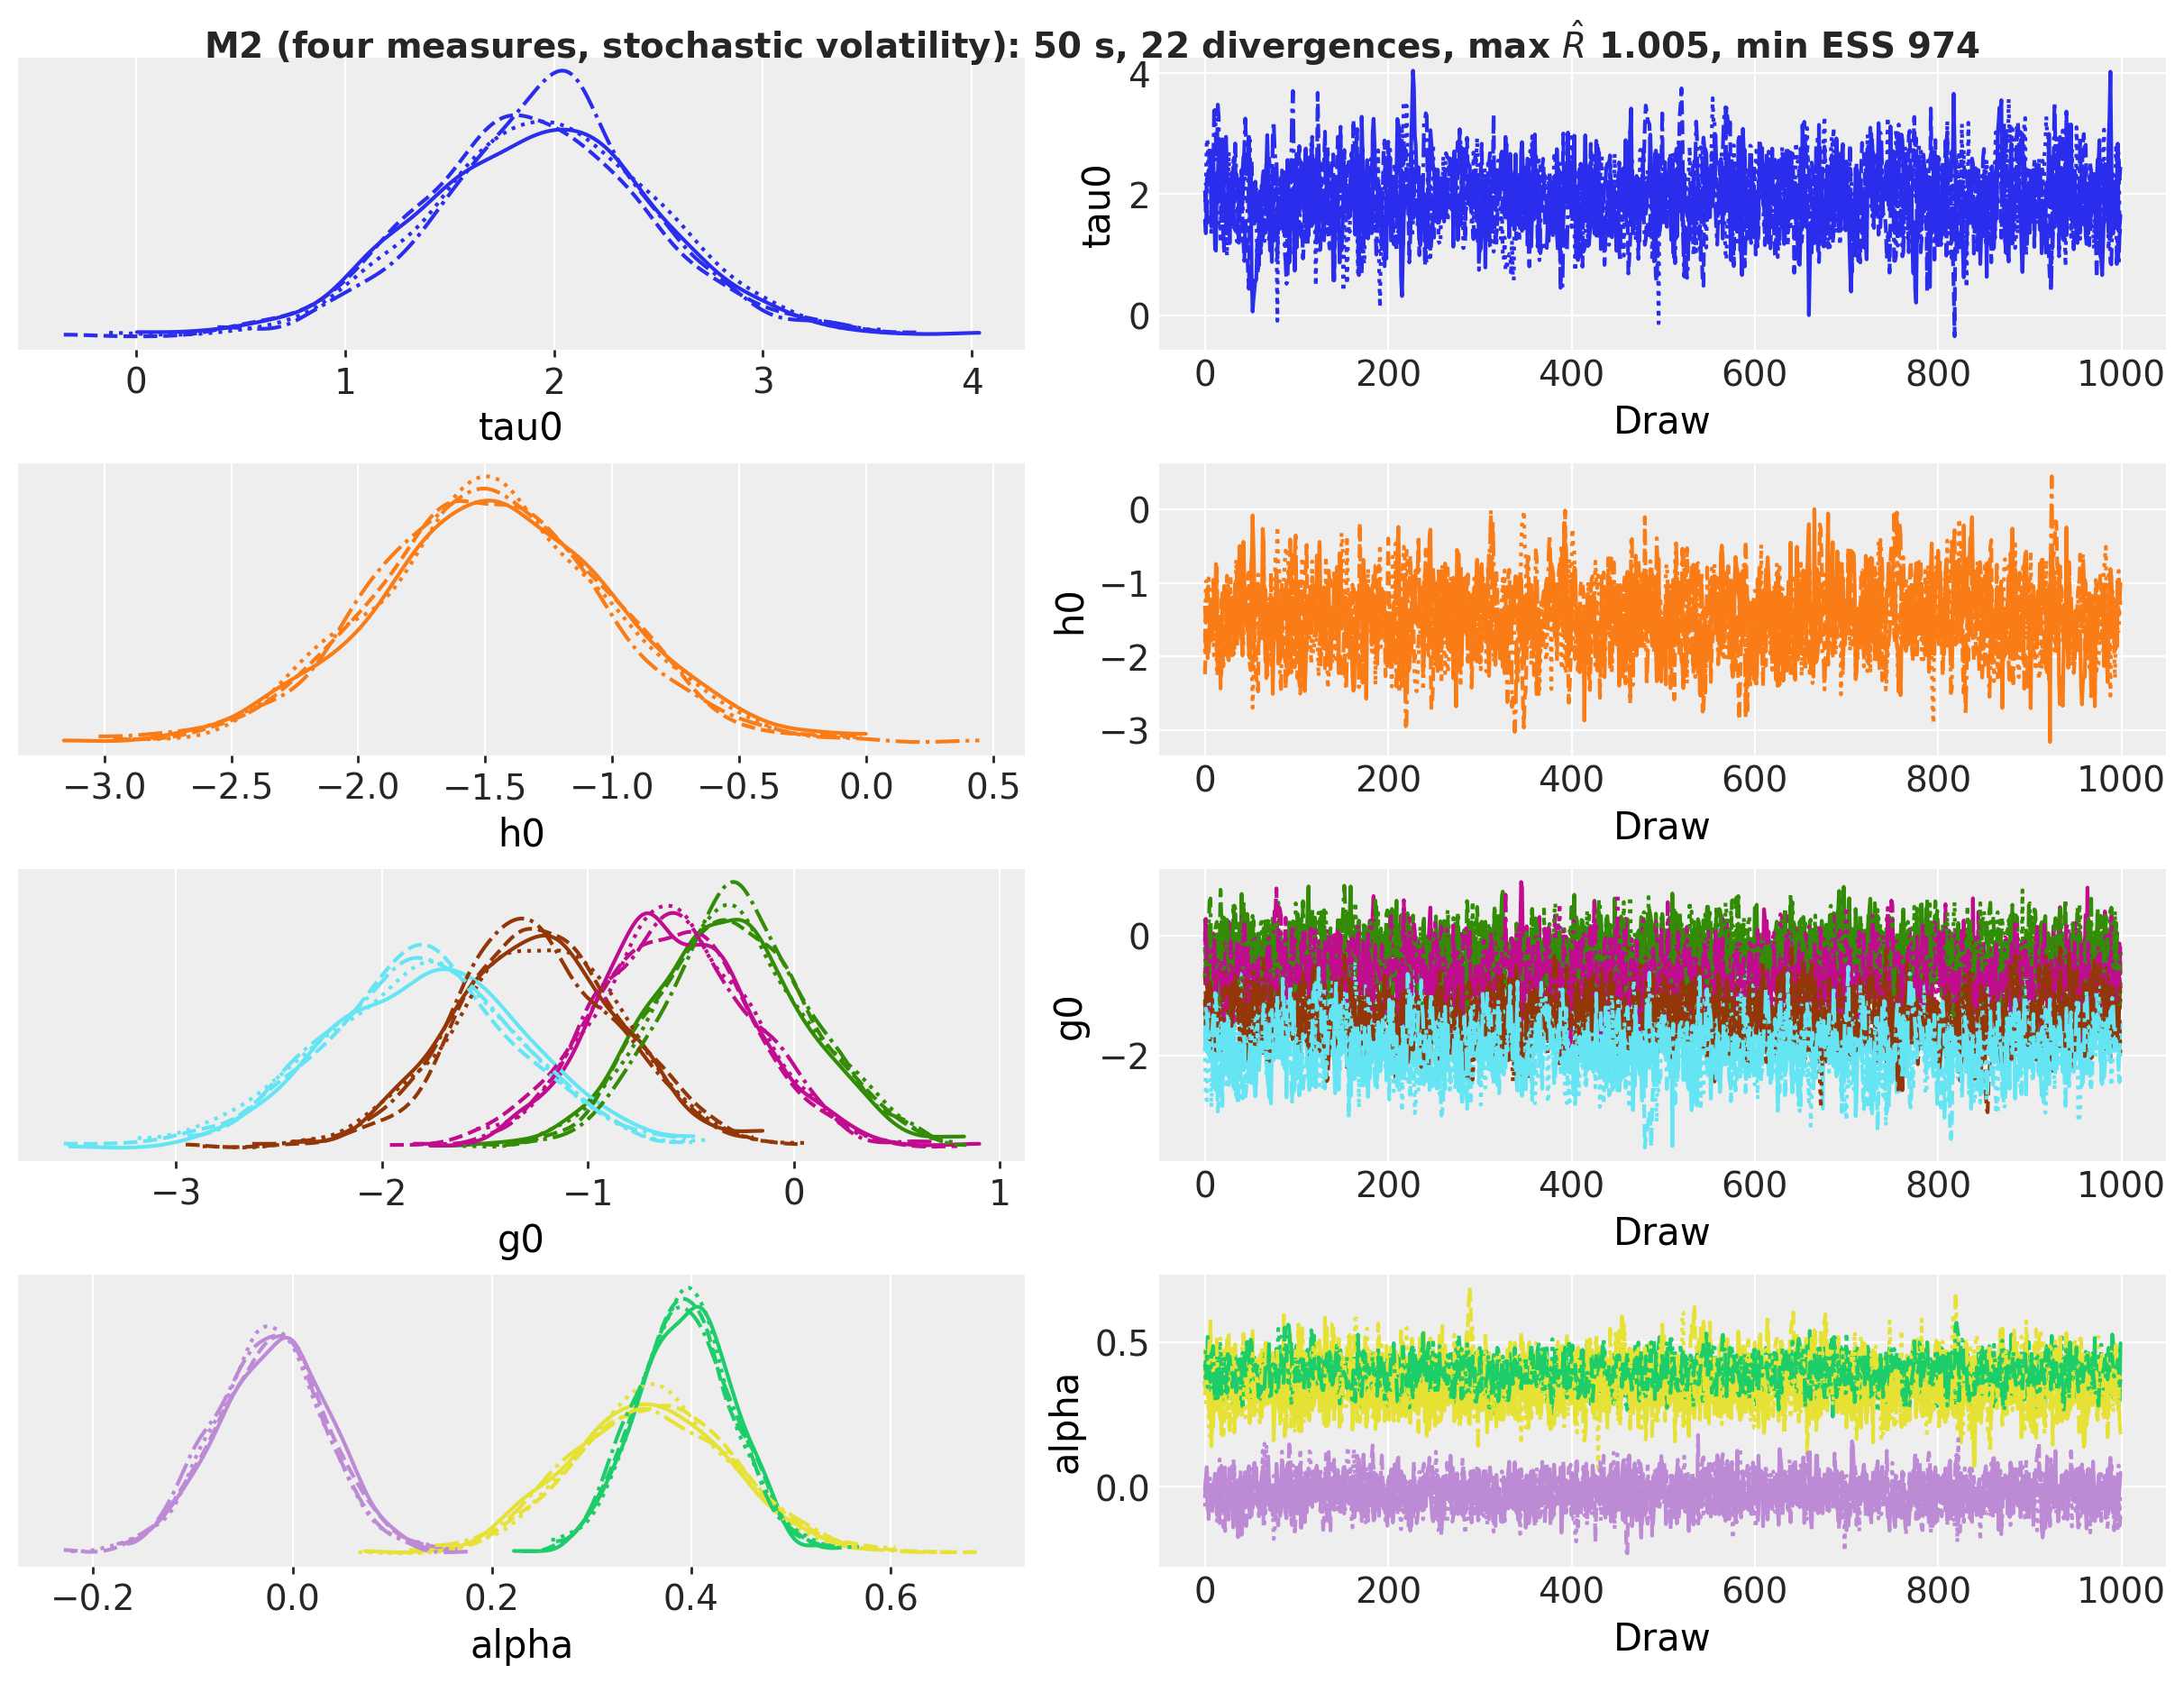

In [9]:
GLOBAL_SITES = ("tau0", "h0", "g0", "alpha", "nu", "vol_of_vol")


def num_divergences(mcmc: MCMC) -> int:
    """Total number of divergent transitions across chains."""
    return int(np.asarray(mcmc.get_extra_fields()["diverging"]).sum())


def divergence_label(count: int) -> str:
    """``"1 divergence"`` or ``"<count> divergences"``."""
    return f"{count} divergence" + ("" if count == 1 else "s")


def diagnostics(mcmc: MCMC, sites: tuple[str, ...] = GLOBAL_SITES) -> tuple[float, float]:
    """Largest split R-hat and smallest effective sample size over the ``sites`` of the fit."""
    samples = mcmc.get_samples(group_by_chain=True)
    summary = numpyro.diagnostics.summary(
        {site: samples[site] for site in sites if site in samples}, group_by_chain=True
    )
    r_hat = max(float(np.max(stats["r_hat"])) for stats in summary.values())
    ess = min(float(np.min(stats["n_eff"])) for stats in summary.values())
    return r_hat, ess


def fit_title(label: str, mcmc: MCMC, seconds: float) -> str:
    """Title line with the wall time, the divergences, the largest R-hat and the smallest ESS."""
    r_hat, ess = diagnostics(mcmc)
    return (
        f"{label}: {seconds:.0f} s, {divergence_label(num_divergences(mcmc))}, "
        rf"max $\hat{{R}}$ {r_hat:.3f}, min ESS {ess:,.0f}"
    )


pc = az.plot_trace_dist(
    tree, var_names=["tau0", "h0", "g0", "alpha"], compact=True, figure_kwargs={"figsize": (12, 9)}
)
pc.viz["figure"].item().suptitle(
    fit_title("M2 (four measures, stochastic volatility)", mcmc, seconds),
    fontsize=14,
    fontweight="bold",
    y=1.02,
);

The four chains agree on every global parameter: the densities overlap, the largest $\hat{R}$ is $1.005$ and the smallest effective sample size is $974$ of $4{,}000$ draws. The $22$ divergent transitions are half a percent of the draws, and they come from the geometry of the posterior rather than from the sampler settings. The next figure locates them: for every draw we take the smallest gap volatility of core PCE over the sample and mark the divergent draws on it.

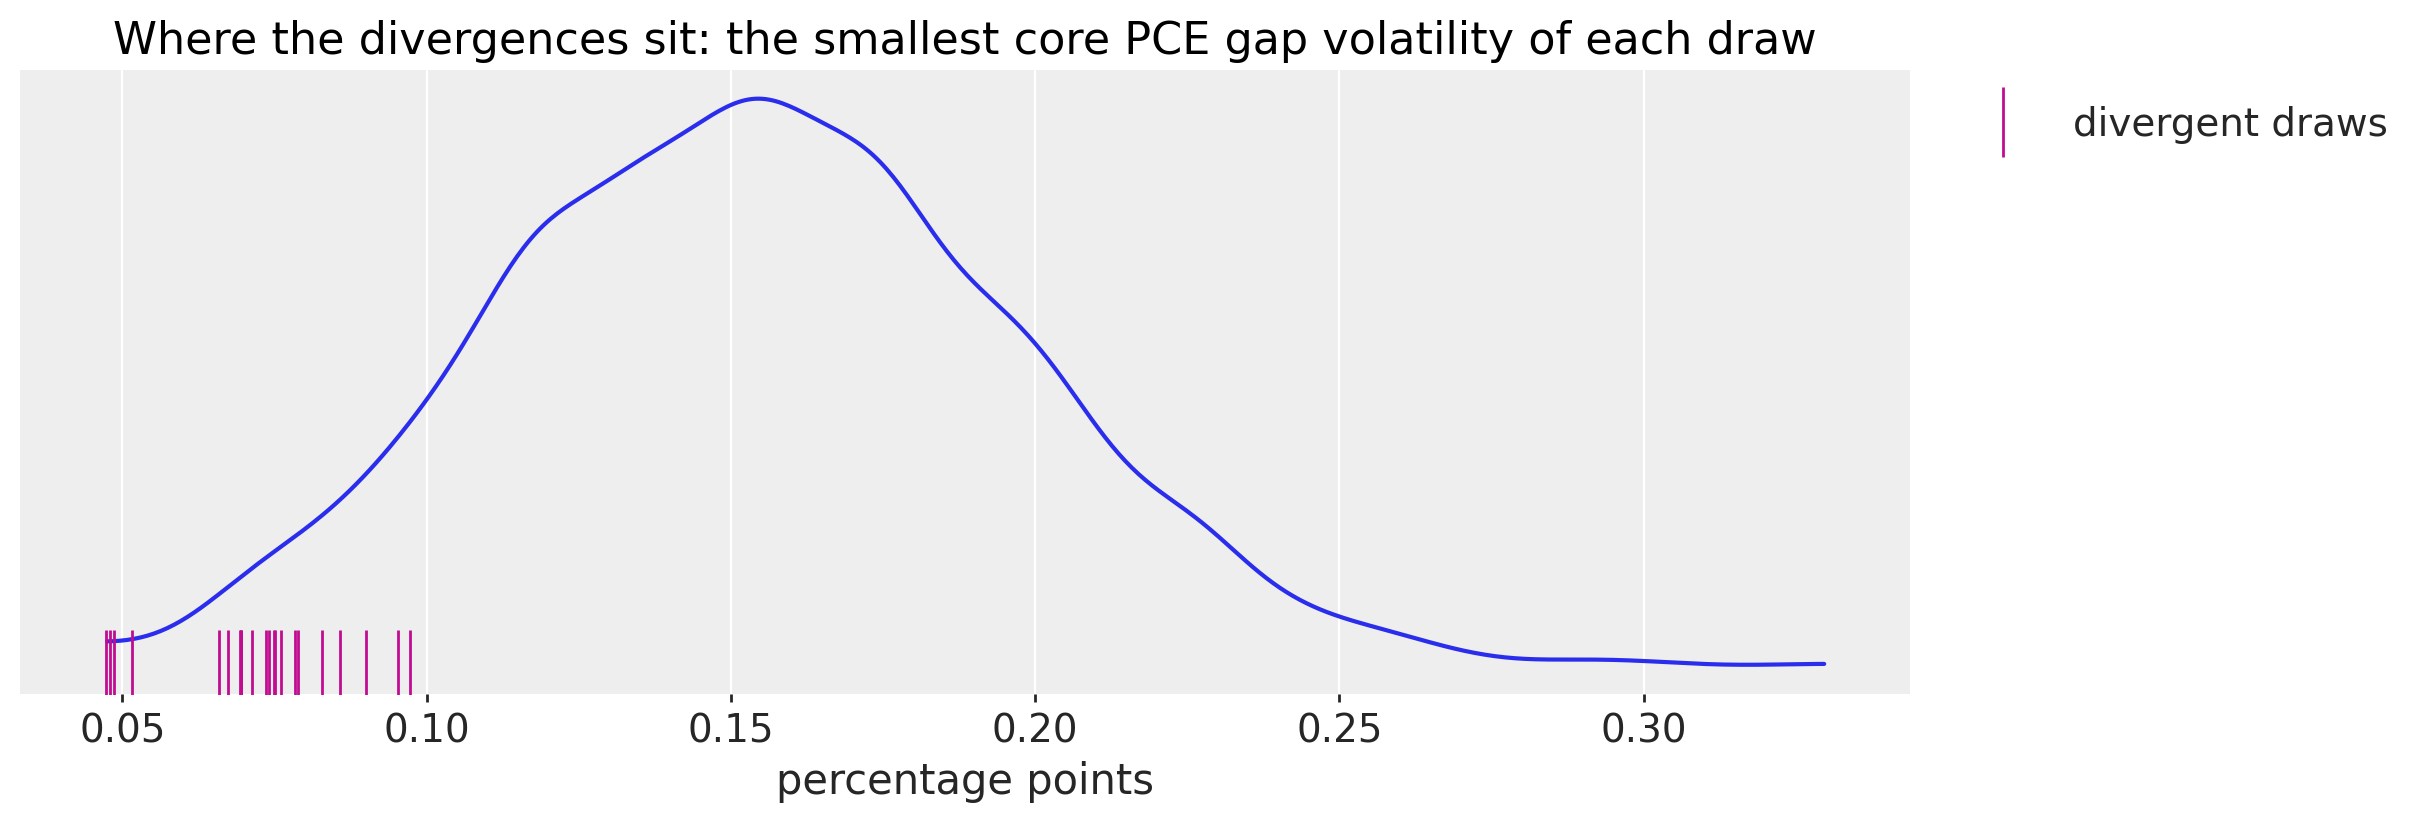

In [10]:
posterior = tree["posterior"].dataset
smallest_gap_vol = posterior["gap_vol"].sel(measure="core PCE").min("time")  # (chain, draw)
diverging = mcmc.get_extra_fields(group_by_chain=True)["diverging"]  # (chain, draw)

pc = az.plot_dist(
    smallest_gap_vol.to_dataset(name="smallest core PCE gap volatility"),
    kind="kde",
    visuals={"credible_interval": False, "point_estimate": False, "point_estimate_text": False},
    figure_kwargs={"figsize": (12, 4)},
)
ax = pc.viz["figure"].item().axes[0]
divergent_values = smallest_gap_vol.values[np.asarray(diverging)]
ax.plot(
    divergent_values,
    np.zeros_like(divergent_values),
    marker="|",
    linestyle="none",
    color="C3",
    markersize=25,
    label="divergent draws",
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title="Where the divergences sit: the smallest core PCE gap volatility of each draw",
    xlabel="percentage points",
);

The divergent draws sit in the left tail of the distribution: their smallest core PCE gap volatility is between $0.05$ and $0.10$ percentage points, against a median of $0.15$ over all draws. There the likelihood pins the trend to core PCE almost exactly in those quarters, the posterior narrows sharply in the direction of the trend steps, and the leapfrog integrator overshoots. The posterior mass in that tail is small, the chains agree on every parameter, and the quarters where it happens are the ones where core PCE is smoothest (the late 2010s and the 2020s, as the gap volatility figure below shows), so the draws we keep describe the same posterior. A model that put a floor under the gap volatility would remove the funnel, at the price of an extra parameter with no data to set it.

## Trend inflation

The trend is the part of inflation that all four measures share. We plot its posterior with core PCE inflation, the reference measure, on top: the gap between the line and the band is the transitory part of core PCE.

In [11]:
def stack_draws(variable: xr.DataArray) -> np.ndarray:
    """Posterior draws of a ``(chain, draw, time, ...)`` variable as ``(sample, time, ...)``."""
    return variable.stack(sample=("chain", "draw")).transpose("sample", "time", ...).to_numpy()


def plot_bands(
    draws: np.ndarray,
    x: np.ndarray,
    series: list[str],
    *,
    color: str = "C0",
    label: str = "",
    col_wrap: int = 1,
    figsize: tuple[int, int] = (12, 6),
) -> tuple[PlotCollection, list[PolyCollection]]:
    r"""Plot the $50\%$ and $94\%$ HDI bands of ``draws`` against ``x``, one panel per series.

    Returns the plot collection and the band handles, labeled ``f"{label}{hdi_label(prob)}"``.
    """
    pc = az.plot_lm(
        predictions_to_datatree(draws, x, series),
        y="obs",
        x="t",
        plot_dim="time",
        ci_kind="hdi",
        ci_prob=HDI_PROBS,
        smooth=False,
        col_wrap=col_wrap,
        visuals={
            "ci_band": {"color": color},
            "observed_scatter": False,
            "pe_line": False,
            "xlabel": False,
            "ylabel": False,
        },
        aes={"alpha": ["prob"]},
        alpha=HDI_ALPHAS,
        figure_kwargs={"figsize": figsize},
    )
    handles = []

    for prob in HDI_PROBS:
        band = pc.viz["ci_band"]["t"].sel(series=series[0], prob=prob).item()
        band.set_label(f"{label}{hdi_label(prob)}")
        handles.append(band)

    for ax in pc.viz["figure"].item().axes:
        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    return pc, handles

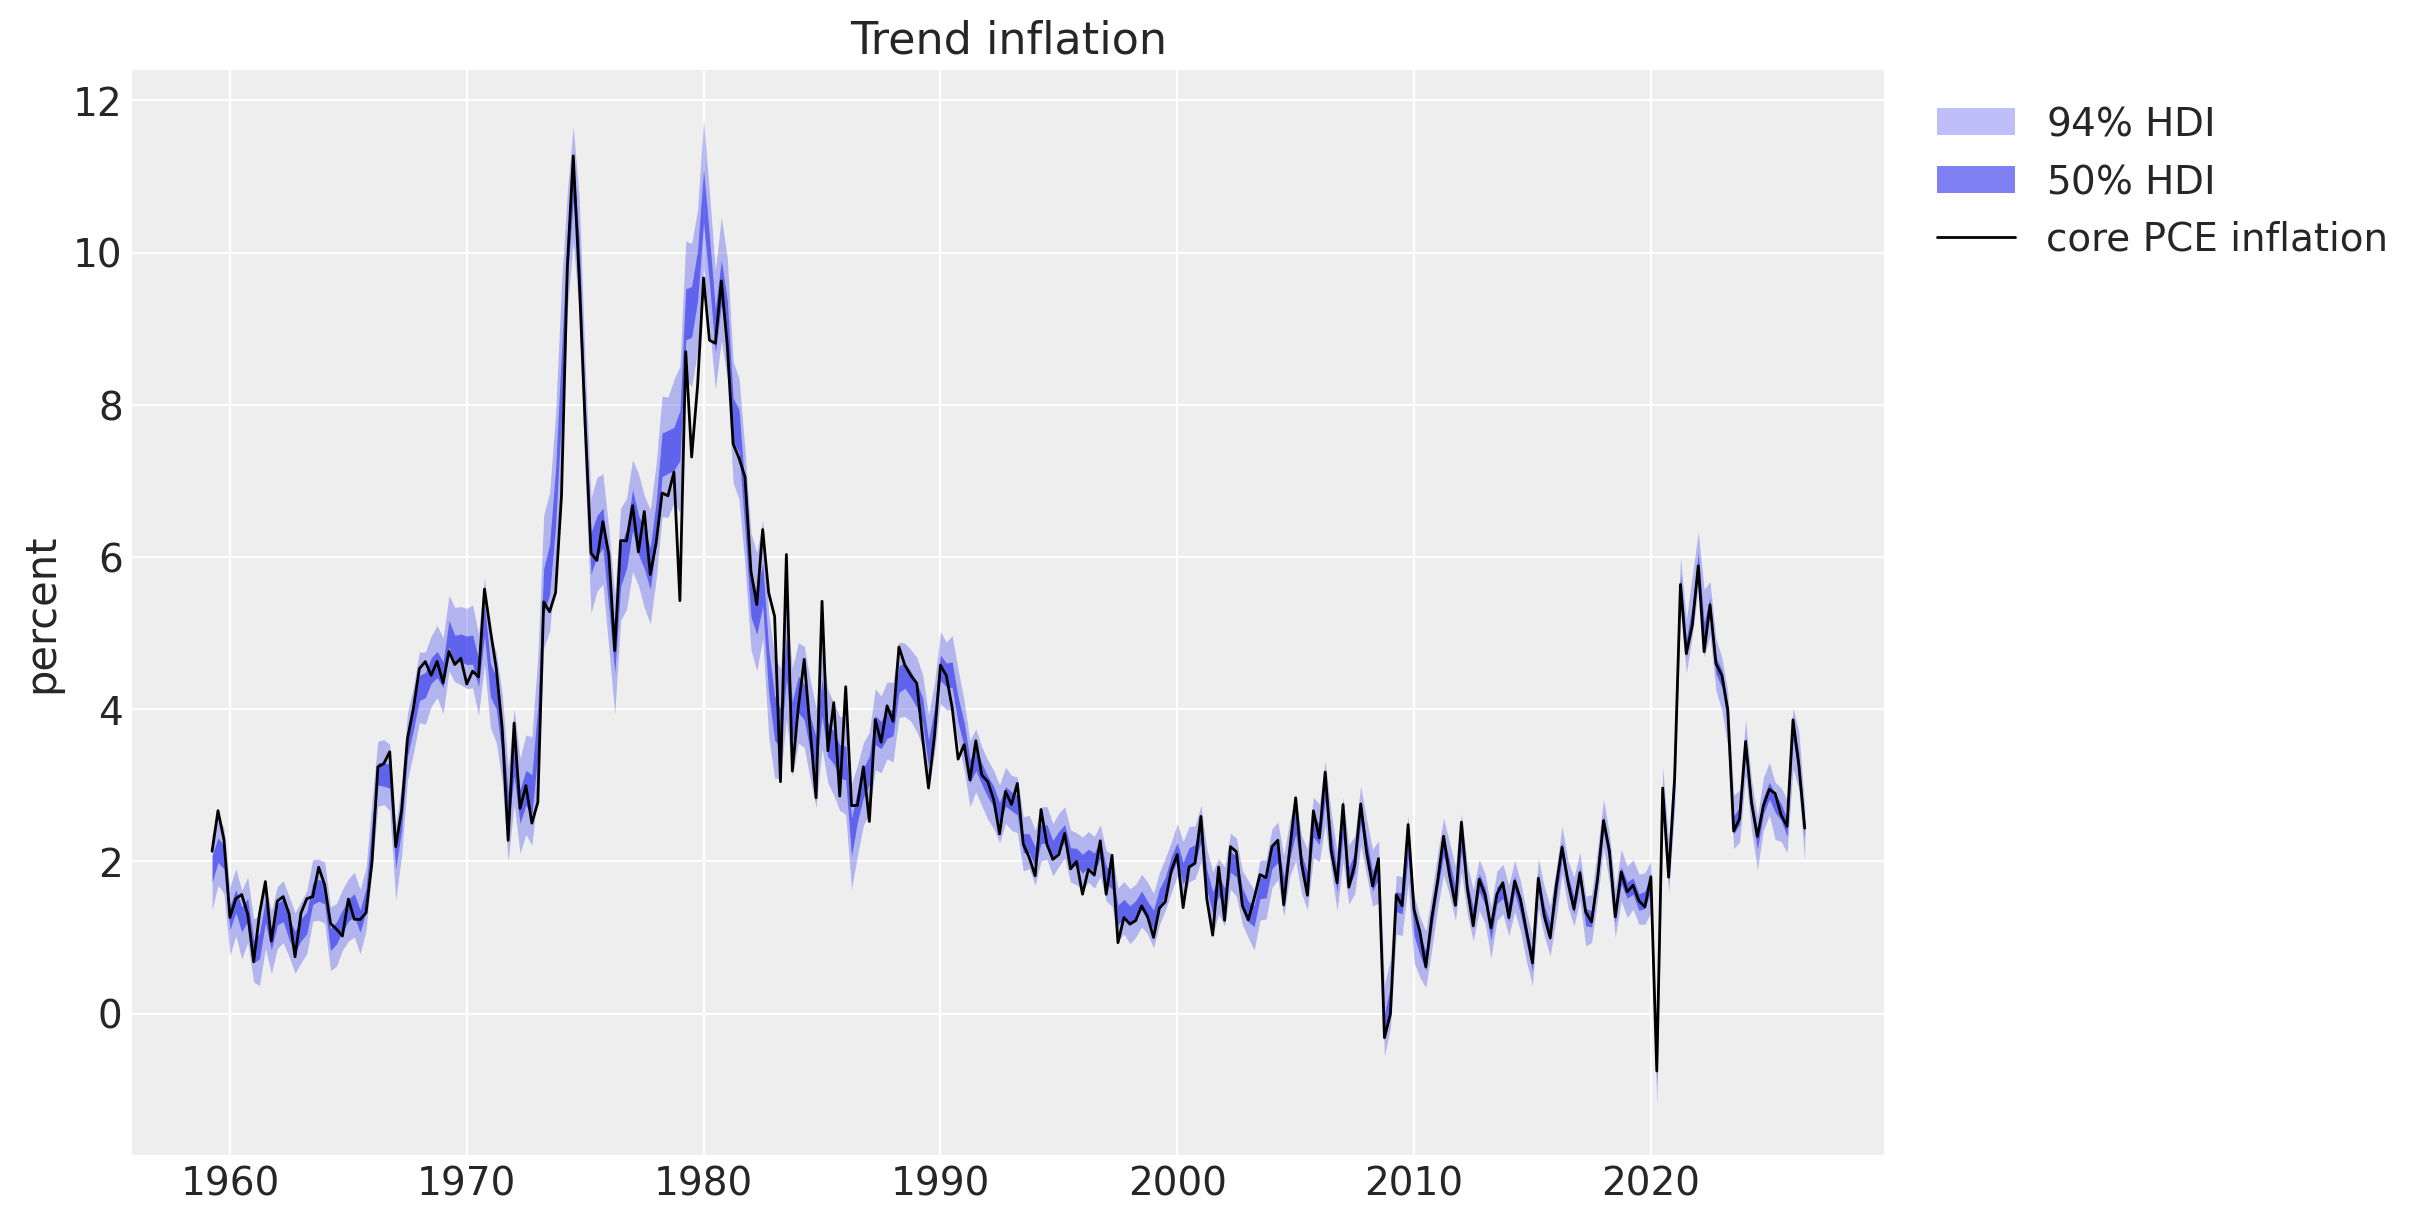

In [12]:
trend_draws = stack_draws(posterior["trend"])  # (samples, quarters, 1)
pc, band_handles = plot_bands(trend_draws, date_num, ["trend"])
ax = pc.viz["figure"].item().axes[0]
(core_line,) = ax.plot(date_num, rates[:, -1], color="black", lw=1, label="core PCE inflation")
ax.legend(handles=[*band_handles, core_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(title="Trend inflation", ylabel="percent");

The band is narrow: the $94\%$ HDI of the trend is $0.8$ percentage points wide in a typical quarter and $2.4$ at its widest, in 1974, and core PCE inflation stays inside it for most of the sample, because core PCE is the smoothest of the four measures and has the smallest gap volatility. Along the sample:

- The trend starts at $1.9\%$ in 1959Q2 ($94\%$ HDI $1.4$ to $2.3$), dips to $1.3\%$ in 1965 and climbs to $4.8\%$ by 1970Q1.
- It peaks twice, at $11.0\%$ in 1974Q3 and $10.8\%$ in 1980Q1. At the second peak core PCE is at $9.7\%$ and the trend sits above it: the two headline measures, at $15.5\%$ and $11.8\%$, pull the common component up.
- The disinflation takes it to $4.2\%$ in 1985Q1 and $2.3\%$ in 1995Q1. From 1995 to 2019 the posterior mean stays between $-0.1\%$ (2008Q4) and $2.9\%$.
- 2020Q2 is a one-quarter dip to $-0.8\%$ ($94\%$ HDI $-1.2$ to $-0.5$). The trend follows core PCE down and back, because the gap volatility of core PCE at that date is $0.2$ percentage points and leaves no room to call the quarter transitory.
- The surge takes the trend to $5.7\%$ in 2021Q2 and $6.0\%$ in 2022Q1, and it comes down to $2.4\%$ in 2026Q3 ($94\%$ HDI $2.0$ to $2.7$).

For the forecast, the 2020Q2 reading matters: the model treats that quarter as a move of the trend rather than as noise, and a Student-t gap would treat it differently.

## Volatilities

The model has five volatility paths: one for the trend shock and one per measure for the gap. The trend volatility says how fast the persistent part of inflation can move in a quarter; the gap volatilities say how noisy each measure is around the trend at each date.

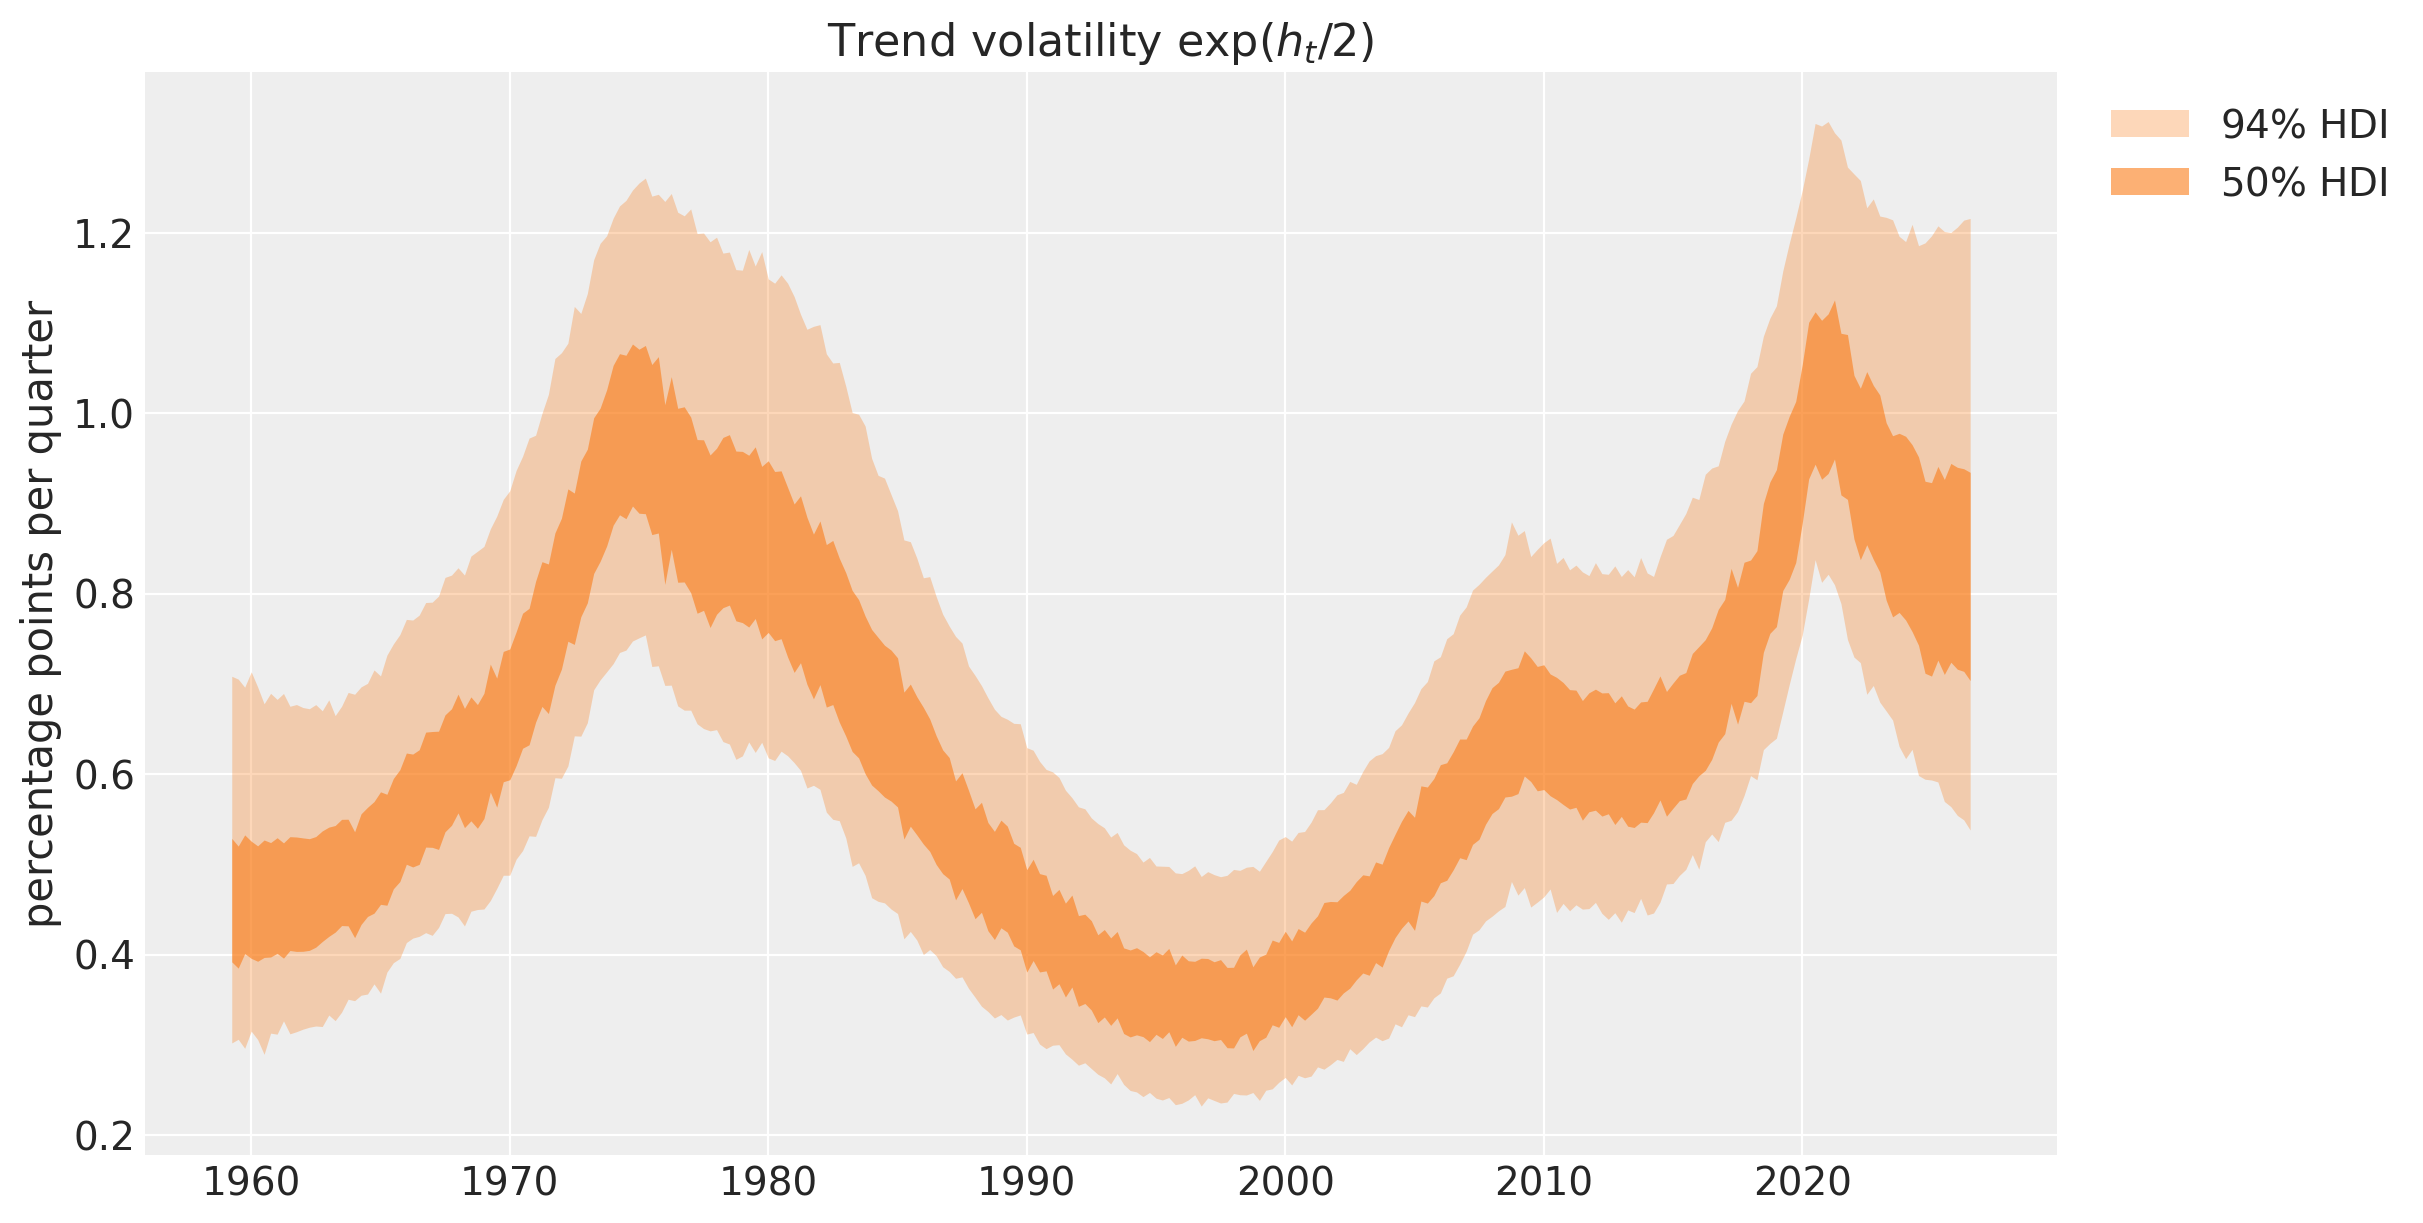

In [13]:
trend_vol_draws = stack_draws(posterior["trend_vol"])  # (samples, quarters, 1)
pc, band_handles = plot_bands(trend_vol_draws, date_num, ["trend volatility"], color="C1")
ax = pc.viz["figure"].item().axes[0]
ax.legend(handles=band_handles, loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(title=r"Trend volatility $\exp(h_t / 2)$", ylabel="percentage points per quarter");

The trend volatility is the standard deviation of the quarterly change of the trend, in annualized percentage points. Its path is the reason for stochastic volatility in the model:

- It rises from $0.5$ in 1959 to $1.0$ in 1974Q3 ($94\%$ HDI $0.7$ to $1.2$), stays near $0.9$ through 1980 and falls through the 1980s.
- It falls to $0.37$ in 1995Q1 ($94\%$ HDI $0.24$ to $0.50$) and reaches its minimum of $0.36$ in 1996Q3, in the middle of the Great Moderation: the persistent part of inflation moved by about a third of a percentage point per quarter.
- It climbs again from 2005, to $0.67$ in 2008Q4, holds there through the 2010s and reaches its maximum of $1.06$ in 2020Q3, before the surge: the 2020Q2 dip pushes it up, since the trend absorbs that quarter.
- It ends at $0.87$ ($94\%$ HDI $0.5$ to $1.2$), two and a half times the mid-1990s value, so the forecast bands below widen faster than they would have in 2005.

With $\gamma = 0.1$ the log-variance moves by a few tenths per quarter at most, which is why the path is smooth. The volatility does not jump at 2008Q4 or 2020Q2; it turns over several quarters.

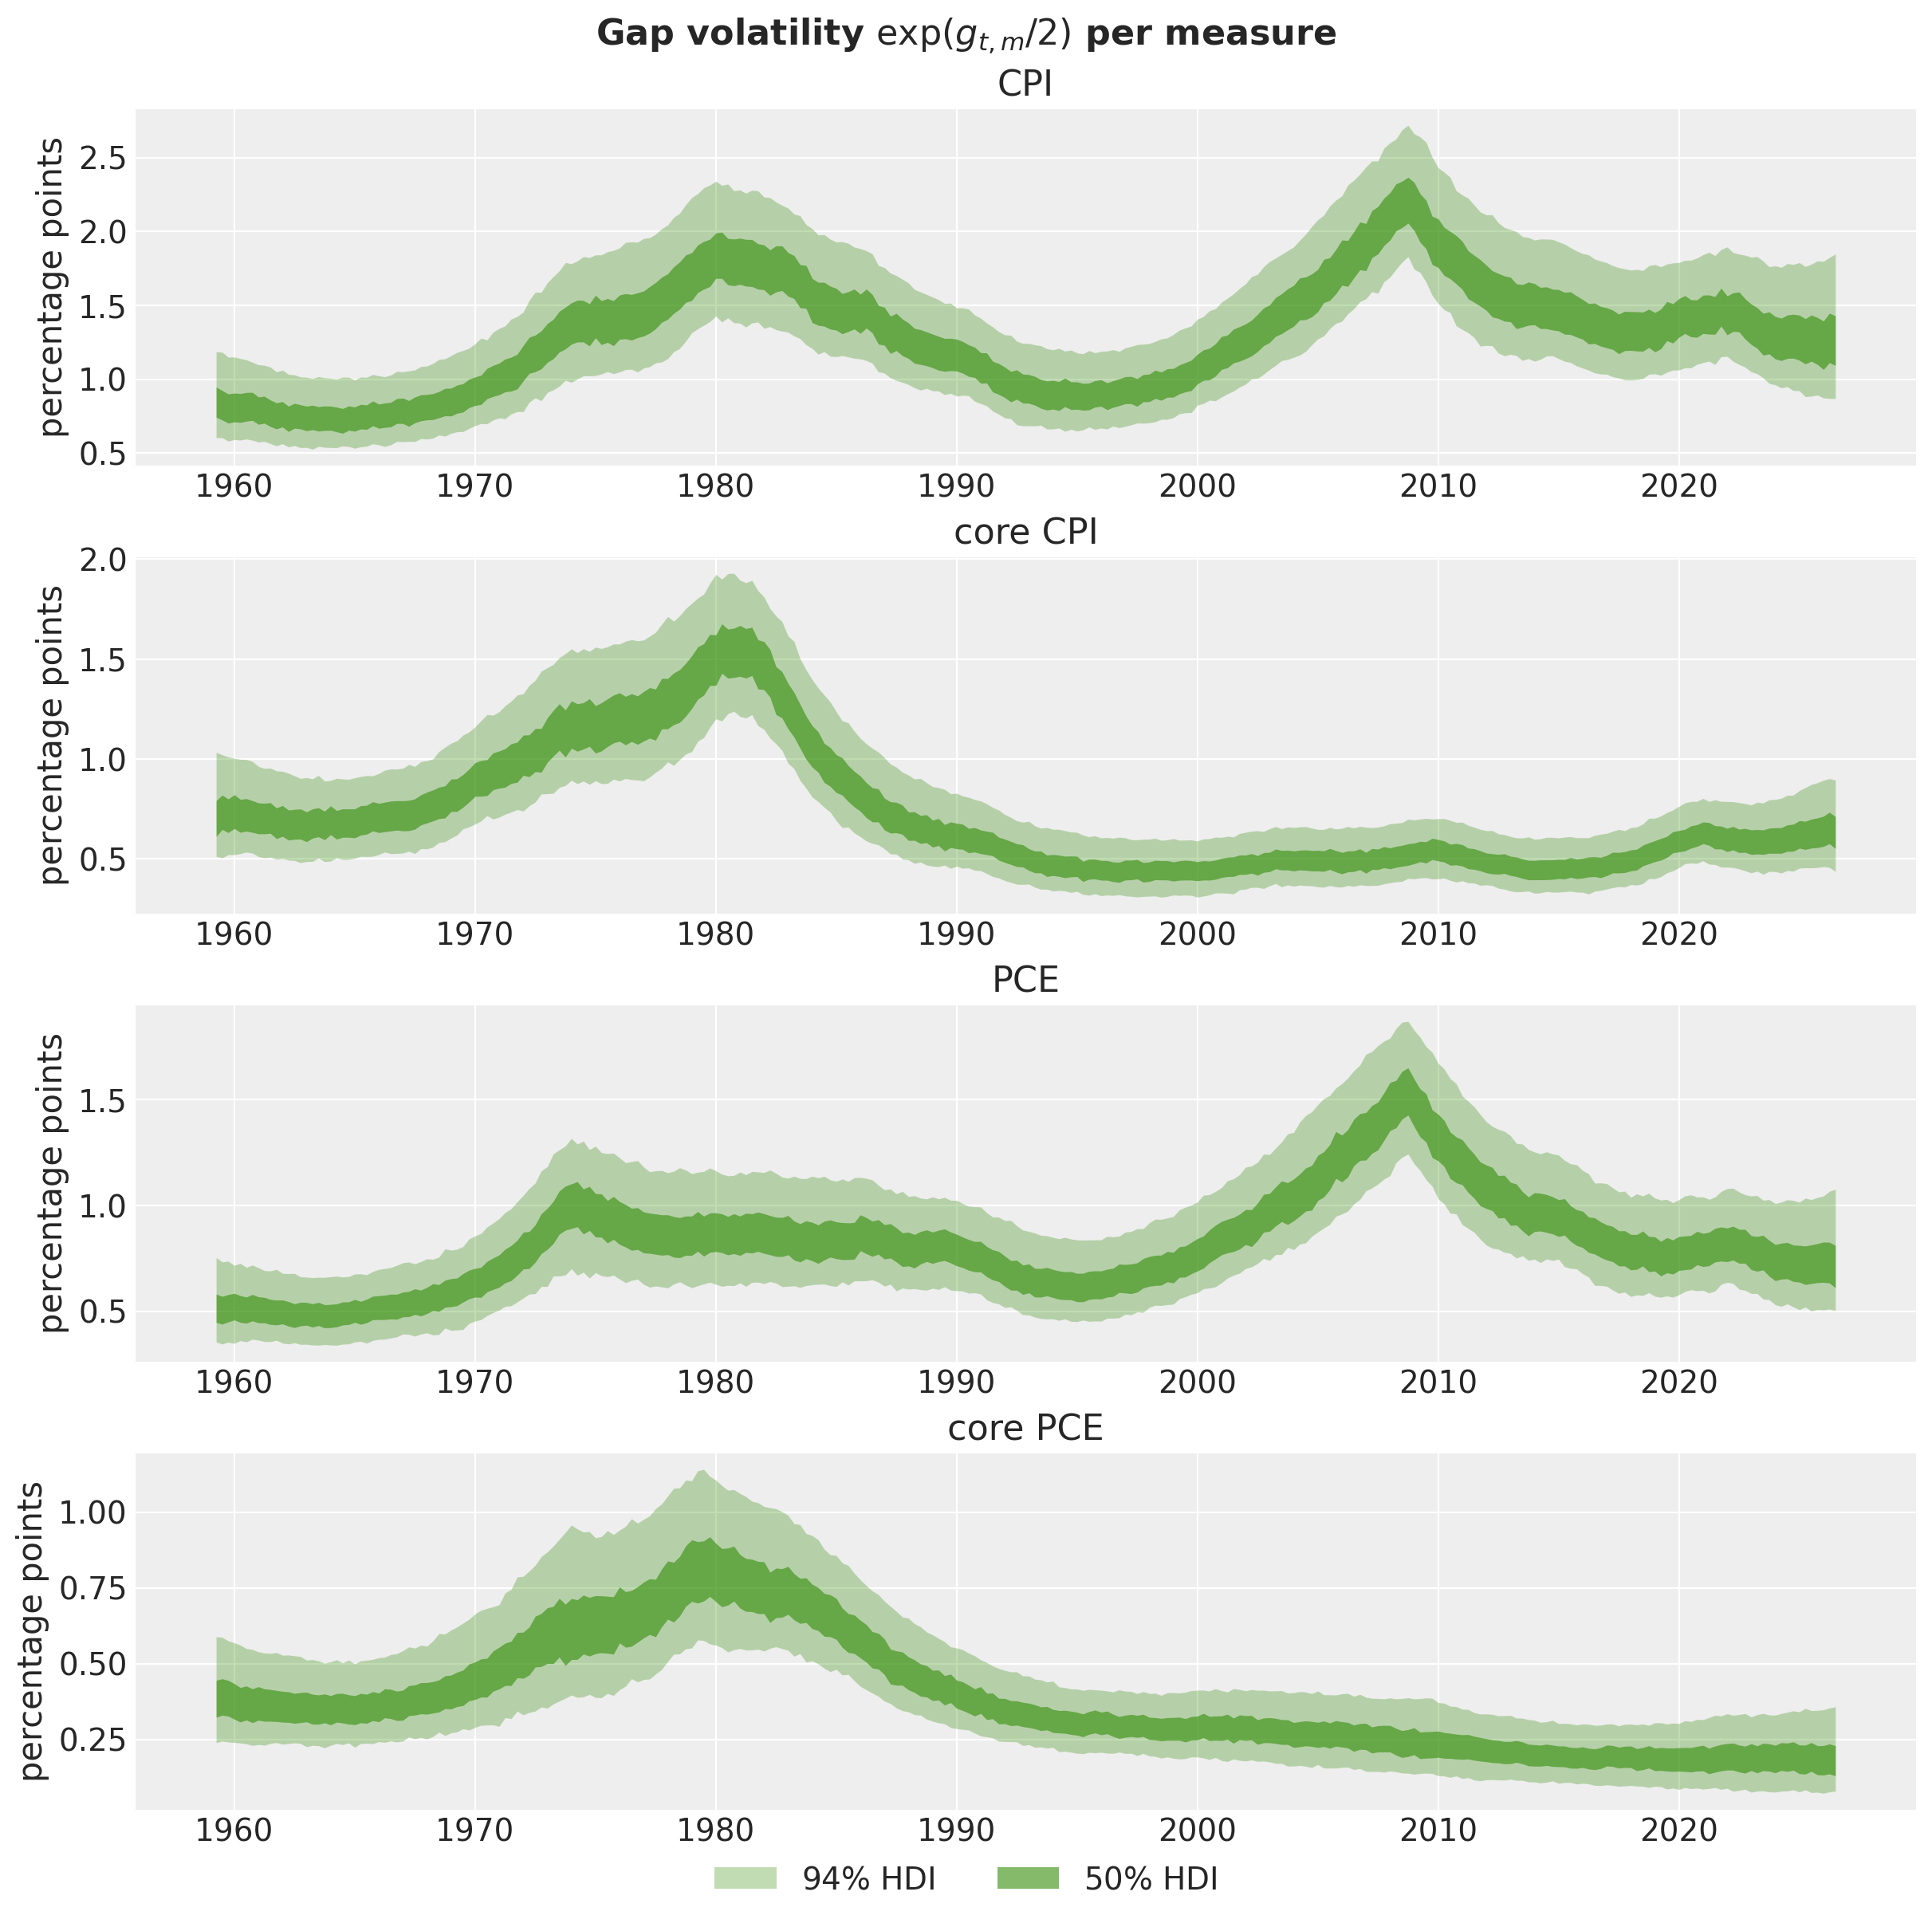

In [14]:
gap_vol_draws = stack_draws(posterior["gap_vol"])  # (samples, quarters, measures)
pc, band_handles = plot_bands(
    gap_vol_draws, date_num, list(measure_labels), color="C2", figsize=(12, 12)
)
fig = pc.viz["figure"].item()

for ax, label in zip(fig.axes, measure_labels, strict=True):
    ax.set(title=label, ylabel="percentage points")

fig.legend(handles=band_handles, loc="outside lower center", ncols=2)
fig.suptitle(r"Gap volatility $\exp(g_{t, m} / 2)$ per measure", fontsize=16, fontweight="bold");

The four gap volatilities separate the measures:

- CPI has the largest and most variable gap: $0.9$ percentage points in 1959, $1.9$ in 1980, $0.9$ in 1995 and $2.3$ at its peak in 2008Q4, the quarter of the oil price collapse; it ends at $1.3$.
- Core CPI peaks at $1.6$ in 1980Q3, falls to $0.5$ by 1995 and stays between $0.5$ and $0.7$ after that; 2008Q4 leaves no mark on it.
- PCE follows CPI with a smaller amplitude: $0.5$ in 1959, $1.6$ at the 2008Q4 peak, $0.8$ at the end.
- Core PCE is the quietest measure at every date: $0.4$ in 1959, $0.8$ at its peak in 1979Q3, $0.3$ on average from 1995 to 2007, and $0.2$ from 2018 on, its minimum.

The 2008Q4 peak appears in the two headline measures and not in the two core measures, because the core measures exclude the energy component. The core PCE path also explains the divergences of the fit: its gap volatility is the smallest of the four, and the posterior puts mass close to zero from 2018 on. And since the trend is on the core PCE scale and the core PCE gap ends at $0.2$, the trend tracks core PCE almost one for one in the last decade.

## Measure offsets

The offsets are the average wedge of each measure over core PCE in percentage points, the level difference that the trend does not carry.

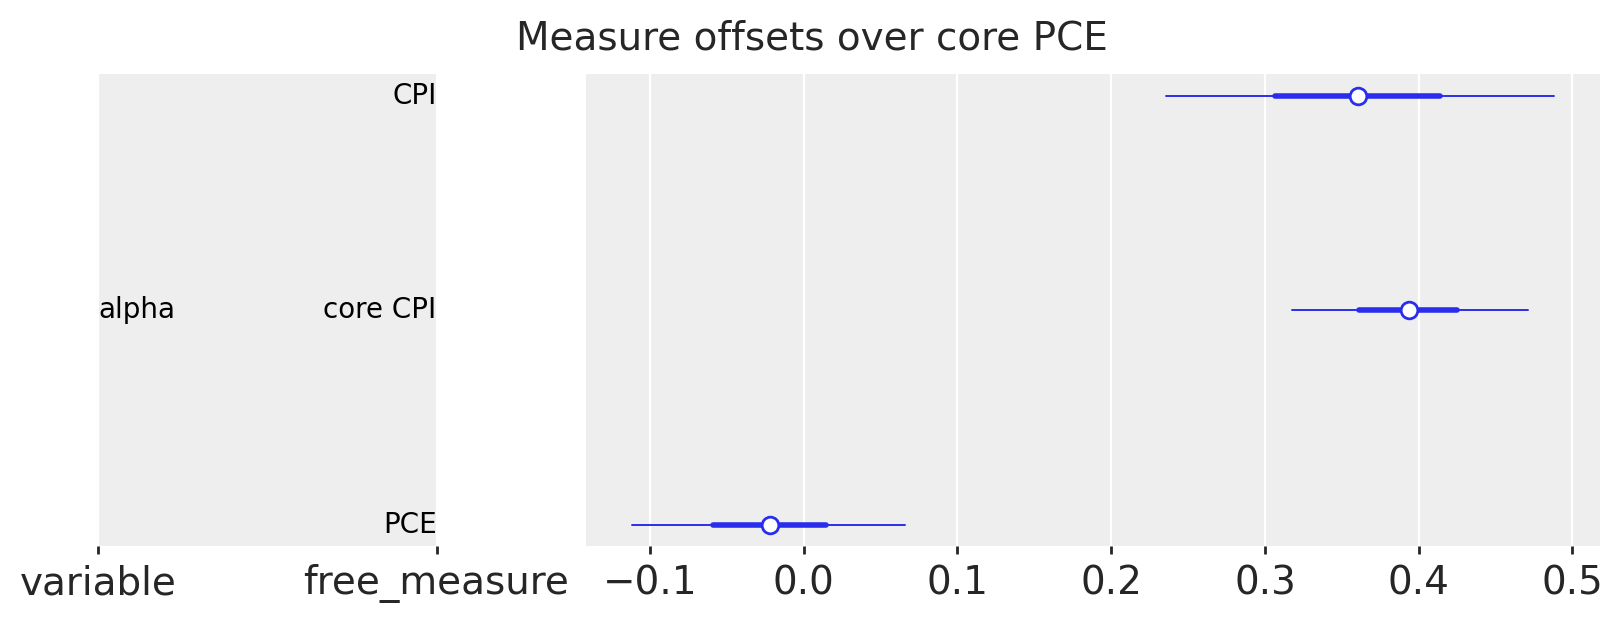

In [15]:
pc = az.plot_forest(tree, var_names=["alpha"], combined=True, figure_kwargs={"figsize": (8, 3)})
pc.viz["figure"].item().suptitle("Measure offsets over core PCE", fontsize=14);

The posterior puts the offsets at:

- CPI runs $0.36$ points above core PCE ($94\%$ HDI $0.22$ to $0.51$).
- Core CPI runs $0.39$ points above core PCE ($94\%$ HDI $0.30$ to $0.48$), with the tightest interval, because core CPI has the second smallest gap.
- PCE runs $0.02$ points below core PCE ($94\%$ HDI $-0.12$ to $0.08$): no wedge.

The wedge of about $0.4$ points separates the two CPI measures from the two PCE measures, so it is a property of the index formula and not of the food and energy components: the CPI prices a fixed basket and gives housing a larger weight, and the PCE index is chain weighted, so its basket follows substitution.

## Forecast

The forecast draws the eight future steps of every random walk from the prior of the steps (unit normals) and pushes them through the posterior of the paths at the last observation, so the trend continues from its last level with its last volatility, and each gap keeps its last scale. `export` already drew the forecast, because `covariates_full` has eight rows more than the data; the `predictions` group of the tree holds it. We plot the last forty quarters of core PCE: the in-sample band is the **smoothed fit**, the posterior predictive given the whole sample, and the forecast band is the predictive from the last observation onward.

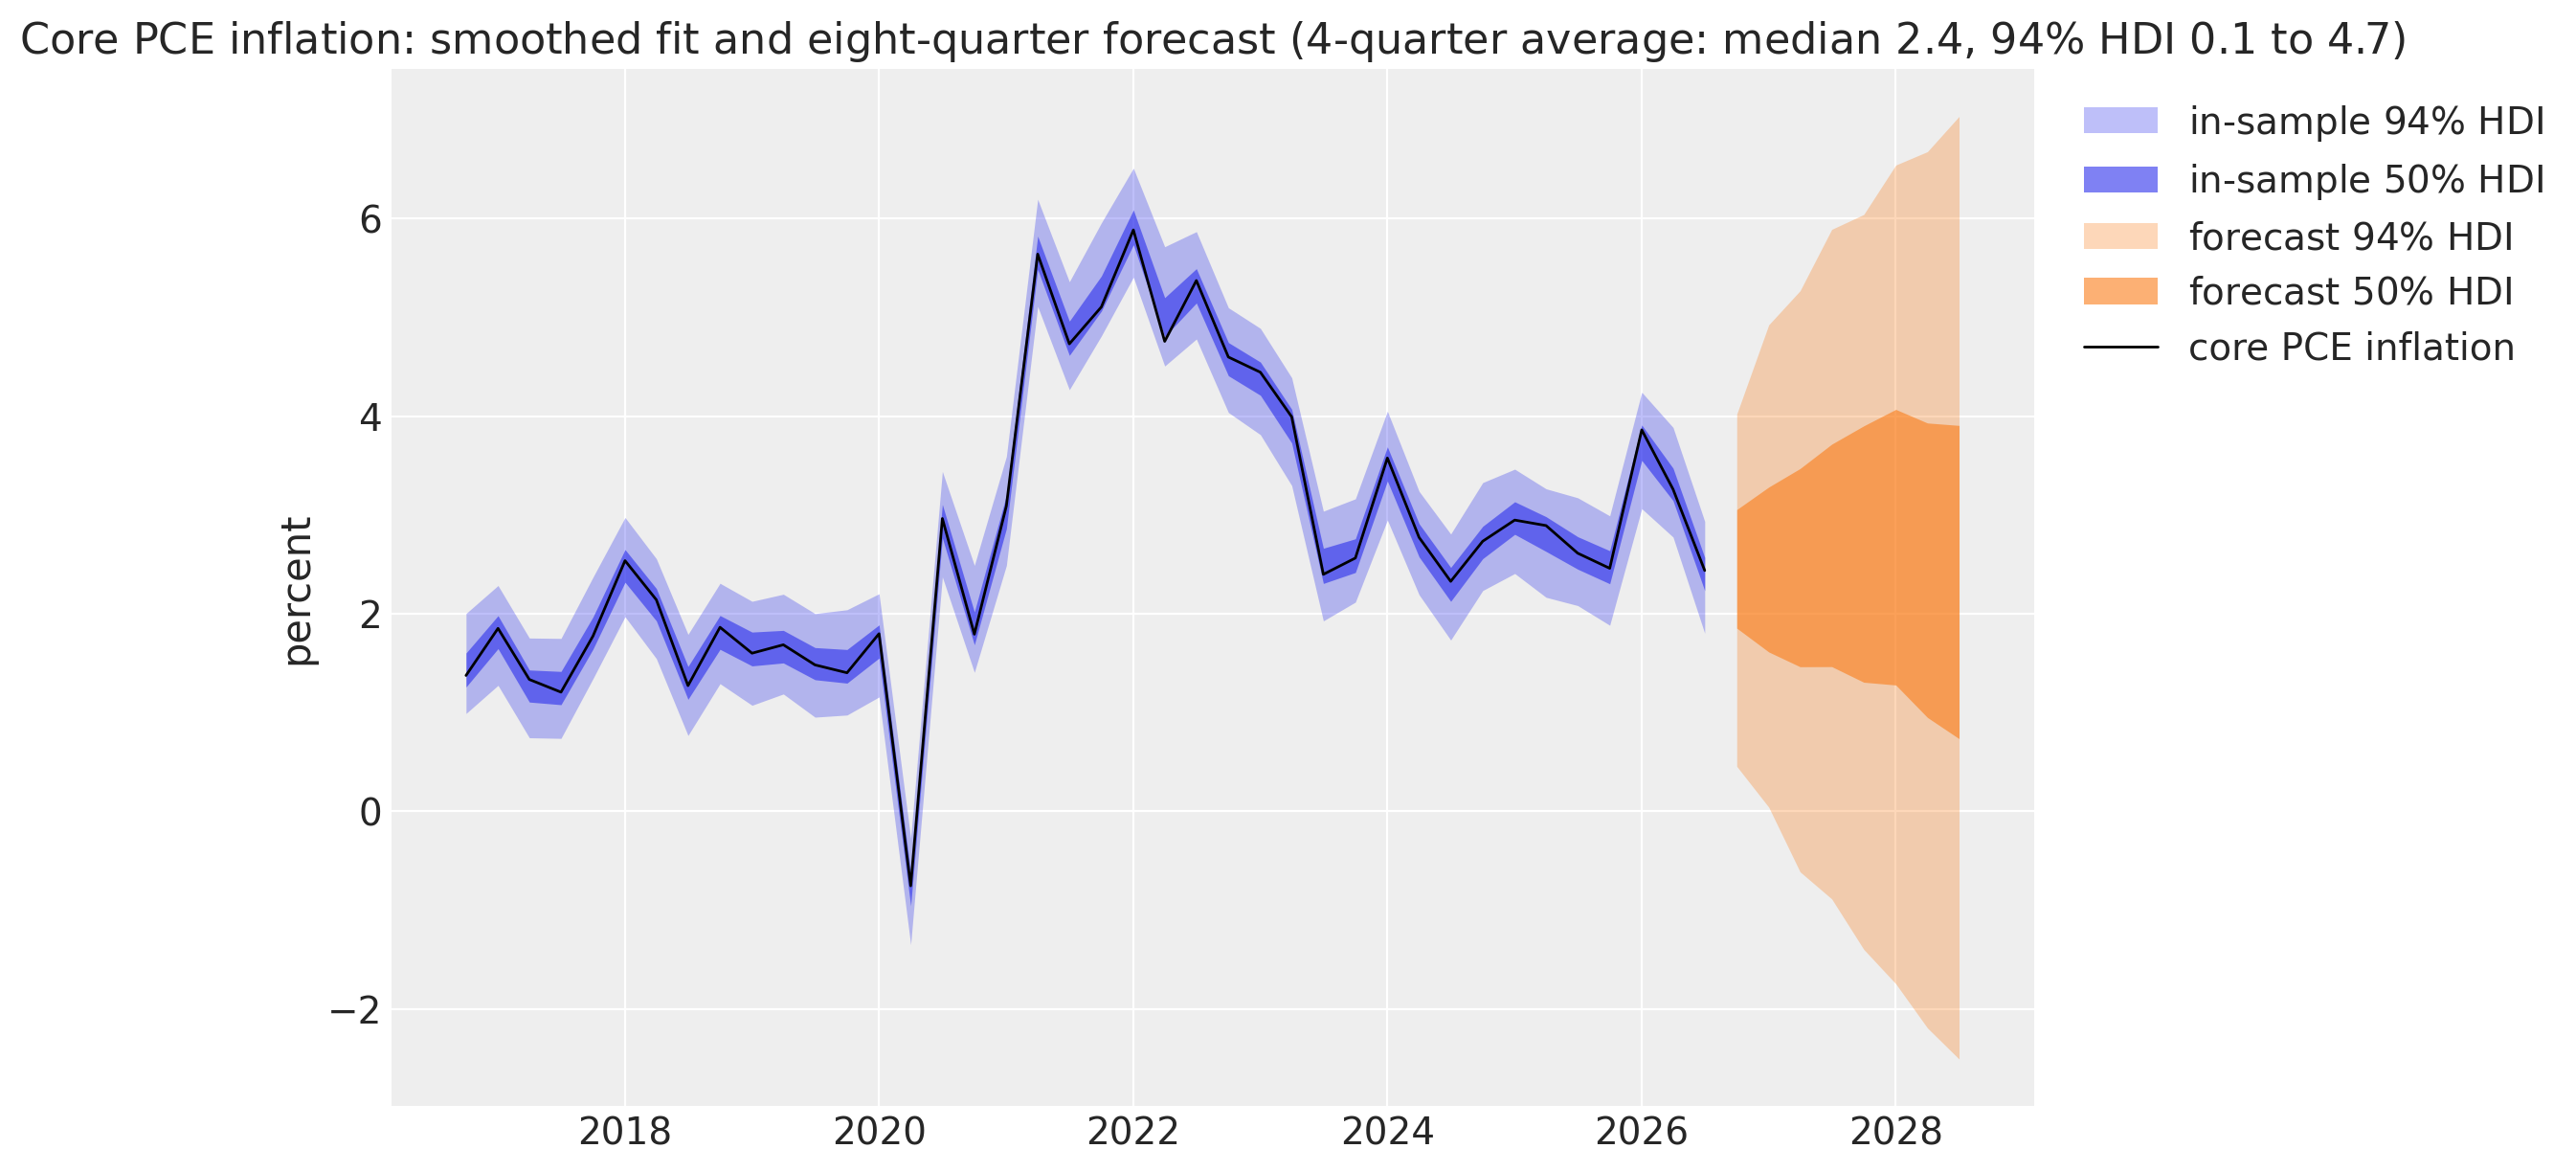

In [16]:
plot_start = num_quarters - 40
in_sample_draws = stack_draws(tree["posterior_predictive"]["obs"].sel(measure="core PCE"))
forecast_draws = stack_draws(tree["predictions"]["obs"].sel(measure="core PCE"))

pc, band_handles = plot_bands(
    in_sample_draws[:, plot_start:, None], date_num[plot_start:], ["core PCE"], label="in-sample "
)
az.plot_lm(
    predictions_to_datatree(forecast_draws[:, :, None], future_date_num, ["core PCE"]),
    y="obs",
    x="t",
    plot_dim="time",
    plot_collection=pc,
    ci_kind="hdi",
    ci_prob=HDI_PROBS,
    smooth=False,
    visuals={
        "ci_band": {"color": "C1"},
        "observed_scatter": False,
        "pe_line": False,
        "xlabel": False,
        "ylabel": False,
    },
)

for prob in HDI_PROBS:
    band = pc.viz["ci_band"]["t"].sel(prob=prob).item()
    band.set_label(f"forecast {hdi_label(prob)}")
    band_handles.append(band)

ax = pc.viz["figure"].item().axes[0]
(core_line,) = ax.plot(
    date_num[plot_start:], rates[plot_start:, -1], color="black", lw=1, label="core PCE inflation"
)
ax.legend(handles=[*band_handles, core_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
four_quarter_average = forecast_draws[:, :4].mean(axis=1)  # (samples,)
lower, upper = az.hdi(four_quarter_average, prob=0.94)
ax.set(
    title=(
        "Core PCE inflation: smoothed fit and eight-quarter forecast "
        rf"(4-quarter average: median {np.median(four_quarter_average):.1f}, "
        rf"$94\%$ HDI {lower:.1f} to {upper:.1f})"
    ),
    ylabel="percent",
);

The in-sample band is the smoothed fit: given the whole sample, the model knows the trend at each date, and the $94\%$ band of about $1.1$ percentage points is the gap noise of core PCE. The forecast band starts at $3.6$ points wide in 2026Q4 ($94\%$ HDI $0.5$ to $4.0$ around a median of $2.4\%$) and reaches $9.5$ points in 2028Q3 ($-2.5$ to $7.0$), because the trend is a random walk whose quarterly standard deviation is now $0.9$ points and the eight steps accumulate. The median stays flat at $2.4\%$, the last trend level: a random walk forecasts its last value. The 4-quarter average over 2026Q4 to 2027Q3, in the title, has a median of $2.4\%$ and a $94\%$ HDI of $0.1$ to $4.7$. With the trend volatility at its 2021 level, the model cannot rule out either $0\%$ or $5\%$ core inflation two years out.

The forecast of core PCE is the forecast of the trend plus the gap noise. A `Predictive` call with its own key returns the `trend` site over the full horizon, and its band says how much of the forecast width is the trend itself; the vertical line marks the last observation.

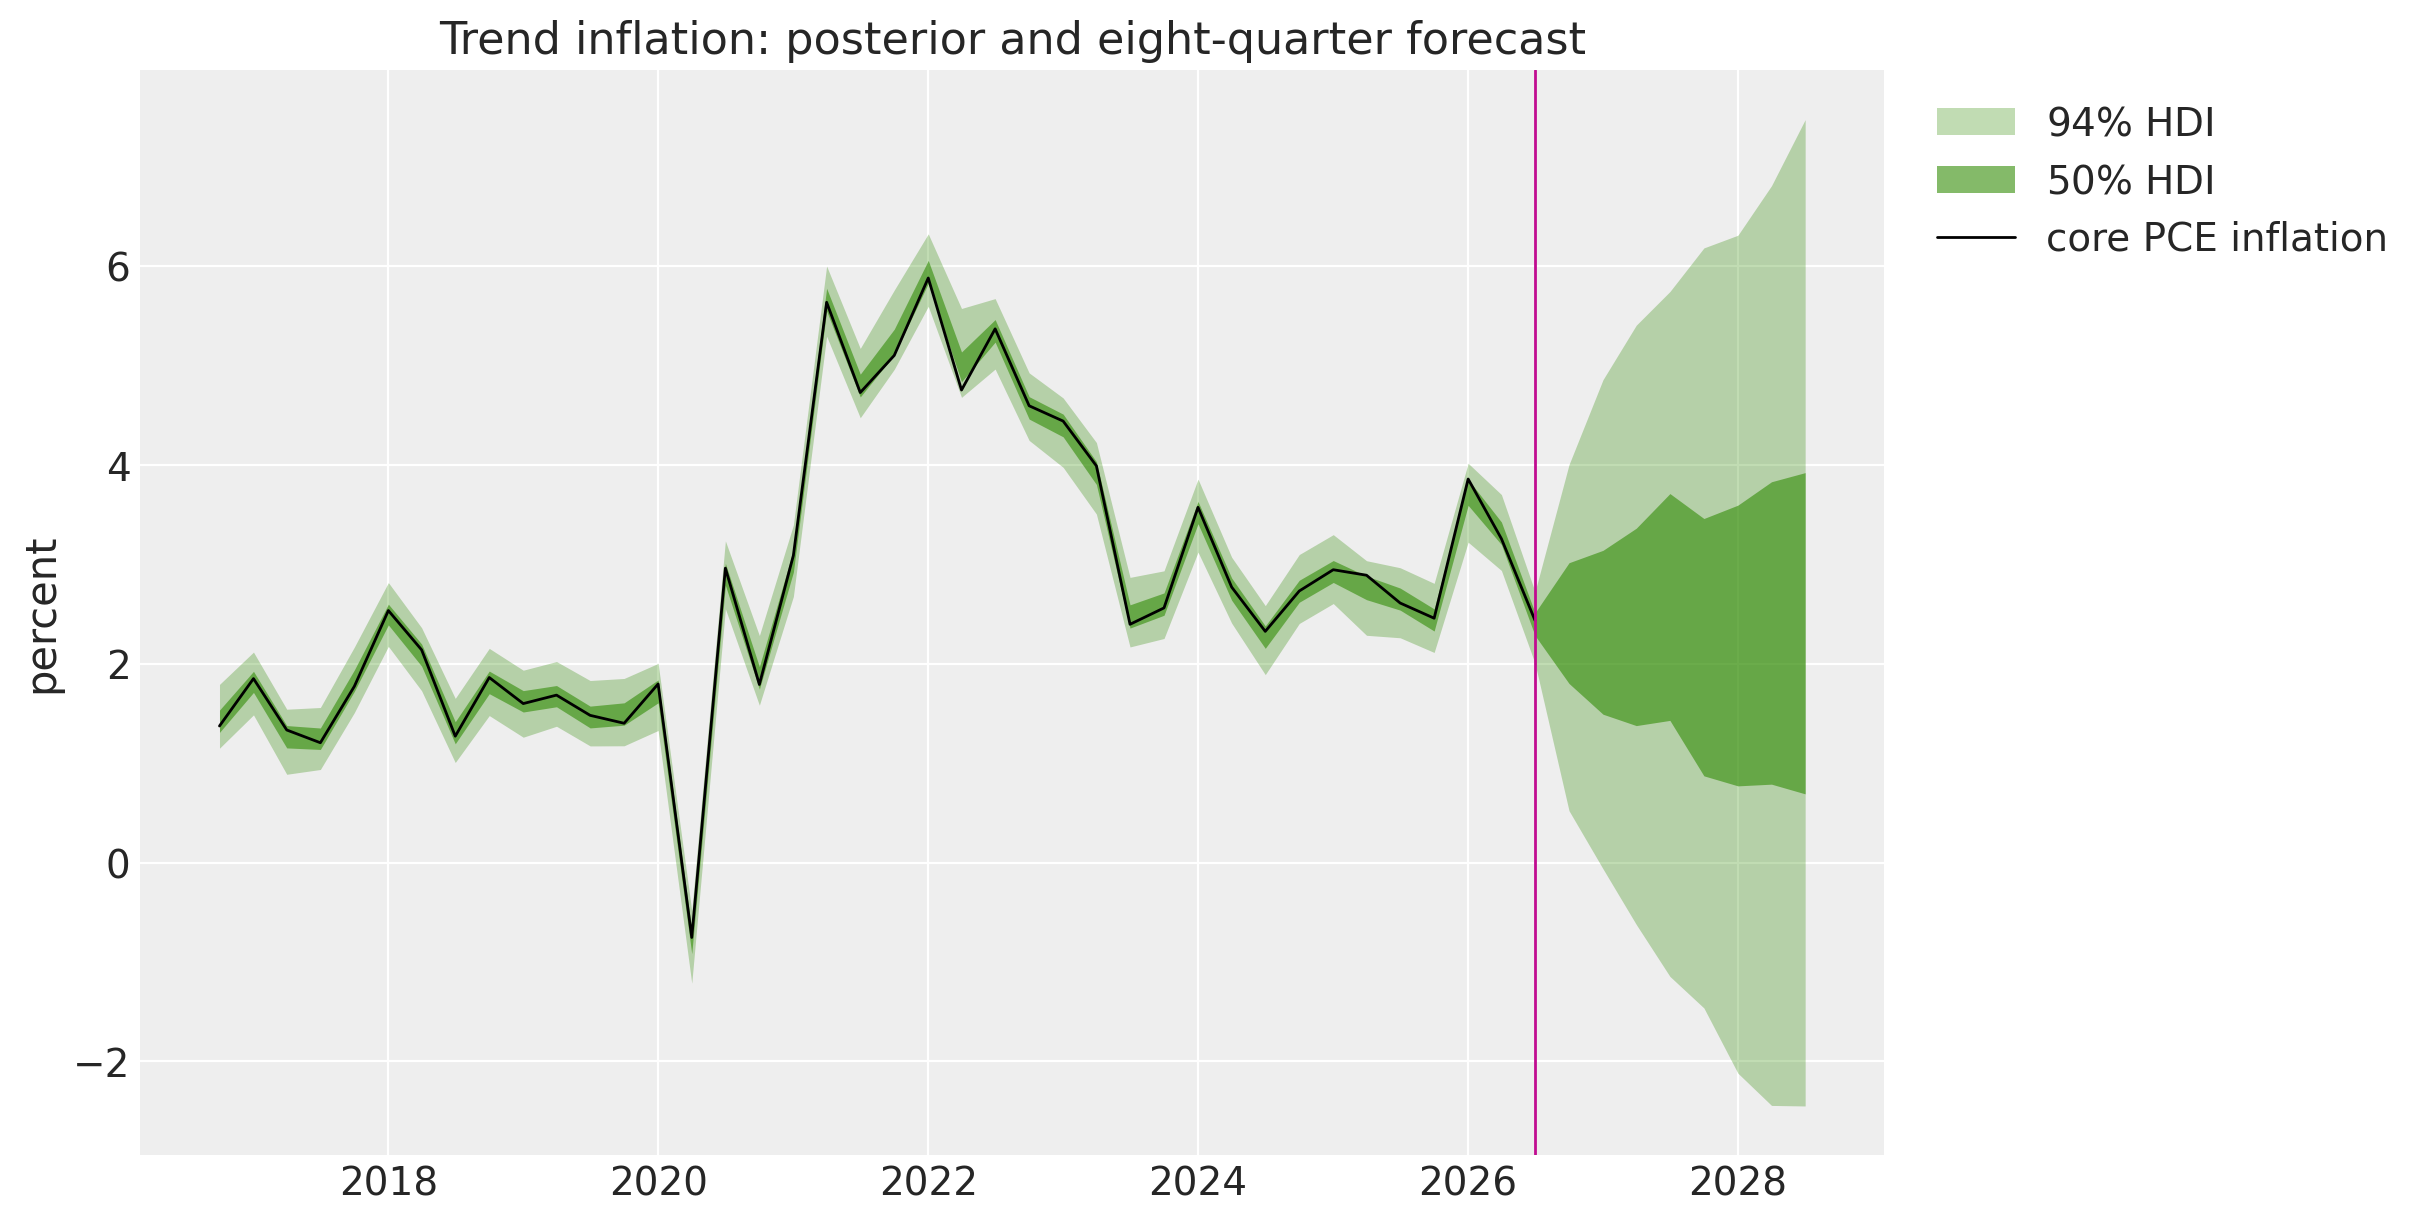

In [17]:
trend_horizon = np.asarray(
    Predictive(model, mcmc.get_samples(), return_sites=["trend"])(
        key_trend, covariates_full, rates
    )["trend"]
)  # (samples, quarters + 8, 1)
horizon_date_num = np.concatenate([date_num, future_date_num])

pc, band_handles = plot_bands(
    trend_horizon[:, plot_start:], horizon_date_num[plot_start:], ["trend"], color="C2"
)
ax = pc.viz["figure"].item().axes[0]
(core_line,) = ax.plot(
    date_num[plot_start:], rates[plot_start:, -1], color="black", lw=1, label="core PCE inflation"
)
ax.axvline(date_num[-1], color="C3", lw=1, label="last observation")
ax.legend(handles=[*band_handles, core_line], loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(title="Trend inflation: posterior and eight-quarter forecast", ylabel="percent");

In sample the trend band is narrower than the smoothed fit of core PCE ($0.7$ points wide against $1.1$ in 2026Q3), because the gap noise is not in it. Over the horizon the two bands are the same width within the Monte Carlo noise of the draws: the trend band is $3.5$ points wide after one quarter and $9.9$ after eight. The gap noise of core PCE, $0.2$ points, adds nothing visible to a trend whose own standard deviation is $0.9$ points after one quarter, so the forecast uncertainty of core PCE is the uncertainty of where the trend goes.

## Backtest

The forecast from the last observation cannot be scored before 2028. To score the model now we run a rolling-origin evaluation with [`backtest`](../../reference/evaluate.backtest.html): the first forecast origin is 1985Q1, every fourth quarter after it is another origin, the training window expands from the start of the sample to the origin (so each fit uses all the revised data up to that date), and the horizon is eight quarters. That is 40 windows, the last one with origin 2024Q1, and the forecasts cover 1985 to 2025: the end of the Great Moderation, the 2008 recession, the long undershoot of the 2010s and the 2021 surge.

The ladder has four models, each adding one component to the previous one, and the benchmark:

- **AO**: the Atkeson and Ohanian random walk, a point forecast.
- **M0**: core PCE only, constant variances (`num_measures=1`, `stochastic_volatility=False`).
- **M1**: core PCE only, stochastic volatility: the UCSV model of Stock and Watson (2007).
- **M2**: all four measures, stochastic volatility: the model of this notebook.
- **M2-t**: M2 with Student-t gaps.

Every window fits the model with four NUTS chains of $1{,}000$ warmup and $250$ draws, so that a window takes a fraction of the full fit while the metrics still see $1{,}000$ forecast draws. `forecast_fn` records the divergences of every window, so that the scores can be checked against the fits that produced them. The CRPS and the MAE of *Evaluation metrics and the benchmark* are scored per window, on the core PCE column: `on_core_pce` and `four_quarter_average` turn a package metric into one on that column and on the 4-quarter average, and `atkeson_ohanian` is a per-window metric that reads the last four quarters of the training window through the `per_window_metrics` hook of `backtest`. The coverage comes later, per horizon step, from the stored forecast draws.

In [18]:
BACKTEST_WARMUP = 1_000
BACKTEST_SAMPLES = 1_000
backtest_divergences: list[tuple[str, np.datetime64, int]] = []  # (rung, origin, divergences)


def make_forecast_fn(label: str) -> ForecastFn:
    """Build the ``forecast_fn`` of `backtest` for one rung: a NUTS fit, then `forecast`."""

    def forecast_fn(
        rng_key: Array,
        model: ForecastModel,
        train_data: Array,
        train_covariates: Array,
        full_covariates: Array,
        num_samples: int,
        *,
        batch_size: int | None = None,
    ) -> Array:
        key_fit, key_forecast = random.split(rng_key)
        mcmc, _ = fit_nuts(
            key_fit,
            model,
            train_data,
            num_warmup=BACKTEST_WARMUP,
            num_samples=num_samples // NUM_CHAINS,
        )
        backtest_divergences.append((label, dates[train_data.shape[0]], num_divergences(mcmc)))
        return forecast(
            key_forecast,
            model,
            mcmc.get_samples(),
            train_data,
            full_covariates,
            batch_size=batch_size,
        )

    return forecast_fn


def on_core_pce(metric: Metric) -> Metric:
    """Score ``metric`` on the core PCE column (the last one) only."""

    def scored(pred: Array, truth: Array) -> Array:
        return metric(pred[..., -1:], truth[..., -1:])

    return scored


def four_quarter_average(metric: Metric) -> Metric:
    """Score ``metric`` on the average of the first four quarters of core PCE."""

    def scored(pred: Array, truth: Array) -> Array:
        return metric(pred[:, :4, -1].mean(axis=-1), truth[:4, -1].mean())

    return scored


def atkeson_ohanian(train: Array) -> tuple[Metric, Metric]:
    """MAE of the Atkeson and Ohanian forecast on the quarterly rates and the 4-quarter average.

    The forecast is the mean core PCE inflation of the last four quarters of ``train``, held
    flat over the horizon; ``pred`` is ignored.
    """
    point = train[-4:, -1].mean()

    def quarterly(pred: Array, truth: Array) -> Array:
        return jnp.abs(truth[:, -1] - point).mean()

    def annual(pred: Array, truth: Array) -> Array:
        return jnp.abs(truth[:4, -1].mean() - point)

    return quarterly, annual


def benchmark_metrics(t0: int, t1: int, t2: int) -> dict[str, Metric]:
    """Return the two Atkeson and Ohanian scores of the window ``(t0, t1, t2)``."""
    quarterly, annual = atkeson_ohanian(rates[t0:t1])
    return {"mae_ao": quarterly, "mae_4q_ao": annual}


METRICS = {
    "crps": on_core_pce(eval_crps),
    "mae": on_core_pce(eval_mae),
    "crps_4q": four_quarter_average(eval_crps),
    "mae_4q": four_quarter_average(eval_mae),
}
BACKTEST_OPTIONS = {
    "min_train_window": 103,  # first origin 1985Q1
    "test_window": HORIZON,
    "stride": 4,
    "num_samples": BACKTEST_SAMPLES,
    "metrics": METRICS,
    "per_window_metrics": benchmark_metrics,
    "keep_predictions": True,
}

assert dates[BACKTEST_OPTIONS["min_train_window"]] == np.datetime64("1985-01-01")


def run_backtest(
    rng_key: Array, label: str, model_fn: ModelFactory, data: Array
) -> list[BacktestResult]:
    """Backtest one rung of the ladder on ``data`` with the shared window settings."""
    return backtest(
        rng_key,
        model_fn,
        data,
        jnp.zeros((data.shape[0], 0)),
        forecast_fn=make_forecast_fn(label),
        **BACKTEST_OPTIONS,
    )

In [19]:
core_pce = rates[:, -1:]  # (quarters, 1): the univariate rungs see core PCE only
LADDER: dict[str, tuple[ModelFactory, Array]] = {
    "M0": (partial(make_trend_inflation_model, 1, stochastic_volatility=False), core_pce),
    "M1": (partial(make_trend_inflation_model, 1), core_pce),
    "M2": (partial(make_trend_inflation_model, num_measures), rates),
    "M2-t": (partial(make_trend_inflation_model, num_measures, student_t=True), rates),
}
RUNG_COLORS = {"AO": "C4", "M0": "C1", "M1": "C2", "M2": "C0", "M2-t": "C3"}
backtest_results: dict[str, list[BacktestResult]] = {}

for label, (model_fn, data) in LADDER.items():
    rng_key, key_backtest = random.split(rng_key)
    backtest_results[label] = run_backtest(key_backtest, label, model_fn, data)

origins = np.array([dates[result.t1] for result in backtest_results["M2"]])

assert len(origins) == 40

The first figure is the summary: every metric averaged over the 40 windows, one bar per rung, with the Atkeson and Ohanian benchmark as a line in the MAE panels.

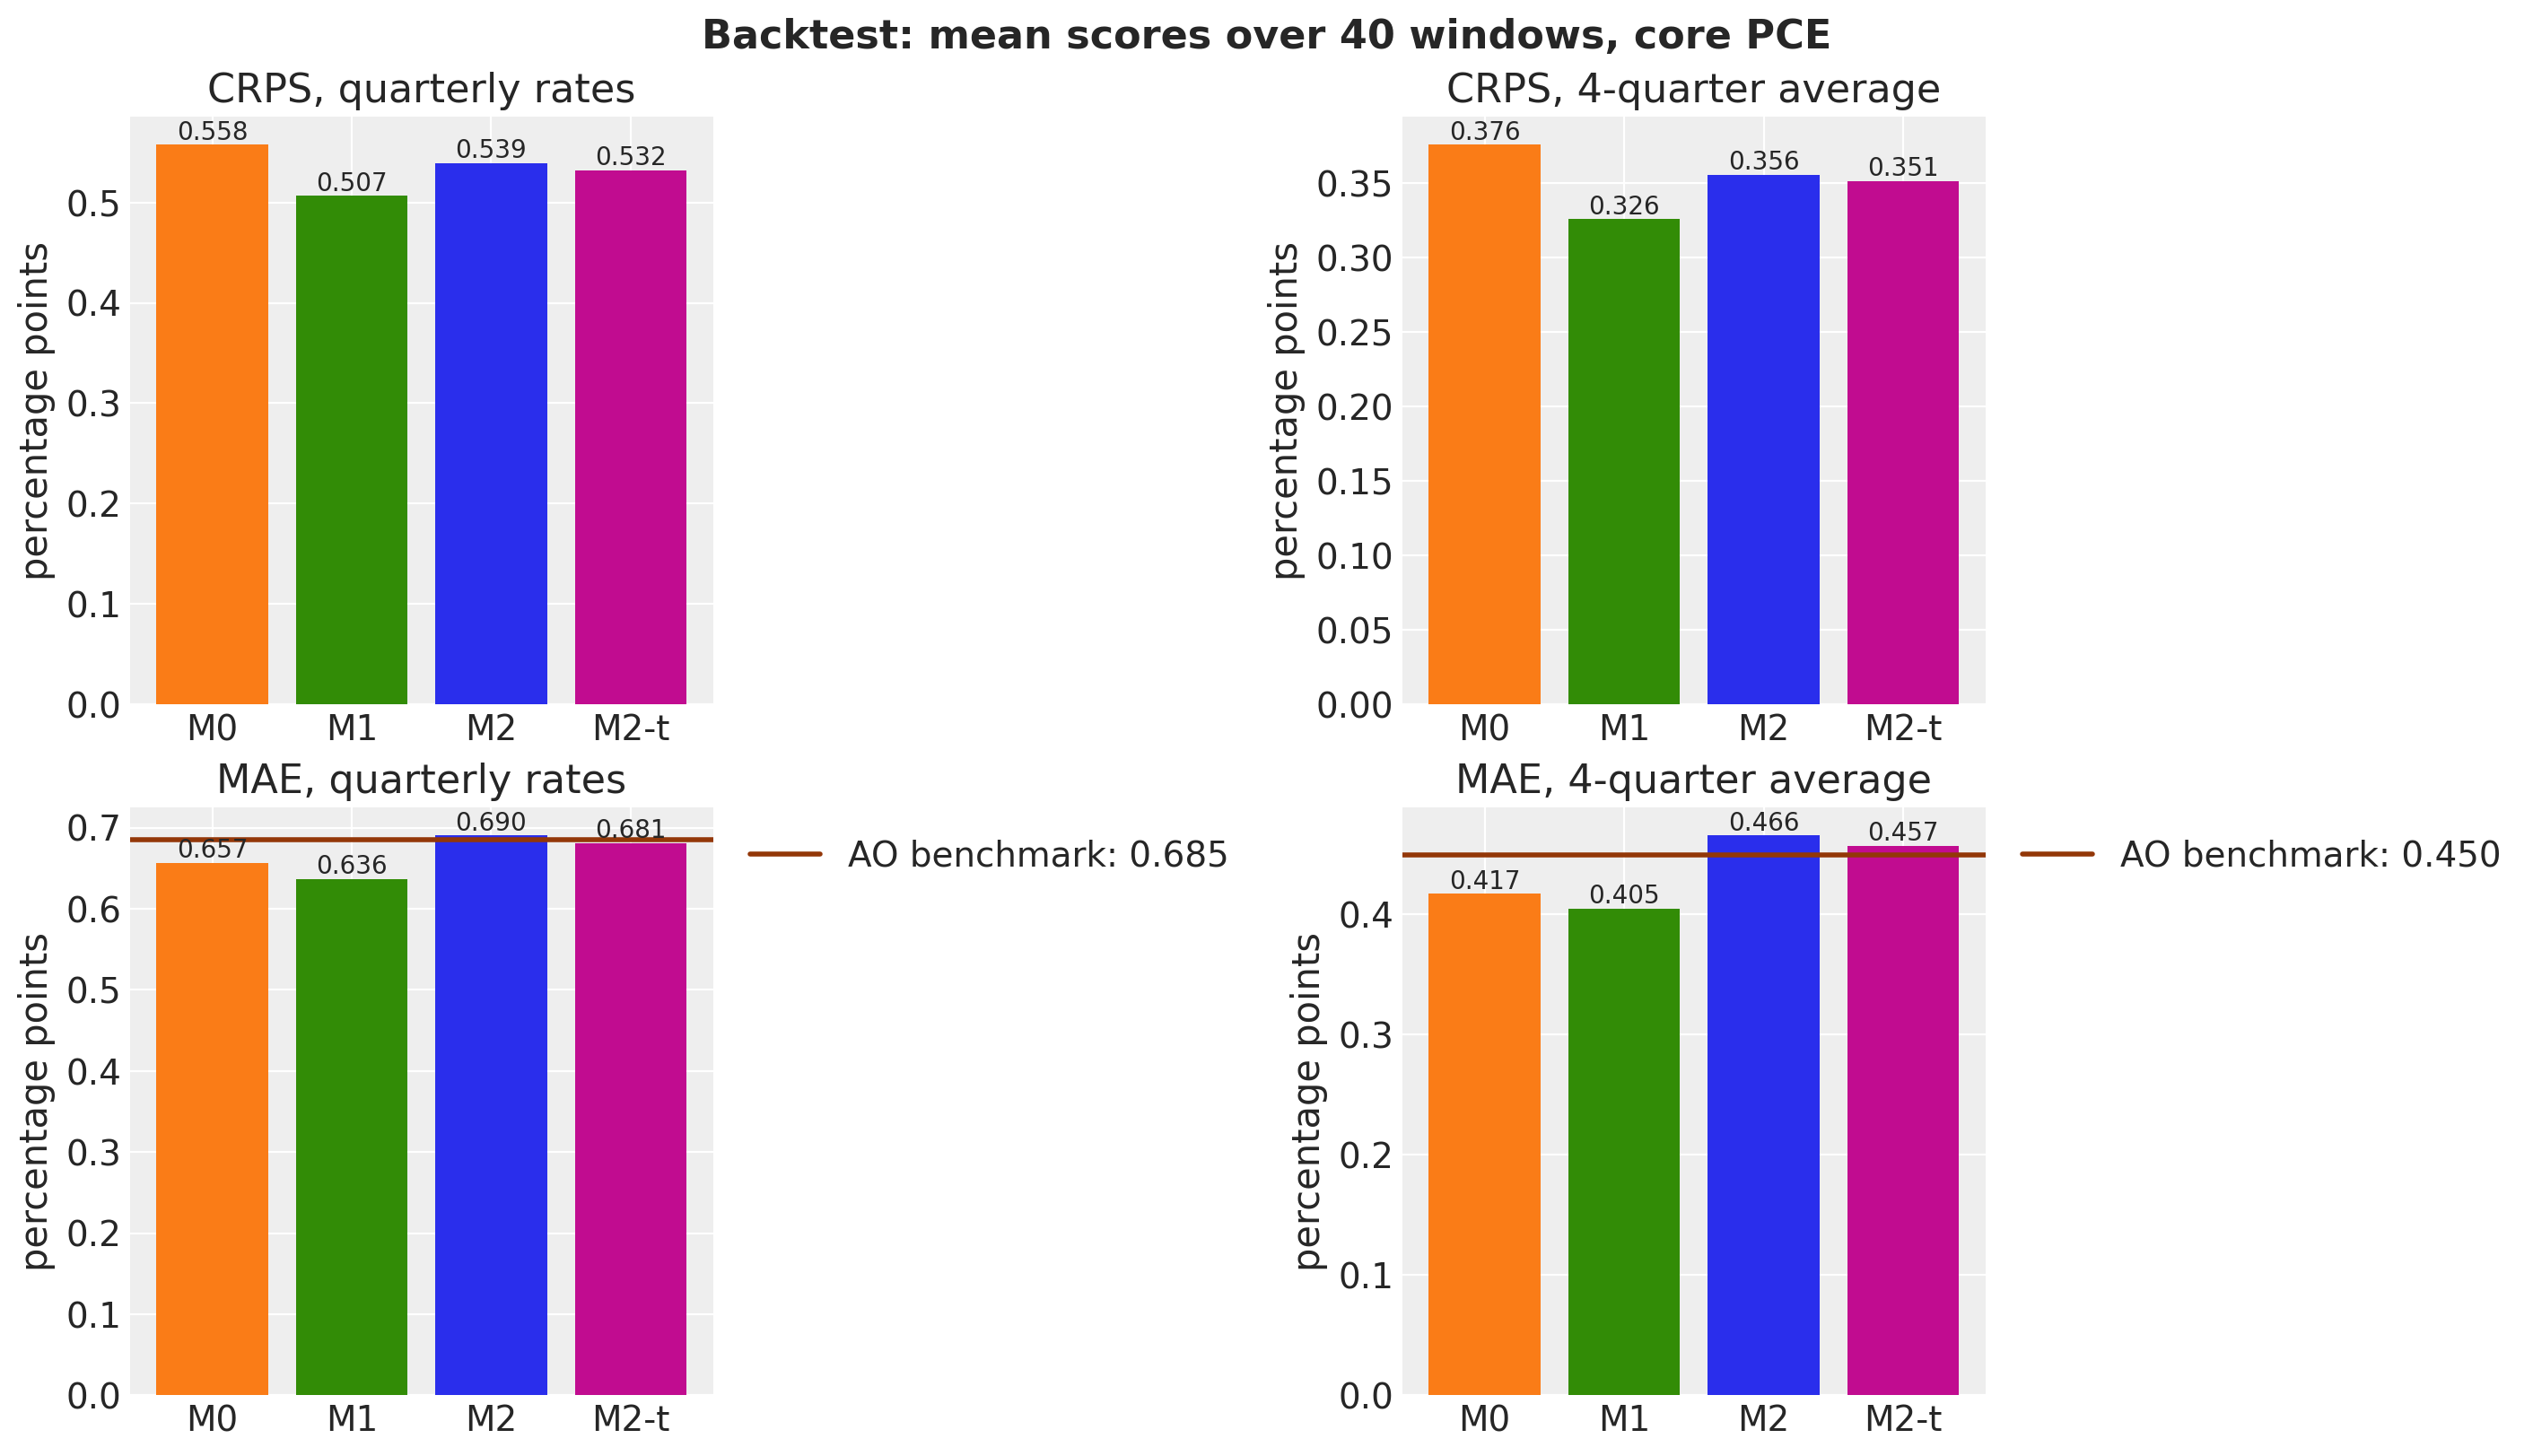

In [20]:
def metric_values(results: list[BacktestResult], metric: str) -> np.ndarray:
    """Return the per-window values of ``metric`` from ``results``, shape ``(windows,)``."""
    return np.array([result.metrics[metric] for result in results])


def plot_rung_bars(ax: plt.Axes, metric: str, title: str, benchmark: str | None = None) -> None:
    """Bar chart of the window mean of ``metric`` per rung, with the benchmark as a line."""
    labels = list(backtest_results)
    means = [metric_values(backtest_results[label], metric).mean() for label in labels]
    bars = ax.bar(labels, means, color=[RUNG_COLORS[label] for label in labels])
    ax.bar_label(bars, fmt="%.3f")
    if benchmark is not None:
        benchmark_mean = metric_values(backtest_results["M0"], benchmark).mean()
        ax.axhline(
            benchmark_mean,
            color=RUNG_COLORS["AO"],
            lw=2,
            label=f"AO benchmark: {benchmark_mean:.3f}",
        )
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.set(title=title, ylabel="percentage points")


fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 8), layout="constrained")
plot_rung_bars(axes[0, 0], "crps", "CRPS, quarterly rates")
plot_rung_bars(axes[0, 1], "crps_4q", "CRPS, 4-quarter average")
plot_rung_bars(axes[1, 0], "mae", "MAE, quarterly rates", benchmark="mae_ao")
plot_rung_bars(axes[1, 1], "mae_4q", "MAE, 4-quarter average", benchmark="mae_4q_ao")
fig.suptitle("Backtest: mean scores over 40 windows, core PCE", fontsize=16, fontweight="bold");

Each step of the ladder changes the scores as follows:

- M0 to M1, adding stochastic volatility to the univariate model, lowers the CRPS from $0.558$ to $0.507$ on the quarterly rates and from $0.376$ to $0.326$ on the 4-quarter average, and the MAE from $0.657$ to $0.636$ and from $0.417$ to $0.405$. Every score improves.
- M1 to M2, adding the three other measures, raises the CRPS to $0.539$ and $0.356$ and the MAE to $0.690$ and $0.466$. On average over the 40 windows, pooling does not help the core PCE forecast.
- M2 to M2-t, the Student-t gaps, moves every score by less than $0.01$ in the direction of M1: $0.532$, $0.351$, $0.681$ and $0.457$.
- The Atkeson and Ohanian benchmark has an MAE of $0.685$ on the quarterly rates and $0.450$ on the 4-quarter average. M0 and M1 beat it on both; M2 and M2-t do not.

The benchmark is hard for the reason Atkeson and Ohanian gave: on the 4-quarter average, the last year of inflation is as good a point forecast as a model of its persistent part. M1 beats it by $0.045$ points, a tenth of the score. The next figures say where in time the differences come from and whether they are larger than their noise.

The next figure shows the CRPS of every window against its origin date, one line per rung, so that the periods where one component helps stand out.

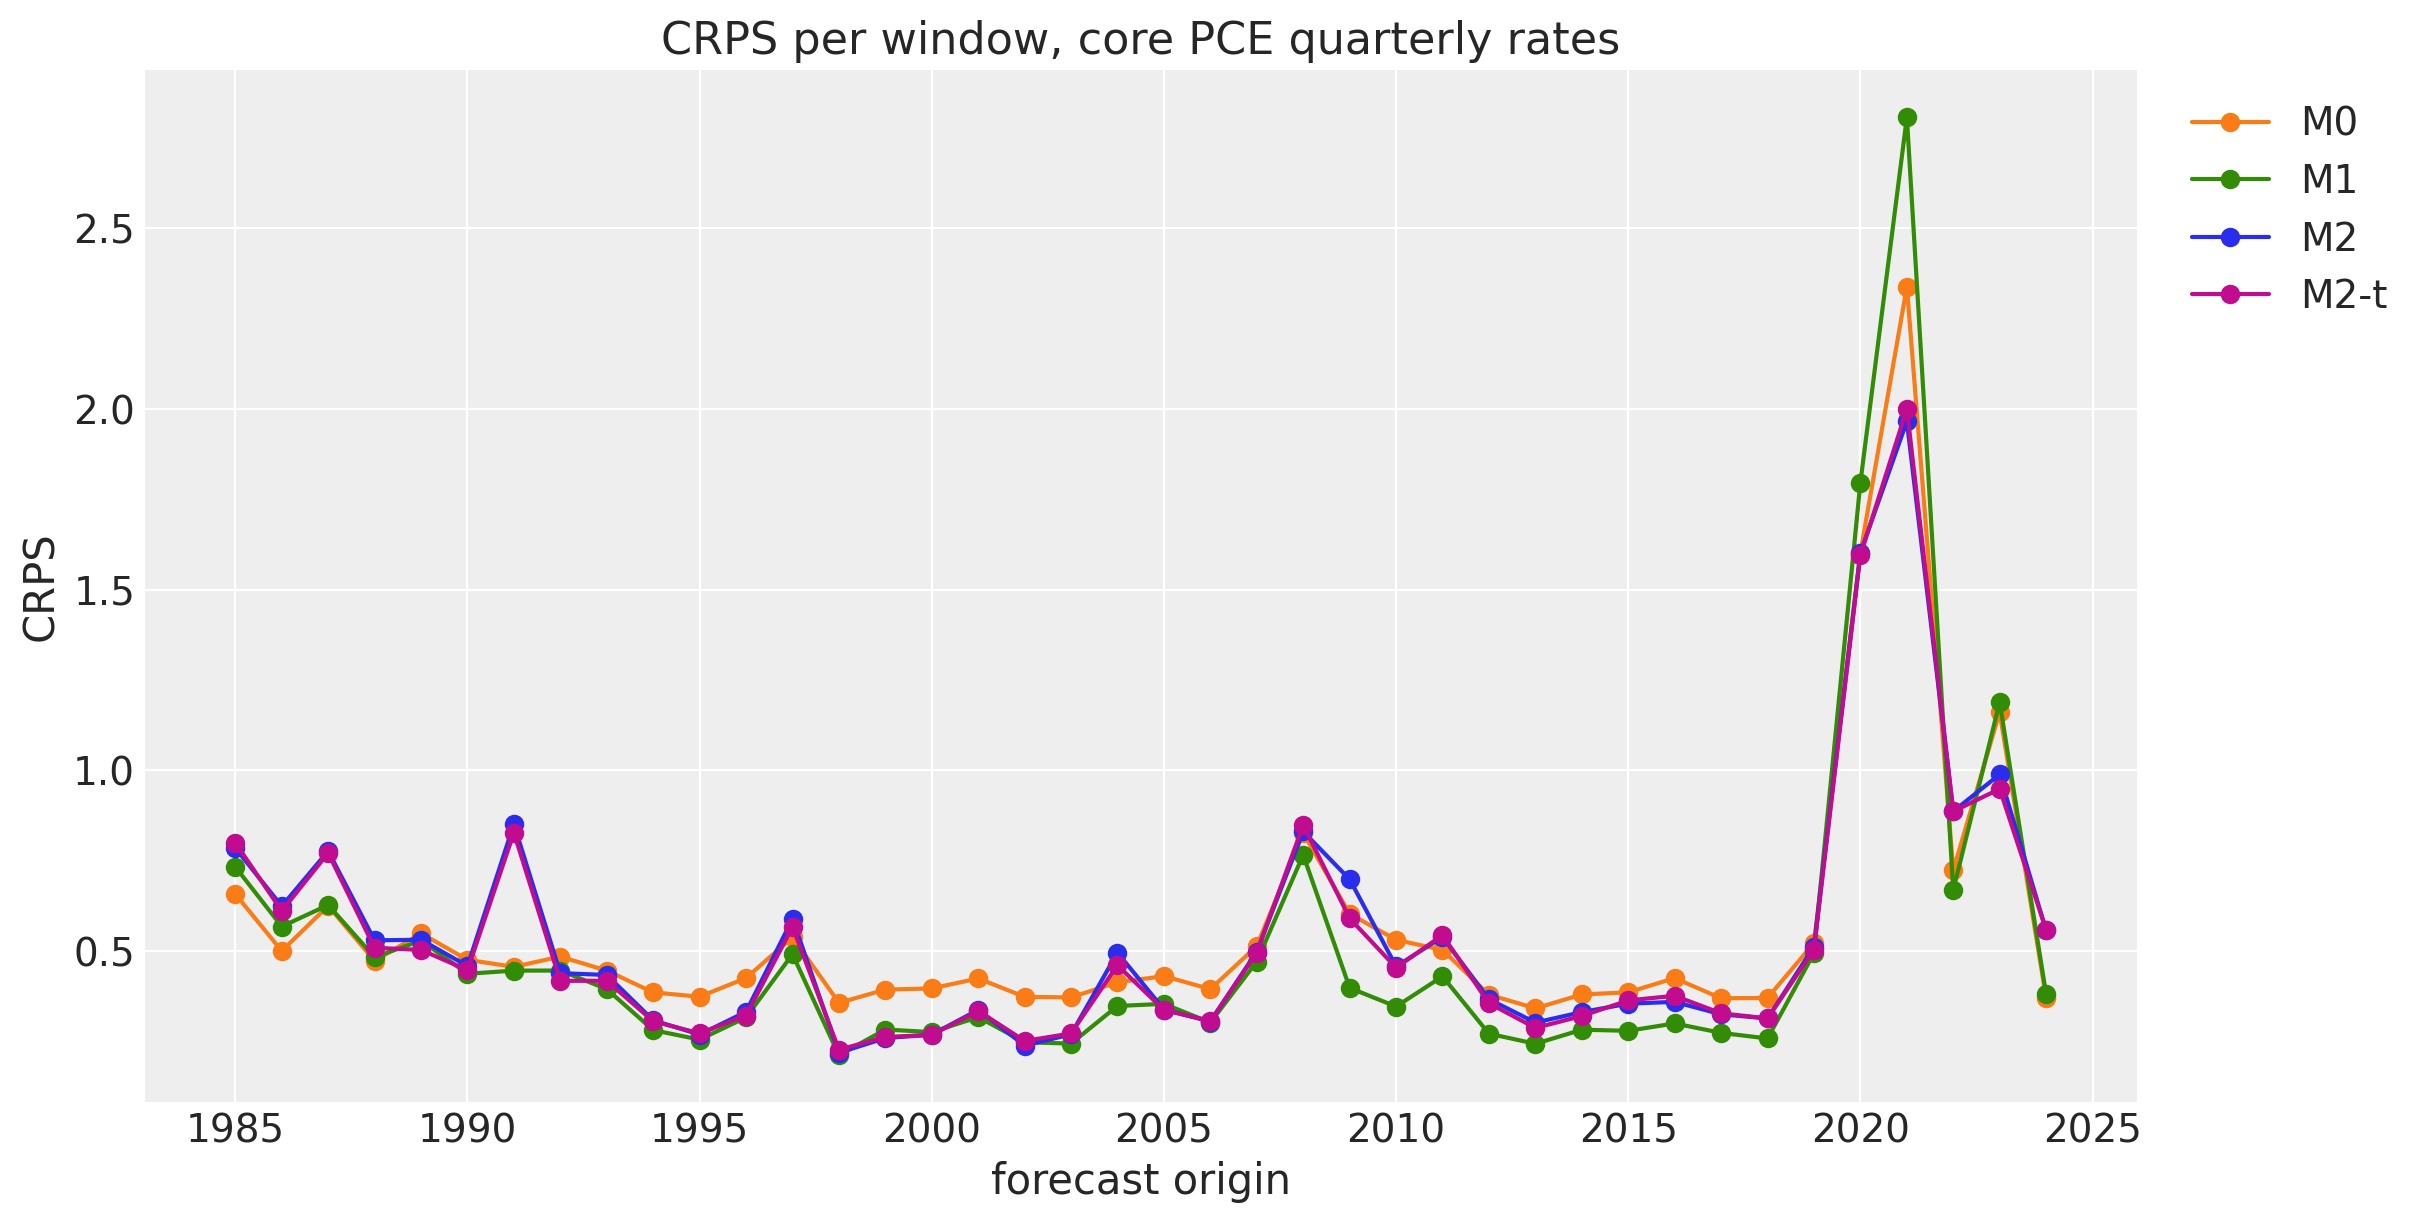

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))

for label, results in backtest_results.items():
    ax.plot(
        origins, metric_values(results, "crps"), marker="o", color=RUNG_COLORS[label], label=label
    )

locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(title="CRPS per window, core PCE quarterly rates", xlabel="forecast origin", ylabel="CRPS");

The per-origin scores separate three periods:

- From 1985 to 2019 the scores stay between $0.25$ and $0.85$, and the four rungs are within $0.1$ of each other at most origins. The two exceptions are 1991, where M2 and M2-t score $0.85$ against $0.45$ for the univariate rungs, and 2009 to 2018, where M1 is the lowest at every origin: with the trend volatility near its 2010 level, the univariate bands are tighter and the realized quarters stay inside them.
- The 2020 and 2021 origins dominate the averages. At the 2021Q1 origin M1 scores $2.8$, M0 $2.3$, and M2 and M2-t $2.0$: the multi-measure models are the least wrong there. That single window adds $0.07$ to the 40-window mean of M1 and accounts for $0.02$ of its gap to M2.
- The 2022 to 2024 origins, the disinflation, score between $0.35$ and $1.2$ for every rung, with M1 and M2 alternating.

The paired differences in the next figure put a standard error on these gaps.

A difference of means over 40 windows can be noise. For each step of the ladder we take the paired per-window difference in CRPS (the model with the component minus the model without it, on the same windows) and show its mean with two standard errors. The standard error treats the windows as independent; consecutive windows share four of their eight quarters, so it understates the uncertainty, and a bar that reaches zero is a difference the backtest cannot establish.

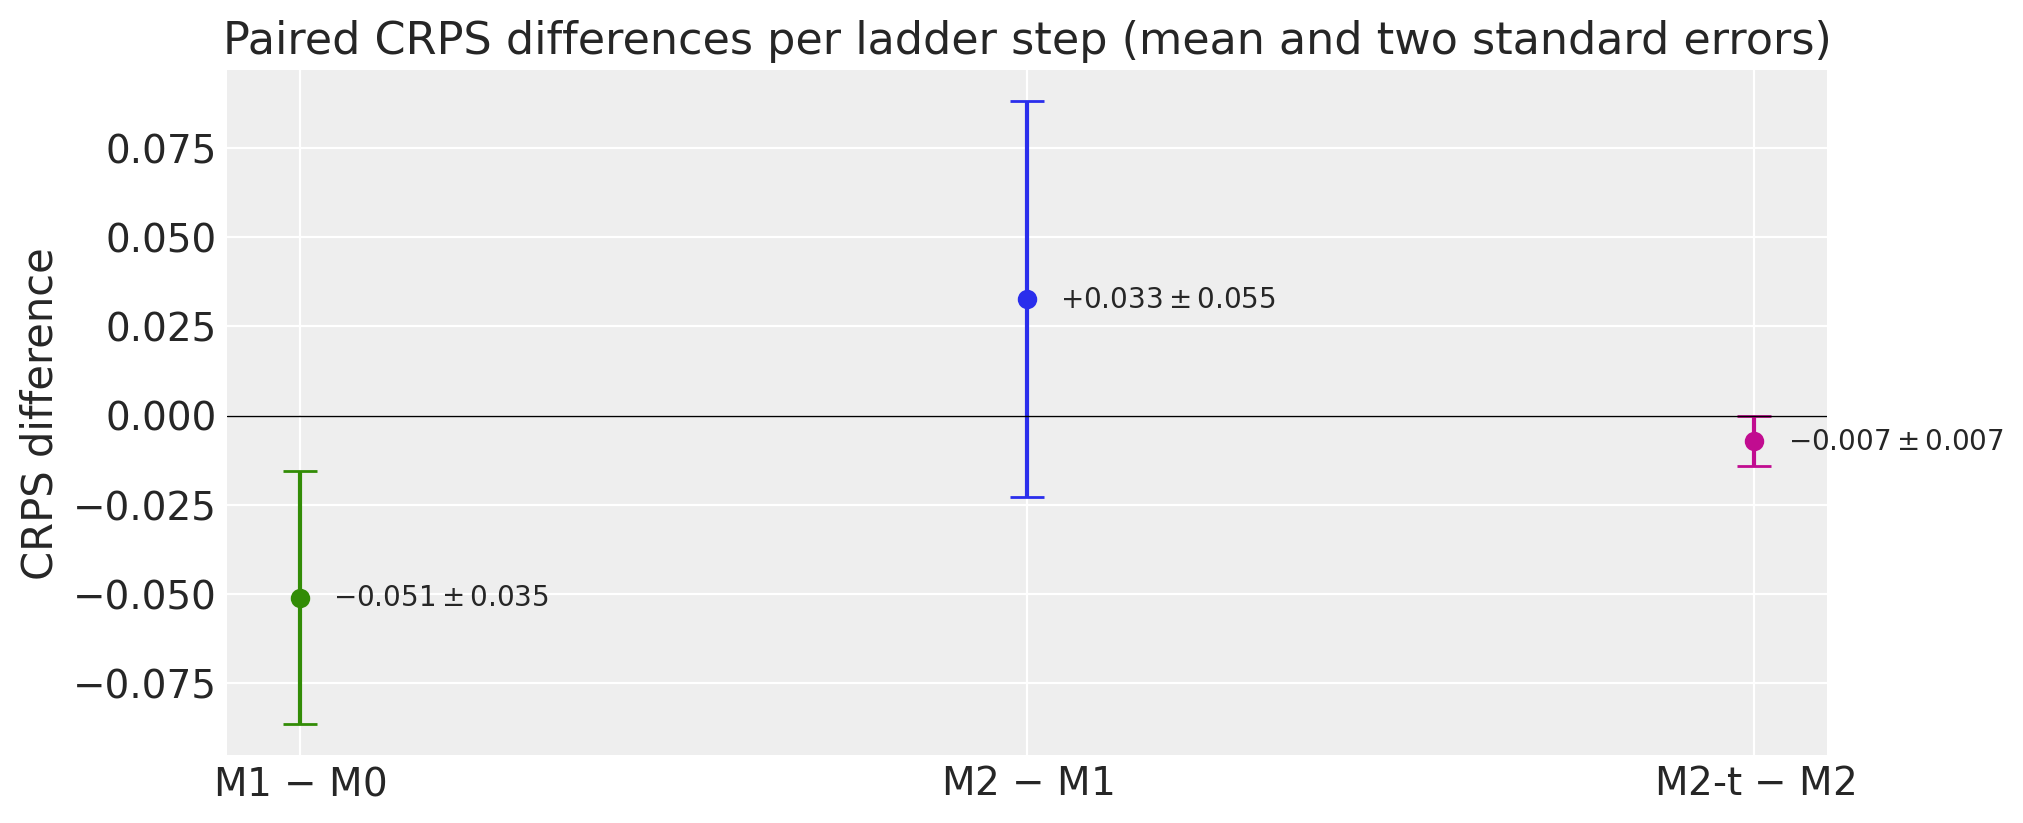

In [22]:
PAIRS = (("M1", "M0"), ("M2", "M1"), ("M2-t", "M2"))

fig, ax = plt.subplots(figsize=(10, 4))

for position, (with_component, without) in enumerate(PAIRS):
    difference = metric_values(backtest_results[with_component], "crps") - metric_values(
        backtest_results[without], "crps"
    )
    mean, two_se = difference.mean(), 2 * difference.std(ddof=1) / np.sqrt(len(difference))
    ax.errorbar(position, mean, yerr=two_se, fmt="o", color=RUNG_COLORS[with_component], capsize=6)
    ax.annotate(
        rf"${mean:+.3f} \pm {two_se:.3f}$",
        (position, mean),
        xytext=(12, 0),
        textcoords="offset points",
        va="center",
    )

ax.axhline(0.0, color="black", lw=0.5)
ax.set(
    xticks=range(len(PAIRS)),
    xticklabels=[f"{a} $-$ {b}" for a, b in PAIRS],
    title="Paired CRPS differences per ladder step (mean and two standard errors)",
    ylabel="CRPS difference",
);

The paired differences settle one step of the ladder and leave the other two open.

- M1 $-$ M0: $-0.051 \pm 0.035$. Stochastic volatility improves the CRPS, and the interval excludes zero.
- M2 $-$ M1: $+0.033 \pm 0.055$. Pooling costs on average, but the interval includes zero: the 2021 windows pull the difference down, the 2009 to 2018 windows push it up, and 40 overlapping windows cannot separate the two.
- M2-t $-$ M2: $-0.007 \pm 0.007$. The Student-t gaps help by a small amount on average, with little spread across windows, and the interval touches zero.

The first result is the only one to take at face value; the other two intervals include zero before the overlap of the windows is accounted for.

The scores so far average over the eight horizon steps. The stored forecast draws let us score each step on its own: the CRPS at horizon $h$ and the coverage of the two central intervals at horizon $h$, averaged over the windows. Forty windows give one realized value per step, so the coverage of a calibrated forecast scatters around the nominal level with a binomial standard deviation of $\sqrt{0.94 \times 0.06 / 40} \approx 3.8$ percentage points at the $94\%$ level and $7.9$ at the $50\%$ level; the shaded band in the coverage panels is two of those standard deviations around the nominal level.

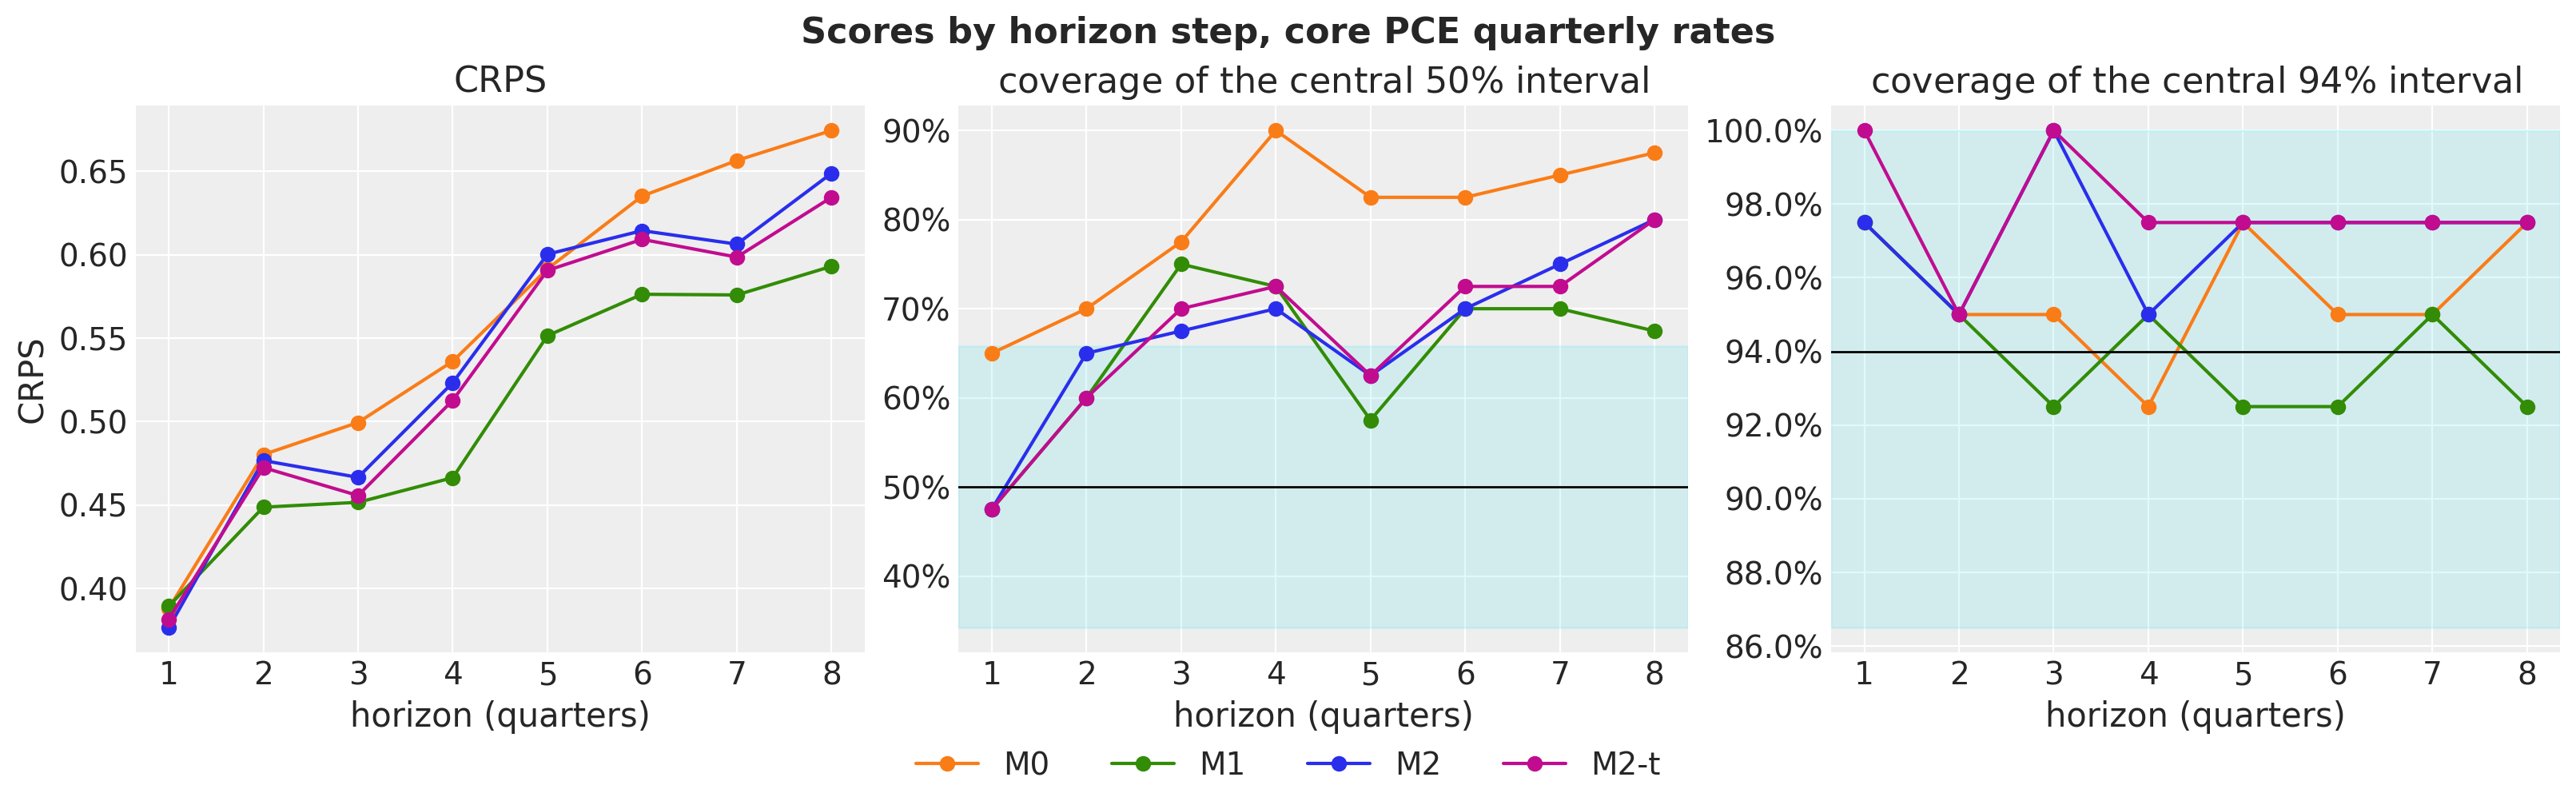

In [23]:
def per_horizon_scores(results: list[BacktestResult]) -> dict[str, np.ndarray]:
    """CRPS and central-interval coverage of core PCE at each horizon step, over the windows."""
    draws = jnp.stack([jnp.asarray(result.prediction)[..., -1] for result in results])  # (w, s, h)
    truth = jnp.stack([rates[result.t1 : result.t2, -1] for result in results])  # (windows, h)
    scores = {"crps": jax.vmap(crps_empirical)(draws, truth).mean(axis=0)}

    for prob in (0.5, 0.94):
        lower = jnp.quantile(draws, (1.0 - prob) / 2.0, axis=1)  # (windows, h)
        upper = jnp.quantile(draws, (1.0 + prob) / 2.0, axis=1)  # (windows, h)
        inside = (truth >= lower) & (truth <= upper)
        scores[f"coverage_{prob:.0%}"] = inside.mean(axis=0)

    return {name: np.asarray(value) for name, value in scores.items()}


horizon_scores = {
    label: per_horizon_scores(results) for label, results in backtest_results.items()
}
horizon_steps = np.arange(1, HORIZON + 1)

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 5), layout="constrained")

for label, scores in horizon_scores.items():
    axes[0].plot(horizon_steps, scores["crps"], marker="o", color=RUNG_COLORS[label], label=label)
    axes[1].plot(horizon_steps, scores["coverage_50%"], marker="o", color=RUNG_COLORS[label])
    axes[2].plot(horizon_steps, scores["coverage_94%"], marker="o", color=RUNG_COLORS[label])

for ax, prob in zip(axes[1:], (0.5, 0.94), strict=True):
    binomial_sd = np.sqrt(prob * (1 - prob) / len(origins))
    ax.axhline(prob, color="black", lw=1)
    ax.axhspan(prob - 2 * binomial_sd, min(1.0, prob + 2 * binomial_sd), color="C5", alpha=0.2)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
    ax.set(title=rf"coverage of the central ${prob:.0%}$ interval".replace("%", r"\%"))

axes[0].set(title="CRPS", ylabel="CRPS")
fig.legend(loc="outside lower center", ncols=len(horizon_scores))

for ax in axes:
    ax.set(xlabel="horizon (quarters)", xticks=horizon_steps)

fig.suptitle("Scores by horizon step, core PCE quarterly rates", fontsize=16, fontweight="bold");

The scores change with the horizon step in three ways:

- The CRPS rises from $0.38$ at one quarter, where the four rungs coincide, to $0.59$ (M1), $0.63$ (M2-t), $0.65$ (M2) and $0.67$ (M0) at eight quarters. The gain of M1 is in the horizons from four quarters on.
- The $94\%$ intervals are calibrated at every horizon: the coverage stays between $92.5\%$ and $100\%$, inside the binomial band of $\pm 7.5$ points around the nominal level.
- The $50\%$ intervals are too wide beyond the first quarter. At one quarter the coverage is $48\%$ to $65\%$, on target. From the second quarter on it climbs, to $67\%$ (M1), $80\%$ (M2 and M2-t) and $88\%$ (M0) at eight quarters, above the binomial band of $\pm 16$ points at most horizons, with M0 the widest and M1 the closest to the nominal level.

A $50\%$ interval that covers $80\%$ of the outcomes while the $94\%$ interval covers $95\%$ means the forecast distribution has the right tails and too much mass in the shoulders: the random-walk trend spreads the center of the distribution faster than core PCE moves over two years. The realized path stays closer to the origin than the model's center expects; a trend with some mean reversion would narrow the center.

The stored draws also let us look at one origin in detail. 2021Q1 is the origin just before the surge: the last observed quarter is 2020Q4, and the next eight quarters are the fastest core inflation since the early 1980s. We plot the forecast of every rung from that origin against the realized path.

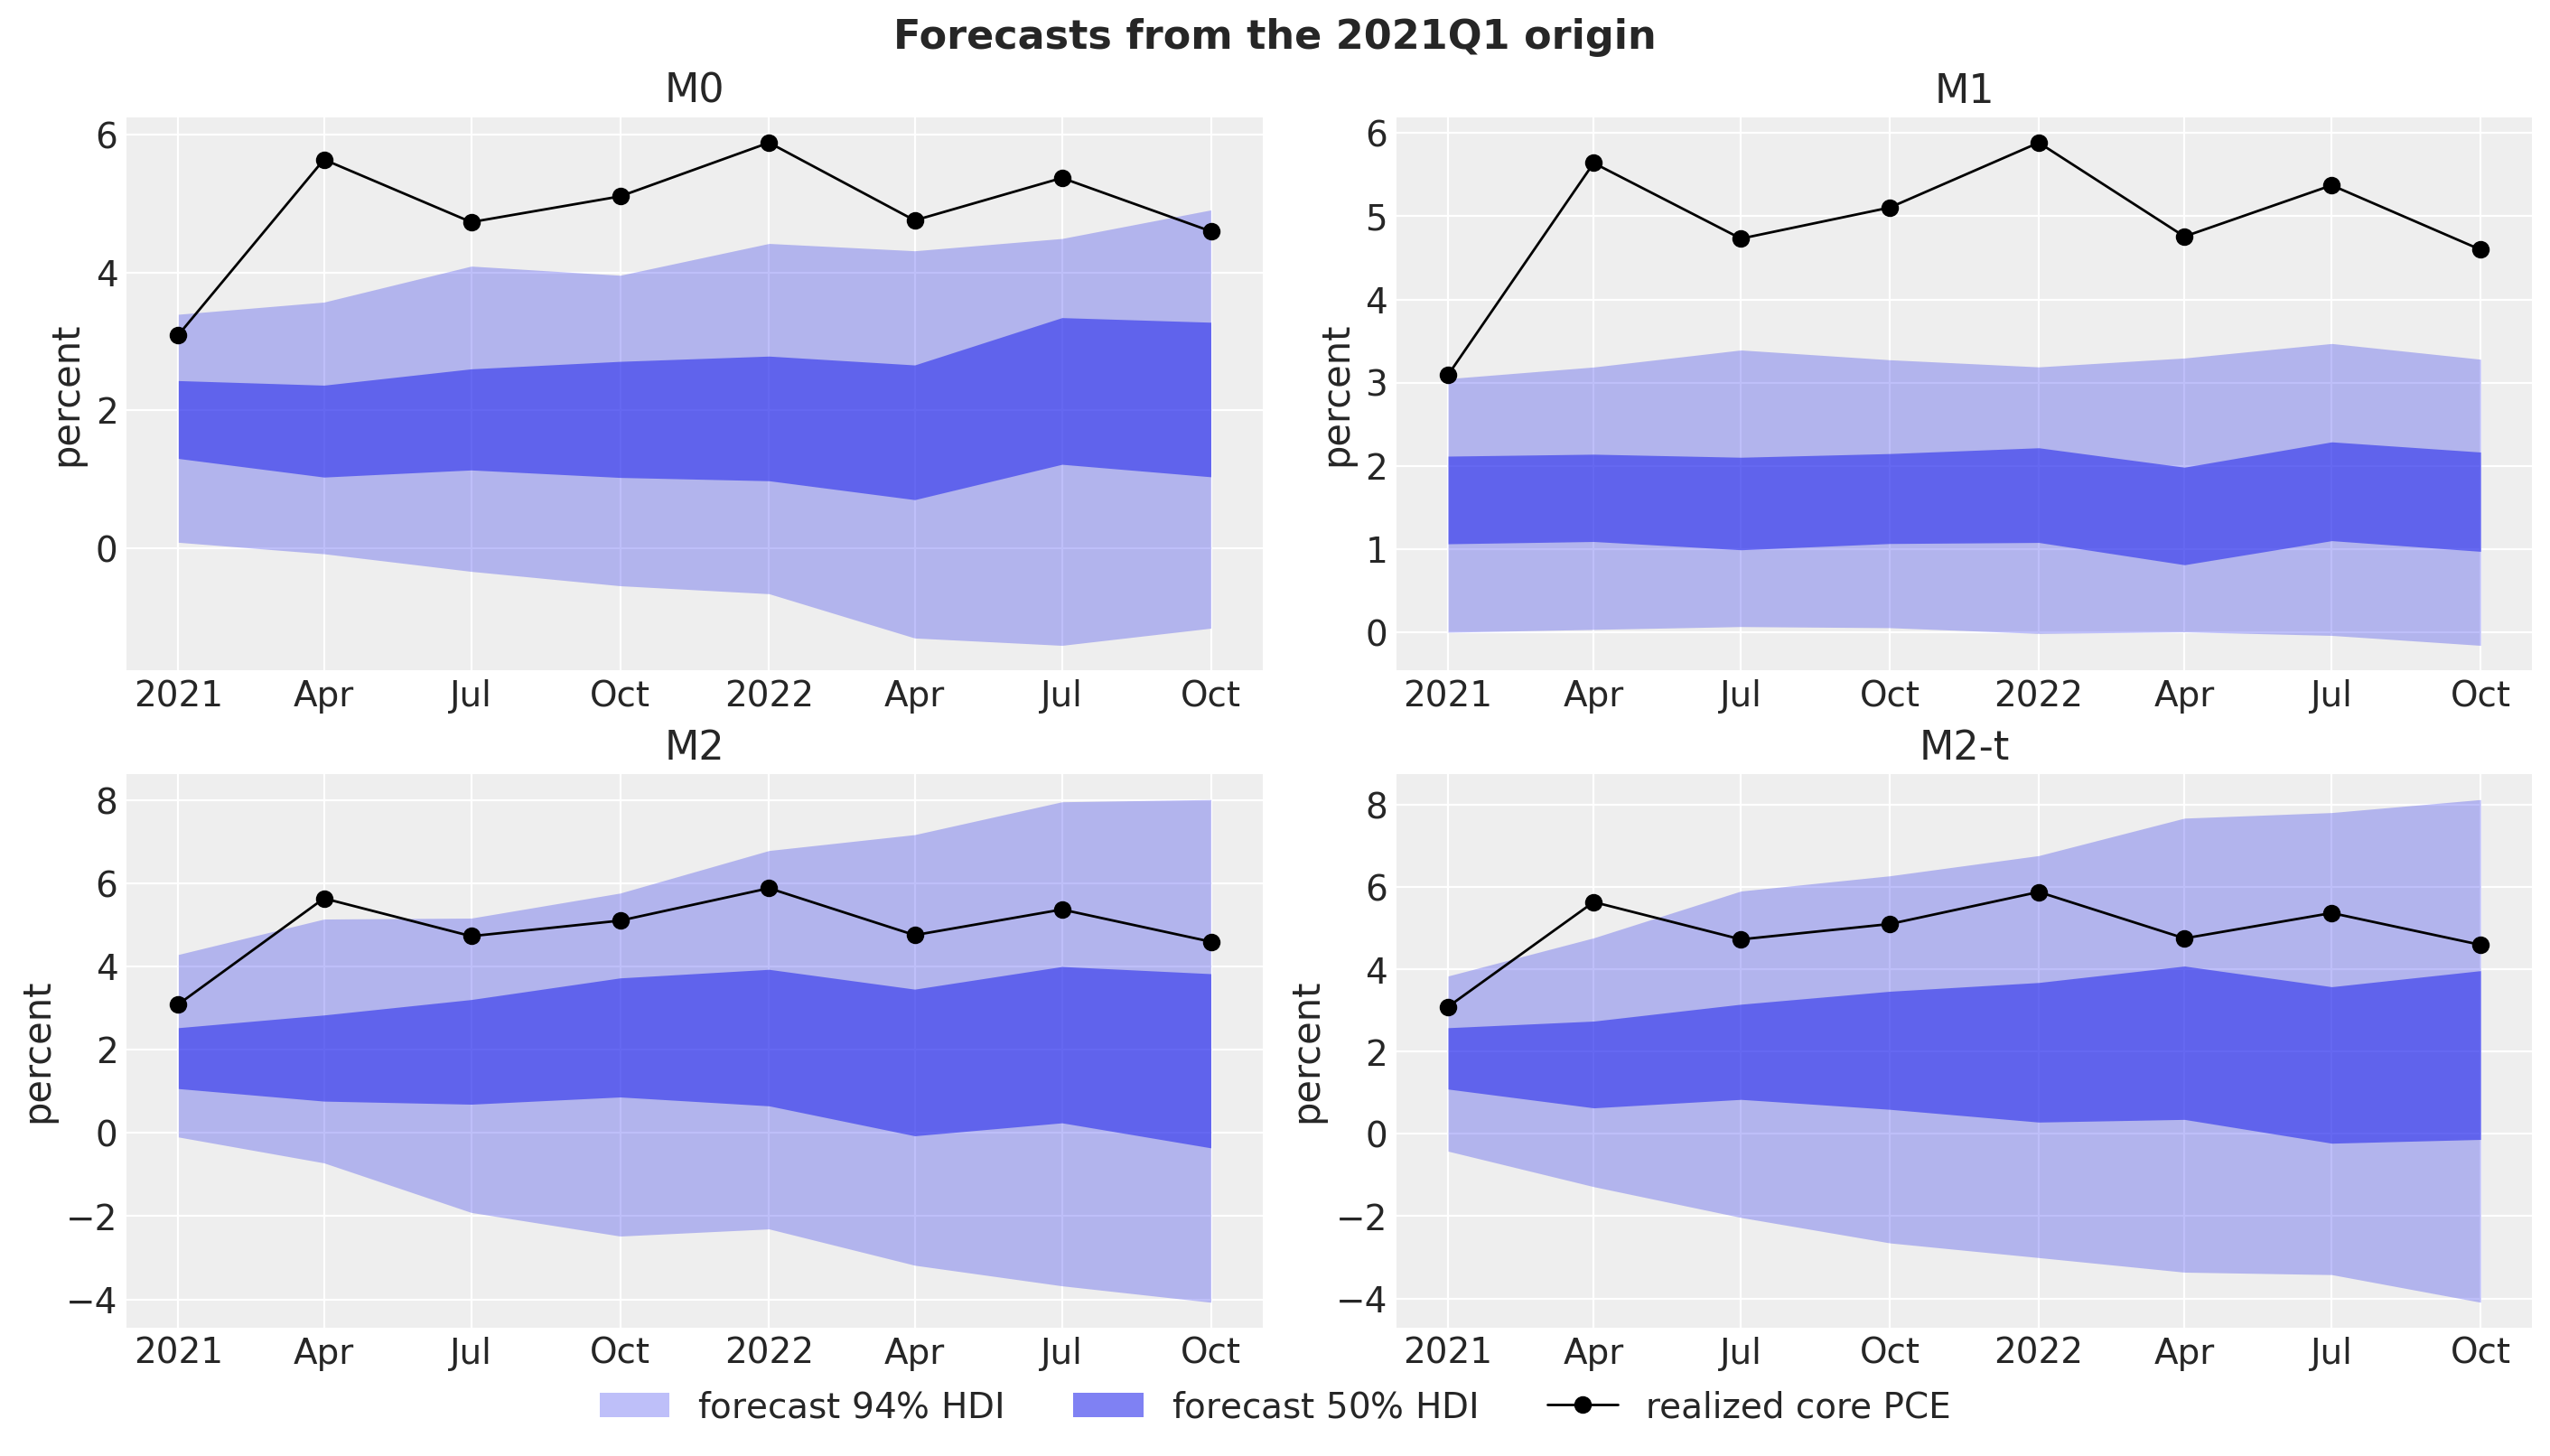

In [24]:
origin_2021 = int(np.flatnonzero(origins == np.datetime64("2021-01-01"))[0])
window = backtest_results["M2"][origin_2021]
window_dates = date_num[window.t1 : window.t2]
realized = rates[window.t1 : window.t2, -1]
draws_2021 = np.concatenate(
    [
        np.asarray(results[origin_2021].prediction)[..., -1:]
        for results in backtest_results.values()
    ],
    axis=-1,
)  # (samples, horizon, rungs): the core PCE draws of every rung from the 2021Q1 origin

pc, band_handles = plot_bands(
    draws_2021,
    window_dates,
    list(backtest_results),
    label="forecast ",
    col_wrap=2,
    figsize=(14, 8),
)
fig = pc.viz["figure"].item()

for ax, label in zip(fig.axes, backtest_results, strict=True):
    (realized_line,) = ax.plot(
        window_dates, realized, color="black", lw=1, marker="o", label="realized core PCE"
    )
    ax.set(title=label, ylabel="percent")

fig.legend(handles=[*band_handles, realized_line], loc="outside lower center", ncols=3)
fig.suptitle("Forecasts from the 2021Q1 origin", fontsize=16, fontweight="bold");

The surge is the window where the ladder matters most. After the first quarter, the realized core PCE rates run from $4.6\%$ to $5.9\%$:

- M0 and M1 forecast medians near $1.8\%$ and $1.6\%$ with $94\%$ bands that top out at $4.9\%$ and $3.5\%$. M1 covers none of the eight quarters, and M0 covers two, the first and the last.
- M2 forecasts the same median, $1.9\%$, but its $94\%$ band widens from $4.4$ points at one quarter to $12.1$ points at eight, and its upper edge rises to $8.0\%$. It covers seven of the eight quarters and misses only 2021Q2, the first surge quarter. M2-t gives the same picture.

The multi-measure models did not predict the surge: their medians are as low as the univariate ones, and no rung puts a single realized quarter inside its $50\%$ interval. M2 had a wider band in 2021Q1, because the trend volatility estimated from four measures was already high after 2020Q2. The CRPS gap between M1 ($2.8$) and M2 ($2.0$) at this origin comes from the width of the bands; the medians are the same.

The last check on the backtest is the fits themselves: the divergences of every window, per rung.

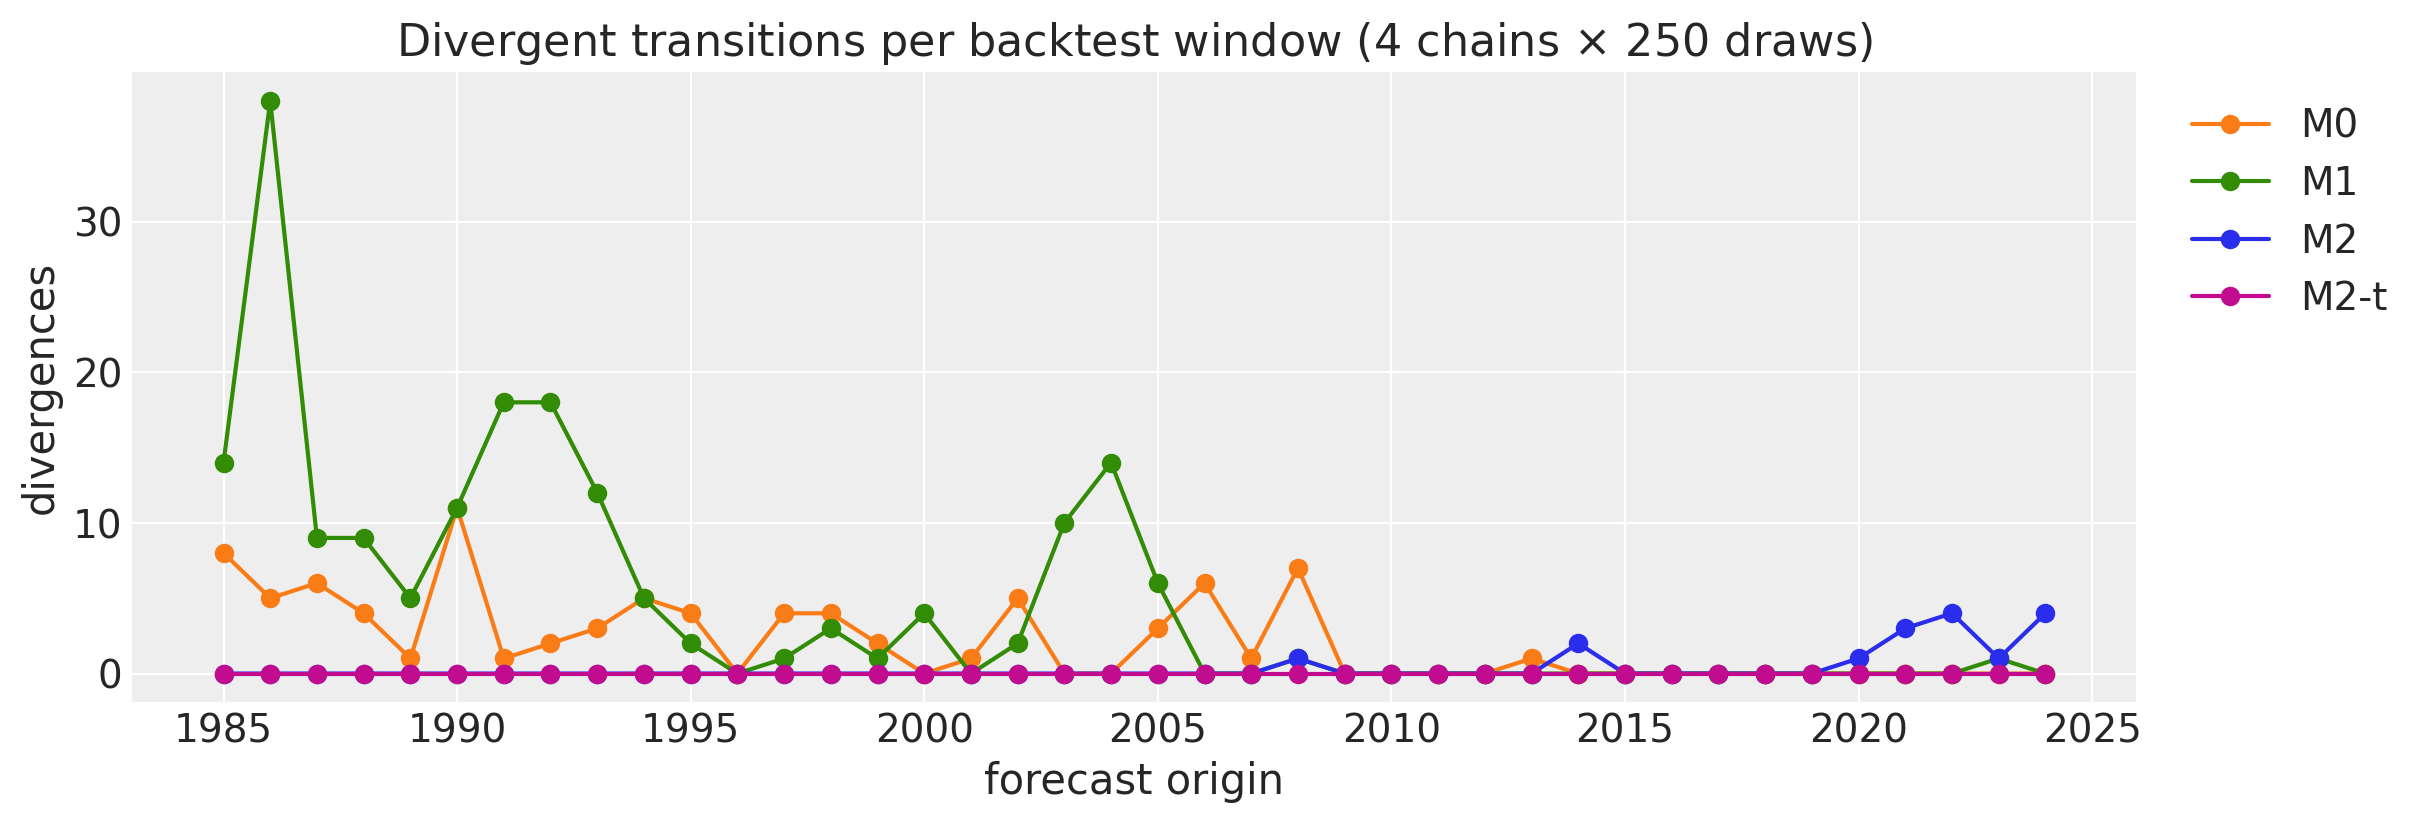

In [25]:
fig, ax = plt.subplots(figsize=(12, 4))

for label in backtest_results:
    rung_origins = [origin for rung, origin, _ in backtest_divergences if rung == label]
    counts = [count for rung, _, count in backtest_divergences if rung == label]
    ax.plot(rung_origins, counts, marker="o", color=RUNG_COLORS[label], label=label)

locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title=r"Divergent transitions per backtest window (4 chains $\times$ 250 draws)",
    xlabel="forecast origin",
    ylabel="divergences",
);

The two multi-measure rungs are clean: M2-t has no divergent transition in any window, and M2 has at most four in a window, with its counts at the 2008, 2014 and 2020 to 2024 origins. The two univariate rungs have divergences in the early windows: M1 has up to $38$ divergent draws of $1{,}000$ at the origins between 1985 and 1993 and $10$ to $14$ at the 2003 and 2004 origins, and M0 has up to $11$, at the 1985 and 1990 origins. A single series with a volatility random walk has the least information about its own scale, so its funnel is the widest, and the shortest windows are where it shows most. The counts are a few percent of the draws at most, and from 2009 on no rung has more than four in a window, so only the scores of M0 and M1 at the early origins rest on fits that are slightly worse than the others.

The M2-t rung has one parameter the others do not have, the degrees of freedom $\nu$ of its gaps, and the backtest fits do not keep it. We fit M2-t once on the full sample to read it.

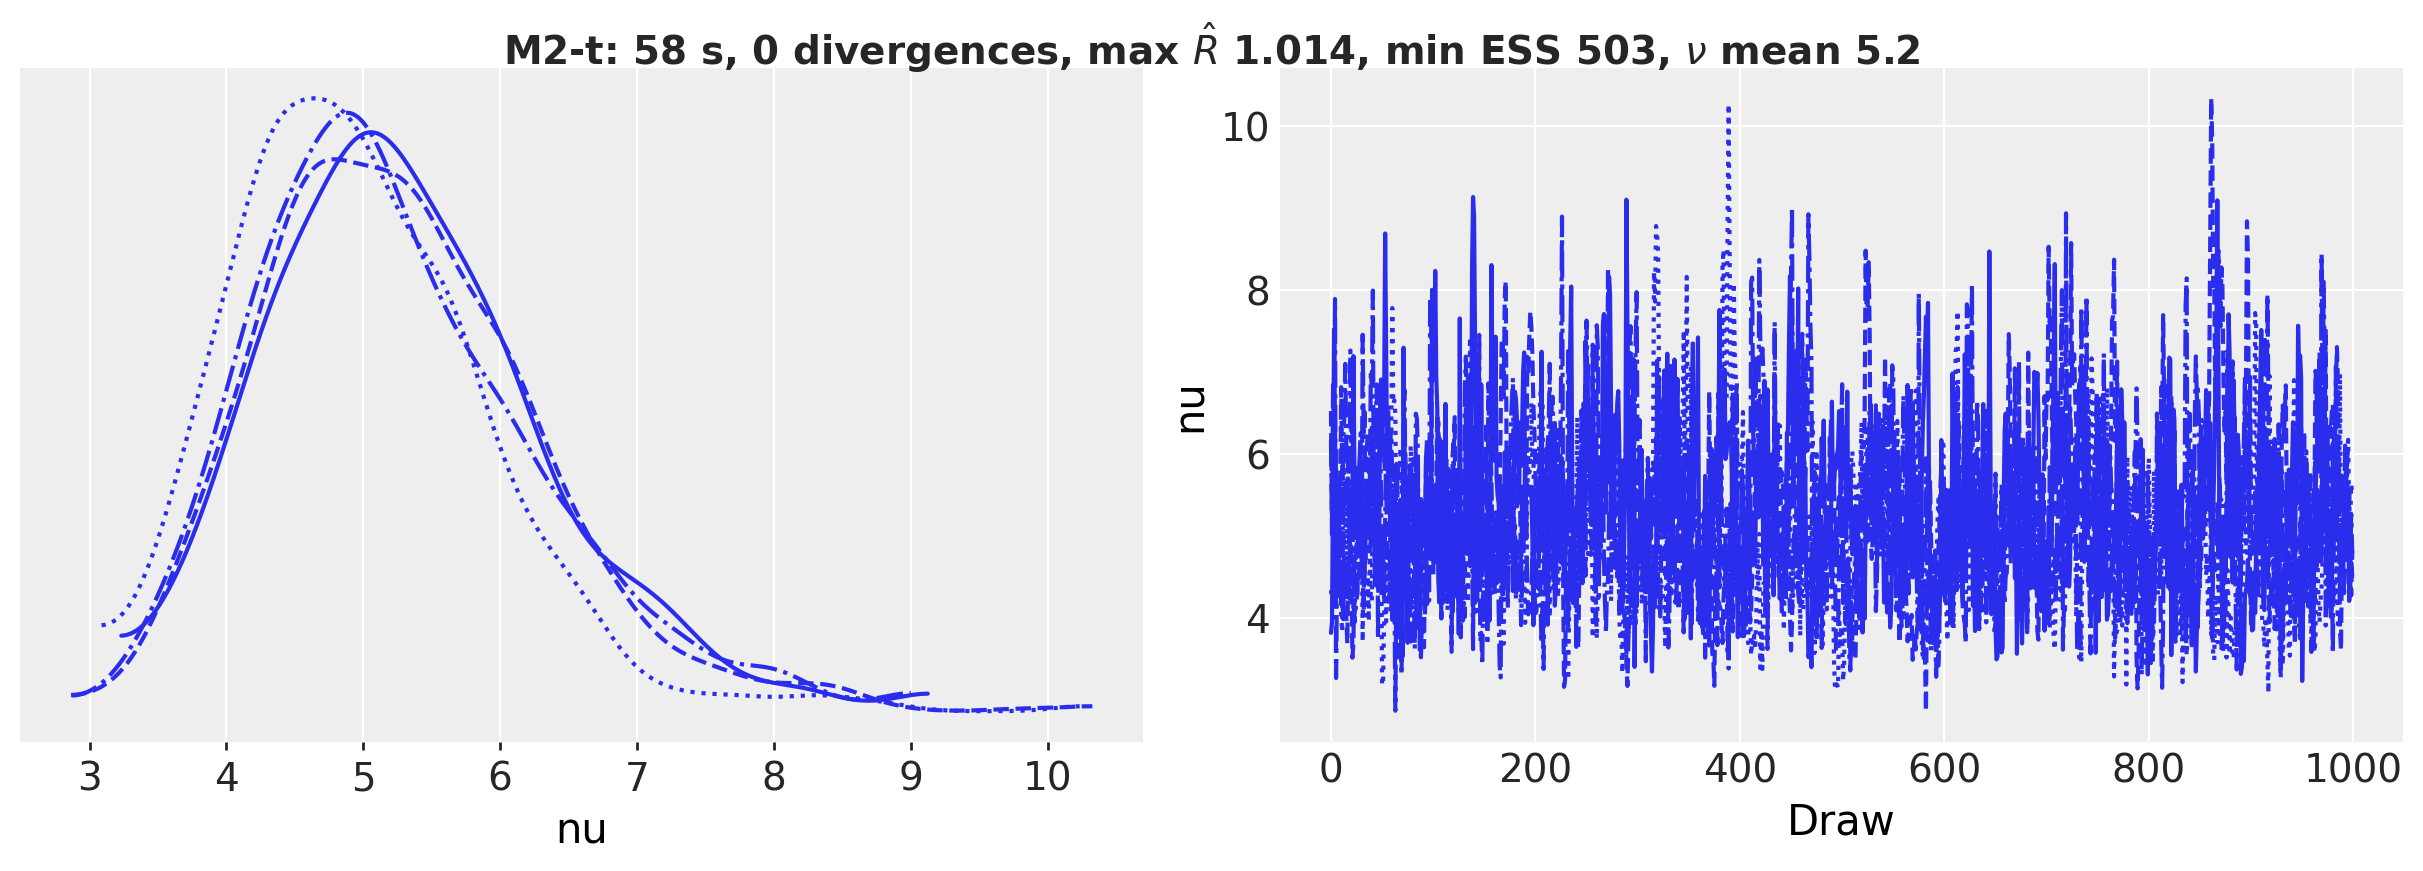

In [26]:
rng_key, key_fit, key_tree = random.split(rng_key, 3)
model_t = make_trend_inflation_model(num_measures, student_t=True)
mcmc_t, seconds_t = fit_nuts(
    key_fit, model_t, rates, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES
)
tree_t = export(key_tree, model_t, mcmc_t)

pc = az.plot_trace_dist(tree_t, var_names=["nu"], figure_kwargs={"figsize": (12, 4)})
pc.viz["figure"].item().suptitle(
    fit_title("M2-t", mcmc_t, seconds_t)
    + rf", $\nu$ mean {float(tree_t['posterior']['nu'].mean()):.1f}",
    fontsize=14,
    fontweight="bold",
    y=1.05,
);

The degrees of freedom have a posterior mean of $5.2$ and the four chains agree: no divergent transition, and a largest $\hat{R}$ of $1.014$ over the global parameters, just above the $1.01$ guideline. A Student-t with five degrees of freedom has tails well outside the Normal, so a quarter four scales away from the trend is an ordinary event instead of an impossible one. The data pull $\nu$ down from the prior center of $10$, which says that the measures have quarters, 2008Q4 and 2020Q2 among them, that Normal gaps with a slowly moving volatility cannot absorb. The backtest gain of M2-t over M2 is small because those quarters are few.

## Sensitivity to the vol-of-vol

$\gamma$ is the one number we fixed. Three checks say how much it matters:

- The posterior of the trend volatility under $\gamma \in \{0.05, 0.1, 0.2\}$, from three full fits.
- The backtest CRPS of M2 under the same three values.
- A fit that learns $\gamma$ with the prior $\gamma \sim \text{LogNormal}(\log 0.1, 0.3)$, whose central $94\%$ range is $0.056$ to $0.18$.

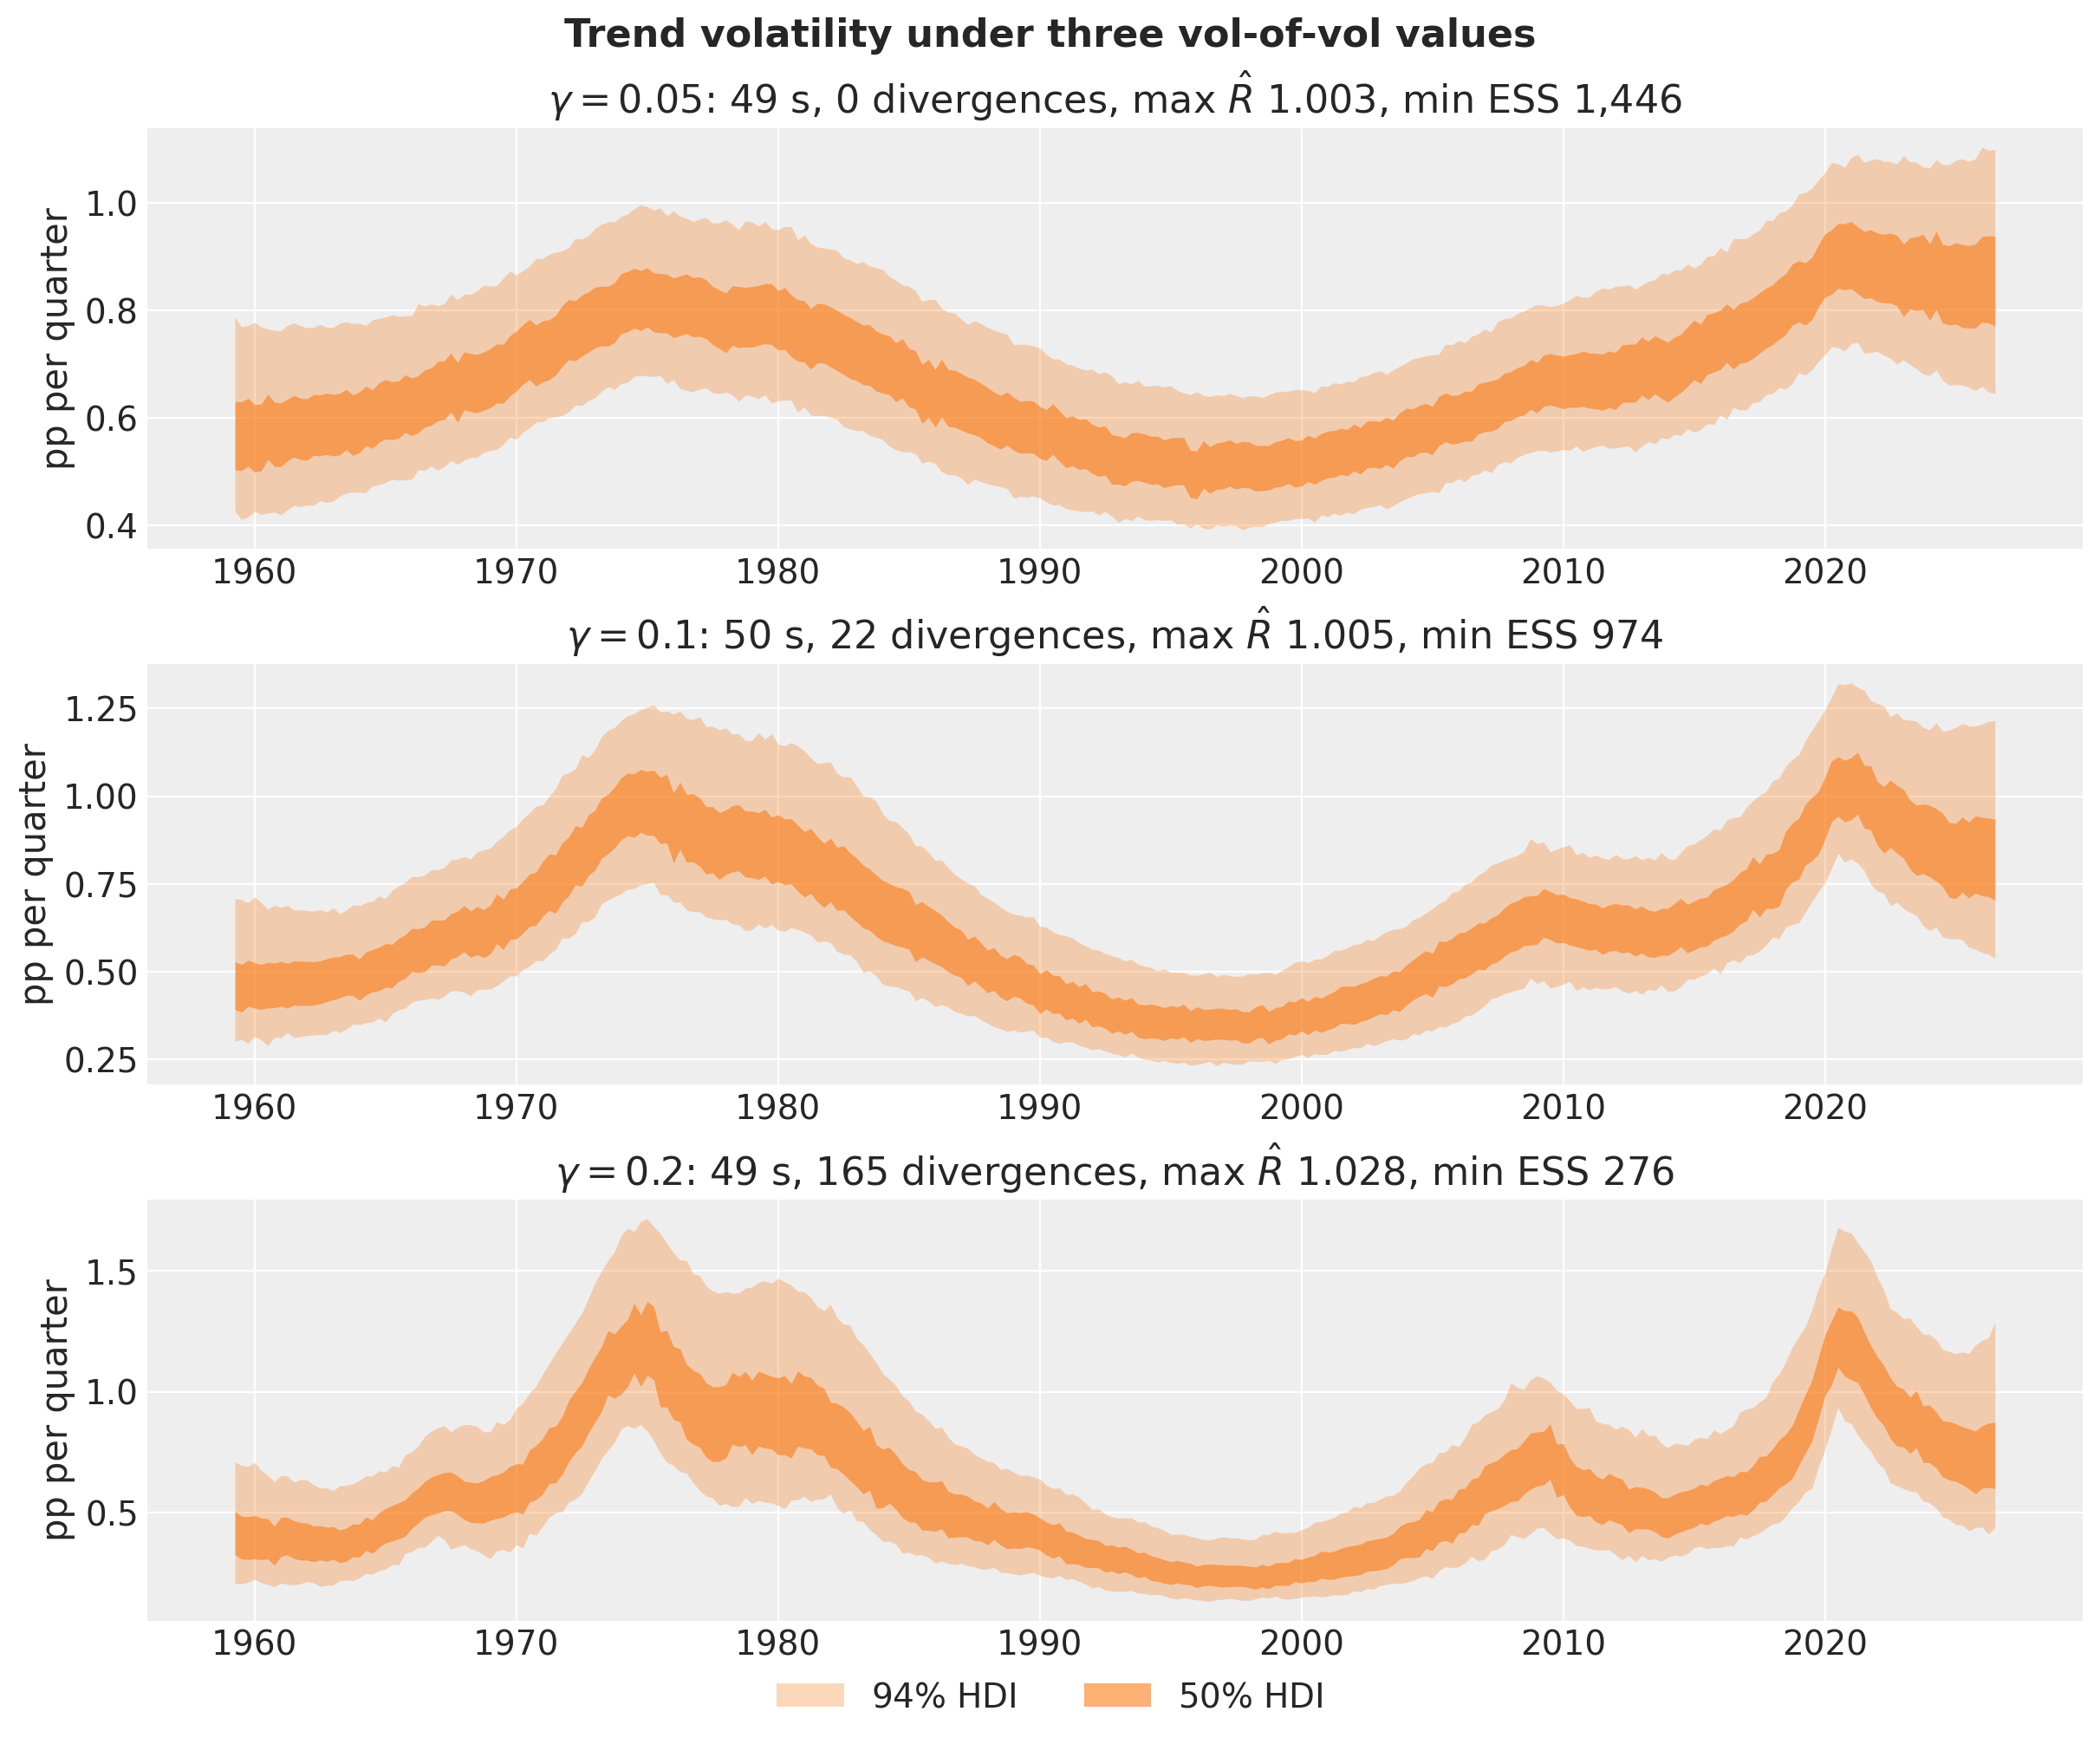

In [27]:
VOL_OF_VOL_GRID = (0.05, 0.1, 0.2)
grid_fits: dict[float, tuple[MCMC, float]] = {0.1: (mcmc, seconds)}

for gamma in VOL_OF_VOL_GRID:
    if gamma not in grid_fits:
        rng_key, key_fit = random.split(rng_key)
        grid_fits[gamma] = fit_nuts(
            key_fit,
            make_trend_inflation_model(num_measures, vol_of_vol=gamma),
            rates,
            num_warmup=FULL_WARMUP,
            num_samples=FULL_SAMPLES,
        )

grid_draws = np.concatenate(
    [np.asarray(grid_fits[gamma][0].get_samples()["trend_vol"]) for gamma in VOL_OF_VOL_GRID],
    axis=-1,
)  # (samples, quarters, 3): one column per gamma
pc, band_handles = plot_bands(
    grid_draws,
    date_num,
    [rf"$\gamma = {gamma}$" for gamma in VOL_OF_VOL_GRID],
    color="C1",
    figsize=(12, 10),
)
fig = pc.viz["figure"].item()

for ax, gamma in zip(fig.axes, VOL_OF_VOL_GRID, strict=True):
    ax.set(title=fit_title(rf"$\gamma = {gamma}$", *grid_fits[gamma]), ylabel="pp per quarter")

fig.legend(handles=band_handles, loc="outside lower center", ncols=2)
fig.suptitle("Trend volatility under three vol-of-vol values", fontsize=16, fontweight="bold");

The three fits agree on the shape of the trend volatility and disagree on its amplitude:

- With $\gamma = 0.05$ the path runs from $0.6$ in 1959 to $0.85$ in 1975, down to $0.5$ in 1997 and up to $0.9$ in 2021, a range of less than a factor of two, with no divergent transition and the largest effective sample size.
- With $\gamma = 0.1$ the range is $0.36$ to $1.06$, a factor of three, with $22$ divergent draws.
- With $\gamma = 0.2$ the path has sharper peaks, about $1.2$ in both 1975 and 2021, and a floor near $0.25$ in 1997, with $165$ divergent draws, a largest $\hat{R}$ of $1.028$ and a smallest effective sample size of $276$. A larger vol-of-vol lets every volatility path move faster, which deepens the funnel where a gap volatility approaches zero.

The slowest path is the easiest to sample. The next figure scores the three in the backtest.

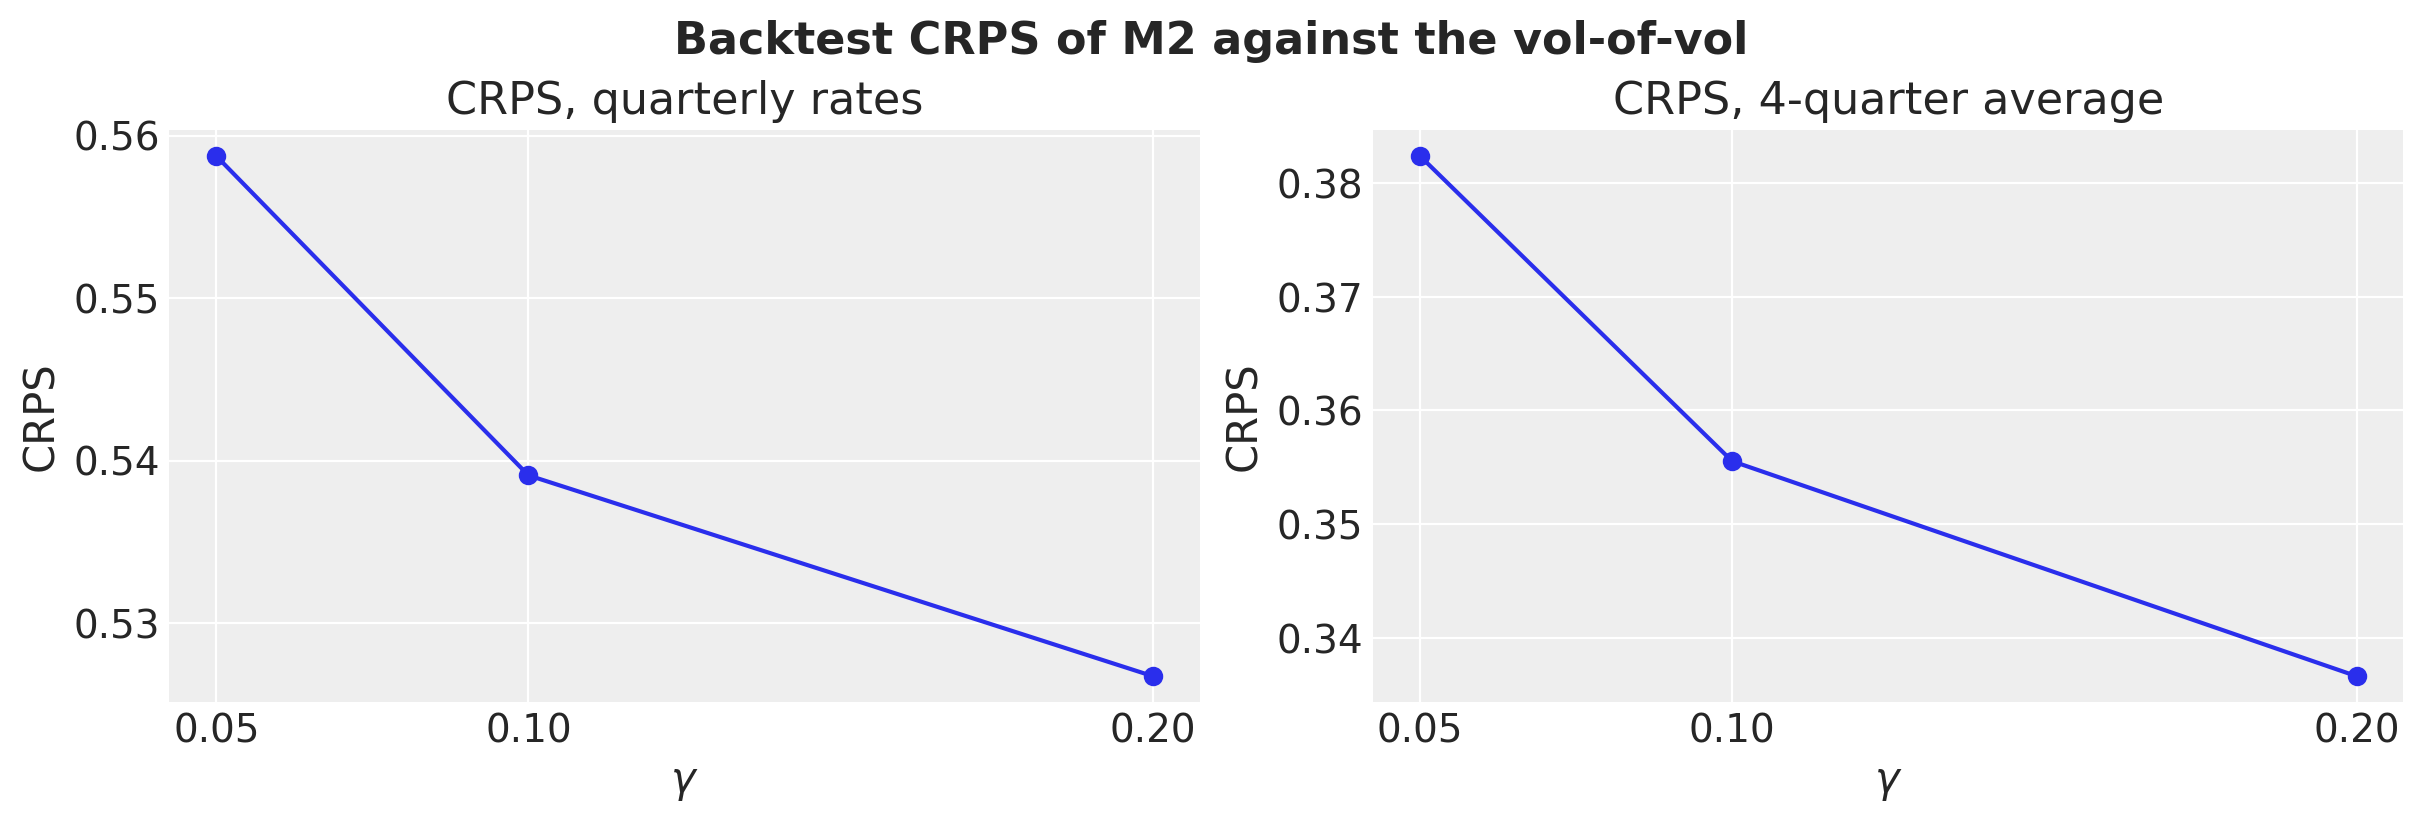

In [28]:
grid_results: dict[float, list[BacktestResult]] = {0.1: backtest_results["M2"]}

for gamma in VOL_OF_VOL_GRID:
    if gamma not in grid_results:
        rng_key, key_backtest = random.split(rng_key)
        grid_results[gamma] = run_backtest(
            key_backtest,
            f"M2 ($\\gamma = {gamma}$)",
            partial(make_trend_inflation_model, num_measures, vol_of_vol=gamma),
            rates,
        )

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4), layout="constrained")

for ax, metric, title in zip(
    axes, ("crps", "crps_4q"), ("quarterly rates", "4-quarter average"), strict=True
):
    means = [metric_values(grid_results[gamma], metric).mean() for gamma in VOL_OF_VOL_GRID]
    ax.plot(VOL_OF_VOL_GRID, means, marker="o", color="C0")
    ax.set(title=f"CRPS, {title}", xlabel=r"$\gamma$", xticks=VOL_OF_VOL_GRID, ylabel="CRPS")

fig.suptitle("Backtest CRPS of M2 against the vol-of-vol", fontsize=16, fontweight="bold");

The backtest prefers the faster volatility: the CRPS on the quarterly rates falls from $0.559$ at $\gamma = 0.05$ to $0.539$ at $0.1$ and $0.527$ at $0.2$, and on the 4-quarter average from $0.382$ to $0.356$ to $0.337$. The whole range is $0.03$, smaller than the M1 to M0 step. A larger $\gamma$ lets the volatility react faster after 2020, and the 2020 and 2021 windows dominate the averages, so the faster path scores better on average and pays for it with the sampling diagnostics of the previous figure. We keep $0.1$ as the value of the notebook, the order of magnitude Stock and Watson (2007) use on quarterly data, and the next figure shows what happens when the data choose.

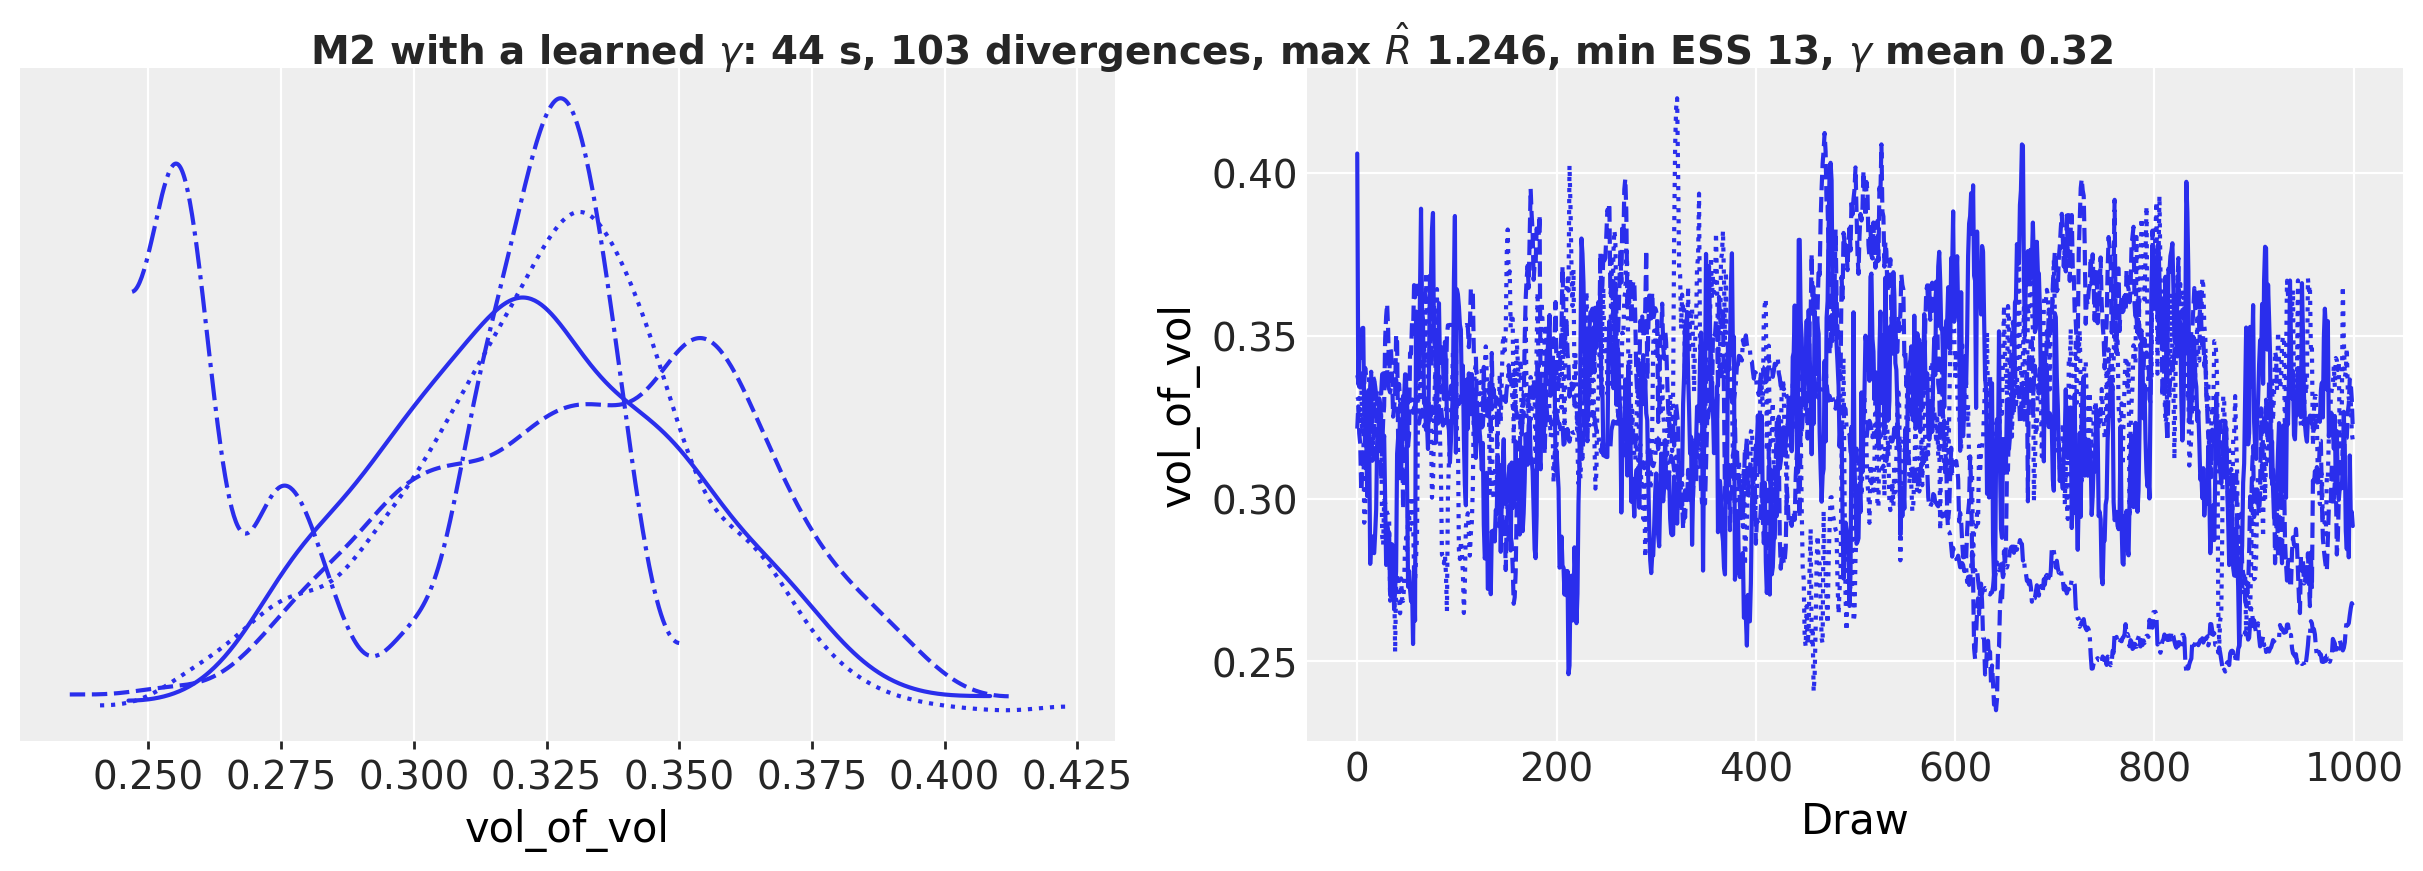

In [29]:
def learned_vol_of_vol_model(covariates: Array, data: Array | None = None) -> None:
    """M2 with the vol-of-vol as a parameter, shared by the trend and the gaps."""
    vol_of_vol = numpyro.sample("vol_of_vol", dist.LogNormal(jnp.log(0.1), 0.3))
    make_trend_inflation_model(num_measures, vol_of_vol=vol_of_vol)(covariates, data)


rng_key, key_fit, key_tree = random.split(rng_key, 3)
mcmc_learned, seconds_learned = fit_nuts(
    key_fit, learned_vol_of_vol_model, rates, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES
)
tree_learned = export(key_tree, learned_vol_of_vol_model, mcmc_learned)

pc = az.plot_trace_dist(tree_learned, var_names=["vol_of_vol"], figure_kwargs={"figsize": (12, 4)})
pc.viz["figure"].item().suptitle(
    fit_title(r"M2 with a learned $\gamma$", mcmc_learned, seconds_learned)
    + rf", $\gamma$ mean {float(tree_learned['posterior']['vol_of_vol'].mean()):.2f}",
    fontsize=14,
    fontweight="bold",
    y=1.05,
);

The fit with a learned $\gamma$ does not converge: the four chains land on different modes between $0.25$ and $0.35$, the largest $\hat{R}$ is $1.246$, the effective sample size of $\gamma$ is $13$ and $103$ transitions diverge. The posterior mean of $0.32$ is far above the prior center of $0.1$ and above the $97\%$ quantile of the prior ($0.18$): the likelihood pushes the vol-of-vol up as far as the prior allows. The funnel explains it: a larger $\gamma$ lets a gap volatility collapse to zero in the quiet quarters and the trend pass through those points exactly, which raises the likelihood without bound. Stock and Watson (2007) fix $\gamma$ for this reason, and so does this notebook. A prior that puts a floor under the gap volatility, or a vol-of-vol that differs between the trend and the gaps, are two ways to make $\gamma$ learnable.

## Cost

The full M2 fit and the backtests are the expensive parts of the notebook. We time one more full fit: the same model wrapped in [`time_reparam`](../../reference/reparam.time_reparam.html) with the discrete cosine transform, which rotates the in-sample innovation sites of a model so that a random walk with a learned step scale samples faster. Here the steps are already standardized, so the rotation has nothing to decorrelate, and the figure says what it costs.

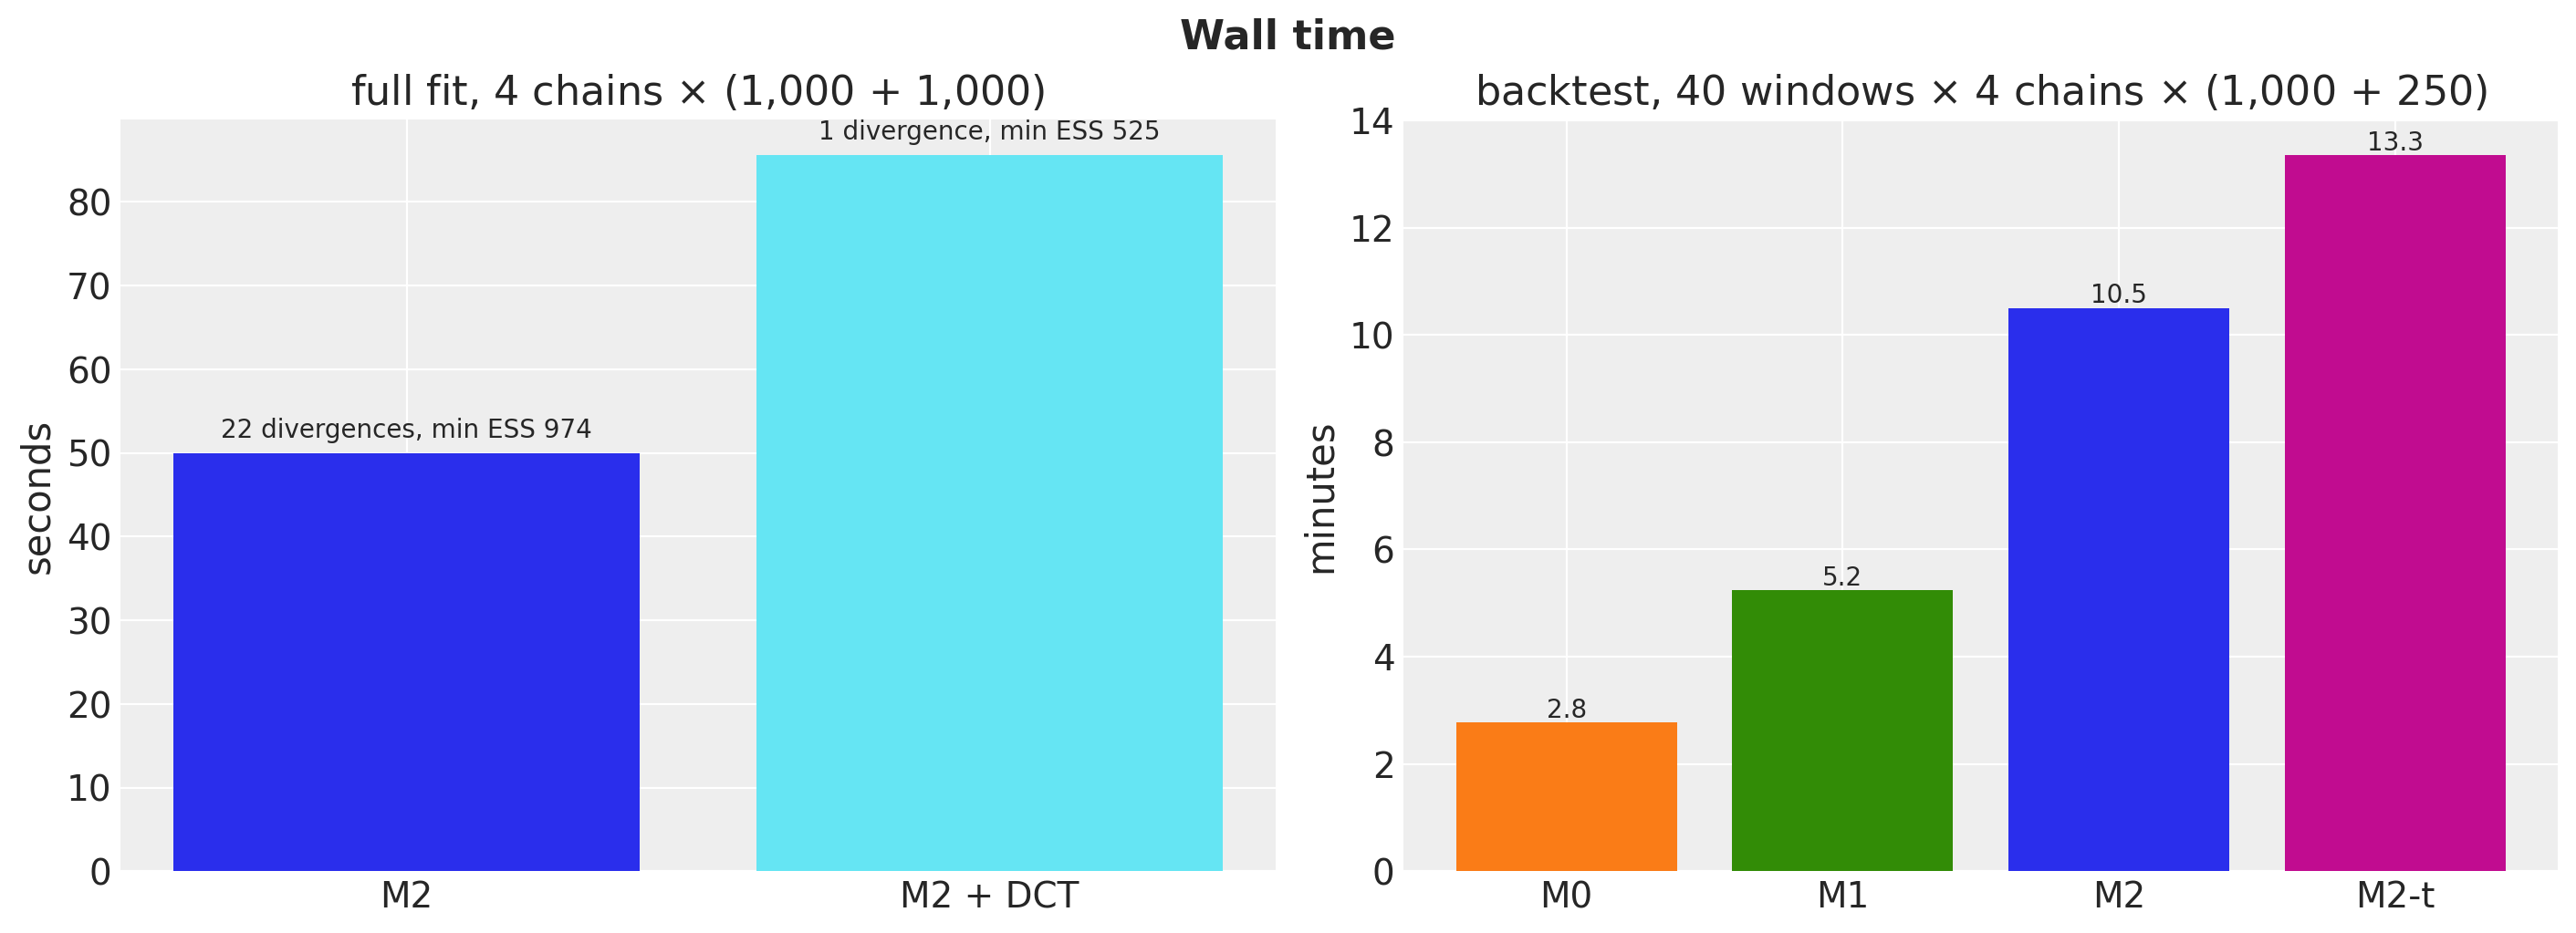

In [30]:
rng_key, key_fit = random.split(rng_key)
mcmc_dct, seconds_dct = fit_nuts(
    key_fit, time_reparam(model, "dct"), rates, num_warmup=FULL_WARMUP, num_samples=FULL_SAMPLES
)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5), layout="constrained")
full_fits = {"M2": (mcmc, seconds), "M2 + DCT": (mcmc_dct, seconds_dct)}
axes[0].bar(list(full_fits), [fit[1] for fit in full_fits.values()], color=["C0", "C5"])

for position, (fit, fit_seconds) in enumerate(full_fits.values()):
    r_hat, ess = diagnostics(fit)
    axes[0].annotate(
        f"{divergence_label(num_divergences(fit))}, min ESS {ess:,.0f}",
        (position, fit_seconds),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
    )

axes[0].set(title=r"full fit, 4 chains $\times$ (1,000 + 1,000)", ylabel="seconds")
backtest_seconds = {
    label: sum(result.walltime for result in results)
    for label, results in backtest_results.items()
}
bars = axes[1].bar(
    list(backtest_seconds),
    [seconds / 60 for seconds in backtest_seconds.values()],
    color=[RUNG_COLORS[label] for label in backtest_seconds],
)
axes[1].bar_label(bars, fmt="%.1f")
axes[1].set(
    title=r"backtest, 40 windows $\times$ 4 chains $\times$ (1,000 + 250)", ylabel="minutes"
)
fig.suptitle("Wall time", fontsize=16, fontweight="bold");

The M2 fit takes $50$ seconds for four chains of $1{,}000$ warmup and $1{,}000$ draws. The same model under the discrete cosine transform of `time_reparam` takes $86$ seconds, $1.7$ times as long, with one divergent transition instead of $22$ and a smaller effective sample size ($525$ against $974$): the innovation sites are already standardized, so the rotation has nothing to decorrelate, and the transform adds work to every gradient. The backtests take $2.8$ minutes (M0), $5.2$ (M1), $10.5$ (M2) and $13.3$ (M2-t) for 40 windows each, so the whole ladder runs in about half an hour with four chains in parallel.

## Discussion

- **Four measures give a core PCE trend with a wider band.** Core PCE has the smallest gap volatility at every date, $0.2$ percentage points at the end of the sample, so the common trend tracks it almost one for one. The other three measures change the volatility estimate: the trend volatility since 2020 is about $0.9$ to $1.1$ points per quarter. In the backtest, that extra width saves the 2021 windows and costs the 2009 to 2018 ones.
- **Stochastic volatility pays.** M1 beats M0 by $0.051 \pm 0.035$ CRPS, improves every score, and beats the Atkeson and Ohanian benchmark on the 4-quarter MAE ($0.405$ against $0.450$). The 1970s, the Great Moderation and the 2020s need three different volatility levels, and a model with one scale for the whole sample cannot fit all three.
- **Pooling does not help on average.** M2 scores $0.033 \pm 0.055$ CRPS worse than M1 over the 40 windows and loses to the benchmark on the 4-quarter MAE. Its gain is concentrated at the 2020 and 2021 origins, where its wider bands cover the surge that no rung's median predicted.
- **The $50\%$ intervals are too wide beyond one quarter**, while the $94\%$ intervals are calibrated: the center of the forecast distribution spreads too fast. A trend with some mean reversion is the first change to try.

Open weaknesses of the model:

- **$\gamma$ is fixed.** Under a prior, $\gamma$ runs to the edge of the prior with four disagreeing chains, so the value is a judgment, and the backtest ranks $0.2$ above $0.1$ above $0.05$ within $0.03$ CRPS. A floor on the gap volatility, or separate vol-of-vol values for the trend and the gaps, would make $\gamma$ learnable and may remove the divergences at the same time.
- **Independent gaps.** The model treats the gaps as independent across measures, but CPI and PCE share the energy component, and core CPI is a part of CPI. The 2008Q4 peak in the two headline gap volatilities is that shared component absorbed by two independent noises; a common factor for the headline gaps, as in Stock and Watson (2016), would separate it from the trend.
- **Constant offsets.** The CPI to PCE wedge has moved with the index methodologies (rental equivalence entered the CPI in 1983), and a slowly moving offset would take that out of the gaps.
- **Student-t gaps are not an outlier model.** M2-t improves the CRPS by $0.007$, and with $\nu = 5$ the trend still dips to $-0.8\%$ in 2020Q2. An explicit outlier component, a mixture on the gap, would keep the trend at its 2020Q1 level through that quarter.
- **The October 2025 CPI is interpolated.** The two CPI series carry a filled month in 2025Q4, so their 2025Q4 and 2026Q1 rates depend on the interpolation instead of on a published value.

Fairness notes on the evaluation:

- No information about the forecast horizon enters any model: the windows expand to the origin and the forecast uses the posterior at the origin only.
- The data are the revised series as published on 2026-11-08, not the vintages a forecaster had at each origin. Revised data make every model and the benchmark look better than they would have in real time, and the PCE revisions are larger than the CPI ones, so the comparison with Atkeson and Ohanian (2001), who used real-time data, is not exact.
- The 40 windows overlap by four quarters each, so the standard errors of the paired differences are understated, and the 2020 to 2021 windows carry a large share of every mean.

## References

- Atkeson, A., Ohanian, L. E. (2001). [*Are Phillips curves useful for forecasting inflation?*](https://www.minneapolisfed.org/research/quarterly-review/are-phillips-curves-useful-for-forecasting-inflation). Federal Reserve Bank of Minneapolis Quarterly Review, 25(1).
- Clark, T. E. (2011). [*Real-time density forecasts from Bayesian vector autoregressions with stochastic volatility*](https://doi.org/10.1198/jbes.2010.09248). Journal of Business & Economic Statistics, 29(3).
- Gneiting, T., Raftery, A. E. (2007). [*Strictly proper scoring rules, prediction, and estimation*](https://doi.org/10.1198/016214506000001437). Journal of the American Statistical Association, 102(477).
- Mertens, E. (2016). [*Measuring the level and uncertainty of trend inflation*](https://doi.org/10.1162/REST_a_00549). Review of Economics and Statistics, 98(5).
- Stock, J. H., Watson, M. W. (2007). [*Why has U.S. inflation become harder to forecast?*](https://doi.org/10.1111/j.1538-4616.2007.00014.x). Journal of Money, Credit and Banking, 39(s1).
- Stock, J. H., Watson, M. W. (2016). [*Core inflation and trend inflation*](https://doi.org/10.1162/REST_a_00608). Review of Economics and Statistics, 98(4).
- Data: U.S. Bureau of Labor Statistics, [CPIAUCSL](https://fred.stlouisfed.org/series/CPIAUCSL) and [CPILFESL](https://fred.stlouisfed.org/series/CPILFESL); U.S. Bureau of Economic Analysis, [PCEPI](https://fred.stlouisfed.org/series/PCEPI) and [PCEPILFE](https://fred.stlouisfed.org/series/PCEPILFE); all retrieved from FRED, Federal Reserve Bank of St. Louis, on 2026-11-08.
- Related examples: [vector autoregression](var.html), [univariate forecasting](forecasting_univariate.html).